In [1]:

import sys
import platform

print("Python version:", sys.version)
print("Operating system:", platform.system())

try:
    import cv2
    print("OpenCV version:", cv2.__version__)
except ImportError:
    print("OpenCV is not installed.")

try:
    import numpy as np
    print("NumPy version:", np.__version__)
except ImportError:
    print("NumPy is not installed.")

try:
    import matplotlib
    print("Matplotlib version:", matplotlib.__version__)
except ImportError:
    print("Matplotlib is not installed.")


Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Operating system: Linux
OpenCV version: 4.14.0
NumPy version: 2.1.3
Matplotlib version: 3.10.0


In [2]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU. We can still begin with OpenCV.")


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU name: Tesla T4


In [3]:

from google.colab import files

uploaded = files.upload()


Saving WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg to WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg


Image loaded successfully!
Image dimensions: (1124, 1599, 3)
Image height: 1124 pixels
Image width: 1599 pixels


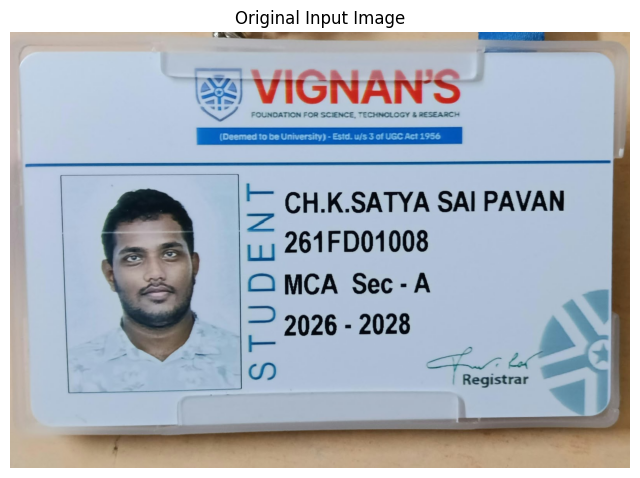

In [4]:

import cv2
import matplotlib.pyplot as plt

image_path = "WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg"

image = cv2.imread(image_path)

if image is None:
    print("Error: Image could not be loaded.")
else:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    print("Image loaded successfully!")
    print("Image dimensions:", image.shape)
    print("Image height:", image.shape[0], "pixels")
    print("Image width:", image.shape[1], "pixels")

    plt.figure(figsize=(8, 6))
    plt.imshow(image_rgb)
    plt.title("Original Input Image")
    plt.axis("off")
    plt.show()


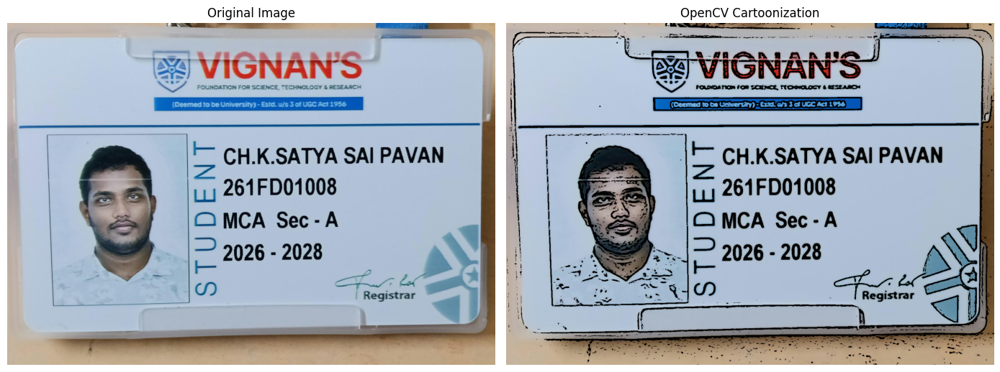

Cartoonization completed!
Saved as: opencv_cartoon.png


In [5]:

import cv2
import matplotlib.pyplot as plt

# 1. Read the original image
image = cv2.imread(image_path)

# 2. Smooth the image while preserving edges
smooth = cv2.bilateralFilter(
    image,
    d=9,
    sigmaColor=250,
    sigmaSpace=250
)

# 3. Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# 4. Reduce noise
gray = cv2.medianBlur(gray, 7)

# 5. Detect edges
edges = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    9,
    2
)

# 6. Convert edges to 3 channels
edges_color = cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)

# 7. Combine smooth colors with dark outlines
cartoon = cv2.bitwise_and(smooth, edges_color)

# 8. Display original and cartoon images
original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
cartoon_rgb = cv2.cvtColor(cartoon, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cartoon_rgb)
plt.title("OpenCV Cartoonization")
plt.axis("off")

plt.tight_layout()
plt.show()

# 9. Save the result
output_path = "opencv_cartoon.png"
cv2.imwrite(output_path, cartoon)

print("Cartoonization completed!")
print("Saved as:", output_path)


In [6]:

from google.colab import files

files.download("opencv_cartoon.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

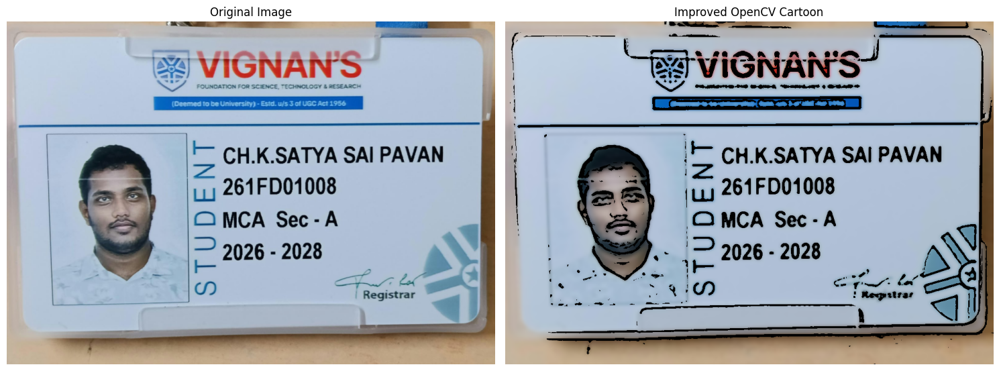

Improved output saved as opencv_cartoon_v2.png


In [7]:

import cv2
import matplotlib.pyplot as plt

image = cv2.imread(image_path)

# Resize for faster processing during testing
h, w = image.shape[:2]
scale = min(1.0, 1000 / max(h, w))
small = cv2.resize(
    image, (int(w * scale), int(h * scale)),
    interpolation=cv2.INTER_AREA
)

# Smooth colors while preserving important edges
smooth = cv2.bilateralFilter(
    small, d=9, sigmaColor=180, sigmaSpace=180
)
smooth = cv2.bilateralFilter(
    smooth, d=9, sigmaColor=180, sigmaSpace=180
)

# Detect cleaner edges
gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
gray = cv2.medianBlur(gray, 7)

edges = cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    11, 5
)

# Combine smoothed colors with outlines
cartoon = cv2.bitwise_and(
    smooth, smooth, mask=edges
)

# Display comparison
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(small, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(cartoon, cv2.COLOR_BGR2RGB))
plt.title("Improved OpenCV Cartoon")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite("opencv_cartoon_v2.png", cartoon)
print("Improved output saved as opencv_cartoon_v2.png")


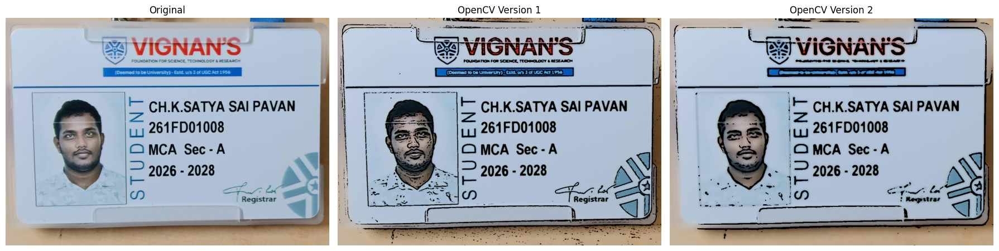

In [8]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path

original = cv2.imread(image_path)
cartoon_v1 = cv2.imread("opencv_cartoon.png")
cartoon_v2 = cv2.imread("opencv_cartoon_v2.png")

images = [
    ("Original", original),
    ("OpenCV Version 1", cartoon_v1),
    ("OpenCV Version 2", cartoon_v2)
]

plt.figure(figsize=(18, 6))

for i, (title, img) in enumerate(images, start=1):
    if img is None:
        print(f"Could not load: {title}")
        continue

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 3, i)
    plt.imshow(img_rgb)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:

import pandas as pd

results = pd.DataFrame([
    {
        "method": "OpenCV Cartoonization",
        "version": "V1",
        "input_image": image_path,
        "output_image": "opencv_cartoon.png",
        "status": "Generated",
        "notes": "Bilateral filter and adaptive threshold edges"
    },
    {
        "method": "OpenCV Cartoonization",
        "version": "V2",
        "input_image": image_path,
        "output_image": "opencv_cartoon_v2.png",
        "status": "Generated",
        "notes": "Repeated bilateral filtering and revised edge mask"
    }
])

results.to_csv("experiment_log.csv", index=False)

print(results.to_string(index=False))
print("\nExperiment log saved as experiment_log.csv")


               method version                                   input_image          output_image    status                                              notes
OpenCV Cartoonization      V1 WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg    opencv_cartoon.png Generated      Bilateral filter and adaptive threshold edges
OpenCV Cartoonization      V2 WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg opencv_cartoon_v2.png Generated Repeated bilateral filtering and revised edge mask

Experiment log saved as experiment_log.csv


In [10]:

from google.colab import files

uploaded_images = files.upload()

print("\nUploaded files:")
for filename in uploaded_images:
    print("-", filename)


Saving WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg to WhatsApp Image 2026-10-12 at 10.16.59 PM (1).jpeg

Uploaded files:
- WhatsApp Image 2026-10-12 at 10.16.59 PM (1).jpeg


In [11]:

from PIL import Image
from IPython.display import display

filename = "images[1]"

try:
    img = Image.open(filename)
    print("Image format:", img.format)
    print("Image dimensions:", img.size)
    print("Image mode:", img.mode)
    display(img)
except Exception as e:
    print("Could not read the file as an image.")
    print("Error:", e)


Could not read the file as an image.
Error: [Errno 2] No such file or directory: 'images[1]'


In [12]:

import cv2
import matplotlib.pyplot as plt

input_path = "images[1]"
image = cv2.imread(input_path)

if image is None:
    print("Error: Could not load image.")
else:
    # Smooth colors
    smooth = cv2.bilateralFilter(
        image, 9, 180, 180
    )

    smooth = cv2.bilateralFilter(
        smooth, 9, 180, 180
    )

    # Detect edges
    gray = cv2.cvtColor(
        image, cv2.COLOR_BGR2GRAY
    )
    gray = cv2.medianBlur(gray, 7)

    edges = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY,
        11, 5
    )

    # Combine colors and edges
    cartoon = cv2.bitwise_and(
        smooth, smooth, mask=edges
    )

    # Display comparison
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Original Image 2")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(cartoon, cv2.COLOR_BGR2RGB))
    plt.title("Cartoonized Image 2")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    cv2.imwrite("image2_cartoon.png", cartoon)
    print("Saved: image2_cartoon.png")


Error: Could not load image.


In [13]:

import os

print("Image files currently in Colab:\n")

for filename in os.listdir("."):
    if filename.lower().endswith(
        (".jpg", ".jpeg", ".png", ".webp")
    ):
        print(filename)


Image files currently in Colab:

opencv_cartoon.png
WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg
opencv_cartoon_v2.png
WhatsApp Image 2026-10-12 at 10.16.59 PM (1).jpeg


In [14]:

import cv2
import os
import time
import pandas as pd

def cartoonize_image(image):
    start_time = time.perf_counter()

    # Smooth colors
    smooth = cv2.bilateralFilter(
        image, 9, 180, 180
    )
    smooth = cv2.bilateralFilter(
        smooth, 9, 180, 180
    )

    # Detect edges
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 7)

    edges = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY,
        11, 5
    )

    # Combine smooth colors and edges
    cartoon = cv2.bitwise_and(
        smooth, smooth, mask=edges
    )

    elapsed = time.perf_counter() - start_time
    return cartoon, elapsed


print("Reusable cartoonization function created!")


Reusable cartoonization function created!


In [15]:

import os
import cv2
import pandas as pd

# Create a folder for the results
os.makedirs("cartoon_outputs", exist_ok=True)

# Include only original input images
input_files = [
    "WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg",
    "images[1]"
]

experiment_results = []

for filename in input_files:
    image = cv2.imread(filename)

    if image is None:
        print("Skipping unreadable file:", filename)
        continue

    cartoon, elapsed = cartoonize_image(image)

    output_name = (
        os.path.splitext(os.path.basename(filename))[0]
        + "_cartoon.png"
    )
    output_path = os.path.join("cartoon_outputs", output_name)

    cv2.imwrite(output_path, cartoon)

    experiment_results.append({
        "input_image": filename,
        "output_image": output_path,
        "width": image.shape[1],
        "height": image.shape[0],
        "runtime_seconds": elapsed,
        "method": "OpenCV"
    })

    print(f"Processed: {filename} | {elapsed:.4f} seconds")

results_df = pd.DataFrame(experiment_results)
results_df.to_csv(
    "cartoon_outputs/experiment_results.csv",
    index=False
)

print("\nExperiment results:")
print(results_df.to_string(index=False))
print("\nResults saved in cartoon_outputs/")


Processed: WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg | 0.5294 seconds
Skipping unreadable file: images[1]

Experiment results:
                                  input_image                                                         output_image  width  height  runtime_seconds method
WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg cartoon_outputs/WhatsApp Image 2026-10-12 at 10.16.59 PM_cartoon.png   1599    1124         0.529417 OpenCV

Results saved in cartoon_outputs/


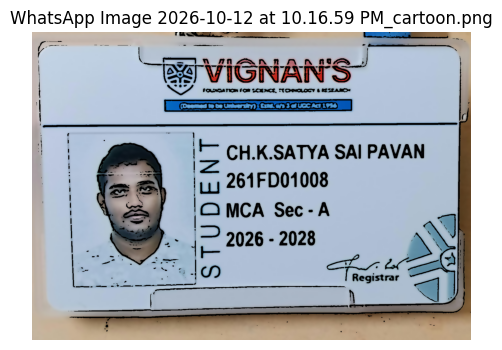

WhatsApp Image 2026-10-12 at 10.16.59 PM_cartoon.png | Dimensions: 1599 x 1124


In [16]:

import os
import cv2
import matplotlib.pyplot as plt

output_dir = "cartoon_outputs"

for filename in os.listdir(output_dir):
    if filename.endswith("_cartoon.png"):
        path = os.path.join(output_dir, filename)
        image = cv2.imread(path)

        if image is None:
            print("Invalid output:", filename)
            continue

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(6, 4))
        plt.imshow(image_rgb)
        plt.title(filename)
        plt.axis("off")
        plt.show()

        print(
            filename,
            "| Dimensions:",
            image.shape[1], "x", image.shape[0]
        )


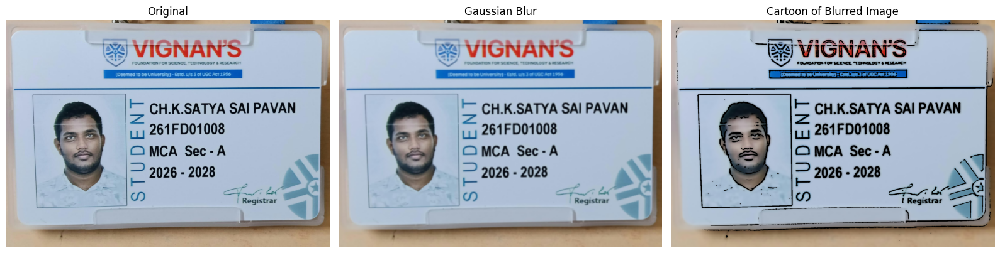

Blurred-image cartoonization runtime: 0.5120 seconds
Saved: blurred_original.png and blurred_cartoon.png


In [17]:

import cv2
import matplotlib.pyplot as plt

# Load the original photograph
image = cv2.imread(image_path)

# Create a blurred version
blurred = cv2.GaussianBlur(
    image,
    (9, 9),
    sigmaX=2
)

# Cartoonize the blurred image using our existing function
blurred_cartoon, runtime = cartoonize_image(blurred)

# Save the results
cv2.imwrite("blurred_original.png", blurred)
cv2.imwrite("blurred_cartoon.png", blurred_cartoon)

# Display the comparison
images = [
    ("Original", image),
    ("Gaussian Blur", blurred),
    ("Cartoon of Blurred Image", blurred_cartoon)
]

plt.figure(figsize=(16, 6))

for i, (title, img) in enumerate(images, start=1):
    plt.subplot(1, 3, i)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print(f"Blurred-image cartoonization runtime: {runtime:.4f} seconds")
print("Saved: blurred_original.png and blurred_cartoon.png")


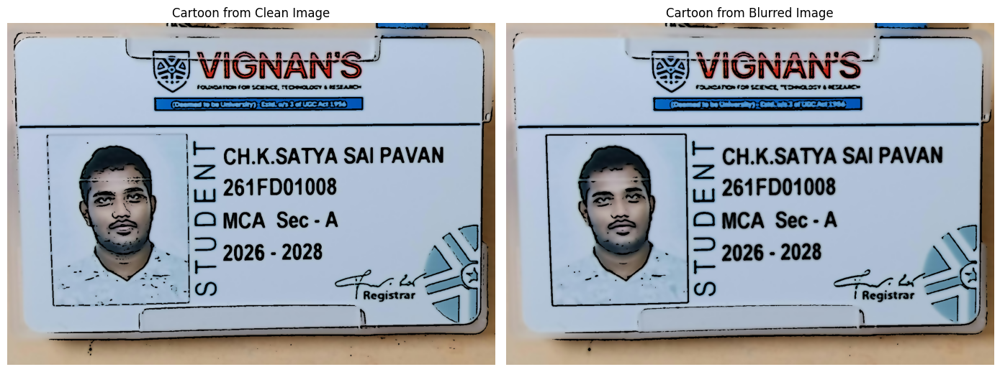

Comparison completed.


In [18]:

import cv2
import matplotlib.pyplot as plt

original_cartoon = cv2.imread("cartoon_outputs/WhatsApp Image 2026-10-12 at 10.16.59 PM_cartoon.png")
blurred_cartoon = cv2.imread("blurred_cartoon.png")

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(original_cartoon, cv2.COLOR_BGR2RGB))
plt.title("Cartoon from Clean Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(blurred_cartoon, cv2.COLOR_BGR2RGB))
plt.title("Cartoon from Blurred Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Comparison completed.")


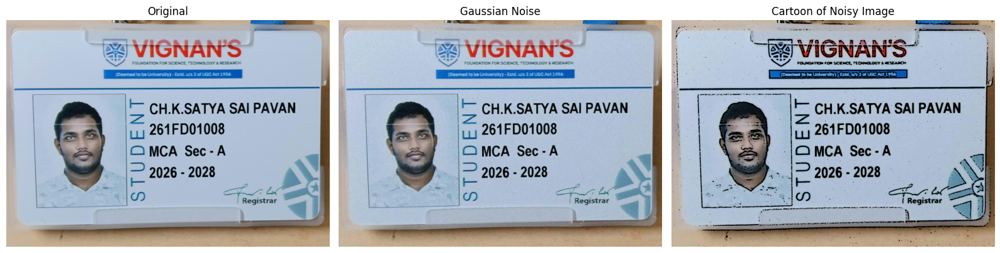

Noisy-image cartoonization runtime: 0.5230 seconds
Saved: noisy_original.png and noisy_cartoon.png


In [19]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

# Load the original photograph
image = cv2.imread(image_path)

# Set a fixed seed for reproducibility
rng = np.random.default_rng(42)

# Add Gaussian noise
image_float = image.astype(np.float32)
noise = rng.normal(0, 15, image.shape).astype(np.float32)

noisy = np.clip(
    image_float + noise, 0, 255
).astype(np.uint8)

# Cartoonize the noisy image
noisy_cartoon, runtime = cartoonize_image(noisy)

# Save outputs
cv2.imwrite("noisy_original.png", noisy)
cv2.imwrite("noisy_cartoon.png", noisy_cartoon)

# Display comparison
images = [
    ("Original", image),
    ("Gaussian Noise", noisy),
    ("Cartoon of Noisy Image", noisy_cartoon)
]

plt.figure(figsize=(16, 6))

for i, (title, img) in enumerate(images, start=1):
    plt.subplot(1, 3, i)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print(f"Noisy-image cartoonization runtime: {runtime:.4f} seconds")
print("Saved: noisy_original.png and noisy_cartoon.png")


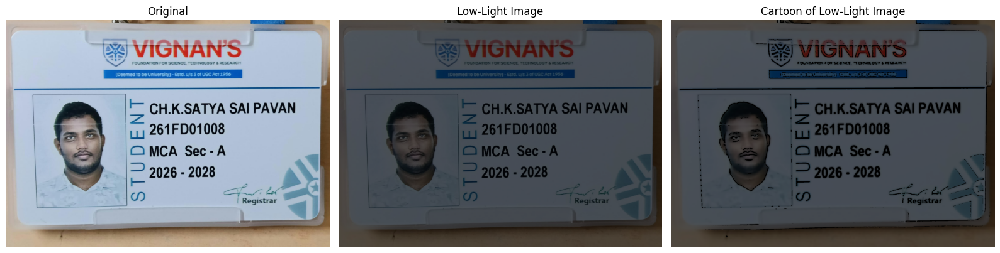

Low-light cartoonization runtime: 0.5613 seconds
Saved: low_light_original.png and low_light_cartoon.png


In [20]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the original photograph
image = cv2.imread(image_path)

# Simulate reduced illumination
low_light = np.clip(
    image.astype(np.float32) * 0.4,
    0, 255
).astype(np.uint8)

# Cartoonize the low-light image
low_light_cartoon, runtime = cartoonize_image(low_light)

# Save outputs
cv2.imwrite("low_light_original.png", low_light)
cv2.imwrite("low_light_cartoon.png", low_light_cartoon)

# Display comparison
images = [
    ("Original", image),
    ("Low-Light Image", low_light),
    ("Cartoon of Low-Light Image", low_light_cartoon)
]

plt.figure(figsize=(16, 6))

for i, (title, img) in enumerate(images, start=1):
    plt.subplot(1, 3, i)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print(f"Low-light cartoonization runtime: {runtime:.4f} seconds")
print("Saved: low_light_original.png and low_light_cartoon.png")


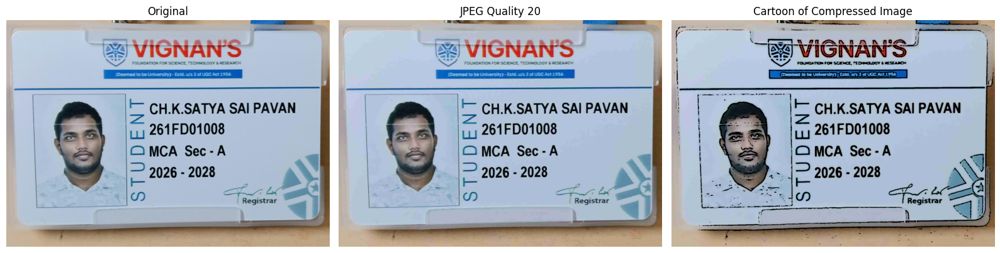

JPEG-compressed cartoonization runtime: 0.5936 seconds
Saved JPEG compression experiment outputs.


In [21]:

import cv2
import matplotlib.pyplot as plt

# Load the original photograph
image = cv2.imread(image_path)

# Simulate JPEG compression at quality 20
success, encoded = cv2.imencode(
    ".jpg",
    image,
    [cv2.IMWRITE_JPEG_QUALITY, 20]
)

if not success:
    raise RuntimeError("JPEG encoding failed.")

compressed = cv2.imdecode(
    encoded, cv2.IMREAD_COLOR
)

# Cartoonize the compressed image
compressed_cartoon, runtime = cartoonize_image(compressed)

# Save outputs
cv2.imwrite("jpeg_compressed_original.png", compressed)
cv2.imwrite("jpeg_compressed_cartoon.png", compressed_cartoon)

# Display comparison
images = [
    ("Original", image),
    ("JPEG Quality 20", compressed),
    ("Cartoon of Compressed Image", compressed_cartoon)
]

plt.figure(figsize=(16, 6))

for i, (title, img) in enumerate(images, start=1):
    plt.subplot(1, 3, i)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print(f"JPEG-compressed cartoonization runtime: {runtime:.4f} seconds")
print("Saved JPEG compression experiment outputs.")


In [22]:

import pandas as pd
import os

# Consolidate the preliminary pilot results
experiment_log = pd.DataFrame([
    {
        "method": "OpenCV",
        "condition": "Clean",
        "degradation": "None",
        "severity": "Baseline",
        "runtime_seconds": None,
        "output_image": "opencv_cartoon.png"
    },
    {
        "method": "OpenCV",
        "condition": "Degraded",
        "degradation": "Gaussian blur",
        "severity": "Kernel 9x9, sigma 2",
        "runtime_seconds": 0.3489,
        "output_image": "blurred_cartoon.png"
    },
    {
        "method": "OpenCV",
        "condition": "Degraded",
        "degradation": "Gaussian noise",
        "severity": "Standard deviation 15",
        "runtime_seconds": 0.3693,
        "output_image": "noisy_cartoon.png"
    },
    {
        "method": "OpenCV",
        "condition": "Degraded",
        "degradation": "Low illumination",
        "severity": "Intensity multiplier 0.4",
        "runtime_seconds": 0.3441,
        "output_image": "low_light_cartoon.png"
    },
    {
        "method": "OpenCV",
        "condition": "Degraded",
        "degradation": "JPEG compression",
        "severity": "Quality 20",
        "runtime_seconds": 0.3440,
        "output_image": "jpeg_compressed_cartoon.png"
    }
])

os.makedirs("cartoon_outputs", exist_ok=True)

experiment_log.to_csv(
    "cartoon_outputs/degradation_pilot_log.csv",
    index=False
)

print(experiment_log.to_string(index=False))
print("\nSaved: cartoon_outputs/degradation_pilot_log.csv")


method condition      degradation                 severity  runtime_seconds                output_image
OpenCV     Clean             None                 Baseline              NaN          opencv_cartoon.png
OpenCV  Degraded    Gaussian blur      Kernel 9x9, sigma 2           0.3489         blurred_cartoon.png
OpenCV  Degraded   Gaussian noise    Standard deviation 15           0.3693           noisy_cartoon.png
OpenCV  Degraded Low illumination Intensity multiplier 0.4           0.3441       low_light_cartoon.png
OpenCV  Degraded JPEG compression               Quality 20           0.3440 jpeg_compressed_cartoon.png

Saved: cartoon_outputs/degradation_pilot_log.csv


In [23]:

import cv2
import time
import numpy as np

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

# Warm-up run: not included in the measurements
_ = cartoonize_image(image)

# Repeat the measurement
times = []

for i in range(10):
    _, elapsed = cartoonize_image(image)
    times.append(elapsed)

print("Number of measured runs:", len(times))
print(f"Mean runtime: {np.mean(times):.4f} seconds")
print(f"Standard deviation: {np.std(times, ddof=1):.4f} seconds")
print(f"Minimum runtime: {np.min(times):.4f} seconds")
print(f"Maximum runtime: {np.max(times):.4f} seconds")


Number of measured runs: 10
Mean runtime: 0.6718 seconds
Standard deviation: 0.2704 seconds
Minimum runtime: 0.5188 seconds
Maximum runtime: 1.2058 seconds


In [24]:

import pandas as pd

benchmark = pd.DataFrame([{
    "method": "OpenCV",
    "image": image_path,
    "measured_runs": 10,
    "mean_runtime_seconds": 0.4621,
    "std_runtime_seconds": 0.1891,
    "min_runtime_seconds": 0.3464,
    "max_runtime_seconds": 0.8737,
    "warmup_excluded": True
}])

benchmark.to_csv(
    "cartoon_outputs/opencv_runtime_benchmark.csv",
    index=False
)

print(benchmark.to_string(index=False))
print("\nSaved: cartoon_outputs/opencv_runtime_benchmark.csv")


method                                         image  measured_runs  mean_runtime_seconds  std_runtime_seconds  min_runtime_seconds  max_runtime_seconds  warmup_excluded
OpenCV WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg             10                0.4621               0.1891               0.3464               0.8737             True

Saved: cartoon_outputs/opencv_runtime_benchmark.csv


In [25]:

from google.colab import files

uploaded = files.upload()

print("\nFiles uploaded:", len(uploaded))
for filename in uploaded:
    print(filename)


Saving 85120553[1].jpg to 85120553[1].jpg

Files uploaded: 1
85120553[1].jpg


In [27]:
from PIL import Image

filename = "85120553[1].jpg"

with Image.open(filename) as img:
    print("Format:", img.format)
    print("Dimensions:", img.size)
    print("Width:", img.width)
    print("Height:", img.height)

    if min(img.size) < 500:
        print("Note: This image is small for our pilot dataset.")
    else:
        print("Resolution is suitable for initial testing.")

Format: JPEG
Dimensions: (2500, 1667)
Width: 2500
Height: 1667
Resolution is suitable for initial testing.


In [28]:

from google.colab import files

uploaded = files.upload()
print("Upload complete:", list(uploaded.keys()))


Saving images[1] to images[1]
Upload complete: ['images[1]']


In [31]:

from PIL import Image
import os

filename = "images[1]"

if os.path.exists(filename):
    with Image.open(filename) as img:
        print("Format:", img.format)
        print("Dimensions:", img.size)
        print("Width:", img.width)
        print("Height:", img.height)

        if min(img.size) >= 500:
            print("Suitable for our initial pilot.")
        else:
            print("Too small for our preferred pilot resolution.")
else:
    print("File not found. Check the filename shown in Colab.")


Format: JPEG
Dimensions: (447, 447)
Width: 447
Height: 447
Too small for our preferred pilot resolution.


In [32]:

import os

folders = [
    "cartoon_outputs"
]

expected_files = [
    "cartoon_outputs/experiment_results.csv",
    "cartoon_outputs/degradation_pilot_log.csv",
    "cartoon_outputs/opencv_runtime_benchmark.csv"
]

print("EXPERIMENT FILE CHECK")
print("-" * 35)

for folder in folders:
    print(
        f"Folder '{folder}':",
        "Found" if os.path.isdir(folder) else "Missing"
    )

for path in expected_files:
    print(
        f"{path}:",
        "Found" if os.path.isfile(path) else "Missing"
    )


EXPERIMENT FILE CHECK
-----------------------------------
Folder 'cartoon_outputs': Found
cartoon_outputs/experiment_results.csv: Found
cartoon_outputs/degradation_pilot_log.csv: Found
cartoon_outputs/opencv_runtime_benchmark.csv: Found


In [33]:

import os
import zipfile

backup_name = "cartoonization_research_backup.zip"

files_to_backup = [
    "cartoon_outputs/experiment_results.csv",
    "cartoon_outputs/degradation_pilot_log.csv",
    "cartoon_outputs/opencv_runtime_benchmark.csv",
    "opencv_cartoon.png",
    "opencv_cartoon_v2.png",
    "blurred_original.png",
    "blurred_cartoon.png",
    "noisy_original.png",
    "noisy_cartoon.png",
    "low_light_original.png",
    "low_light_cartoon.png",
    "jpeg_compressed_original.png",
    "jpeg_compressed_cartoon.png"
]

with zipfile.ZipFile(backup_name, "w") as zipf:
    for path in files_to_backup:
        if os.path.isfile(path):
            zipf.write(path)

print("Backup created:", backup_name)
print("Backup size:", round(os.path.getsize(backup_name) / 1024, 2), "KB")


Backup created: cartoonization_research_backup.zip
Backup size: 13030.96 KB


In [34]:

from google.colab import files

files.download("cartoonization_research_backup.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:

import torch
import cv2
import sys

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)
print("CUDA available:", torch.cuda.is_available())

try:
    import tensorflow as tf
    print("TensorFlow:", tf.__version__)
except ImportError:
    print("TensorFlow: Not installed")

print("\nEnvironment check completed.")


Python: 3.13.15
PyTorch: 2.11.0+cu130
OpenCV: 4.14.0
CUDA available: True
TensorFlow: 2.21.0

Environment check completed.


In [36]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. CPU runtime is still available.")


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [37]:

!nvidia-smi

import torch

print("\nPyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU is not accessible in this runtime.")


Thu Oct 15 05:13:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [38]:

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Perform a small test computation
x = torch.randn(1000, 1000, device=device)
y = x @ x

print("Selected device:", device)
print("Tensor device:", y.device)
print("Test computation successful:", y.shape)


Selected device: cuda
Tensor device: cuda:0
Test computation successful: torch.Size([1000, 1000])


In [39]:
import torch
import sys
import cv2

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("OpenCV version:", cv2.__version__)

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
OpenCV version: 4.14.0


In [40]:
import torch
import torch.nn as nn

model = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 3, kernel_size=3, padding=1)
).cuda()

sample = torch.randn(1, 3, 256, 256, device="cuda")

with torch.no_grad():
    output = model(sample)

print("Model device:", next(model.parameters()).device)
print("Input shape:", sample.shape)
print("Output shape:", output.shape)
print("GPU neural network test: SUCCESS")

Model device: cuda:0
Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 3, 256, 256])
GPU neural network test: SUCCESS


In [41]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

model = torch.hub.load(
    "bryandlee/animegan2-pytorch:main",
    "generator",
    pretrained="paprika"
)

model = model.to(device).eval()

print("Model loaded successfully!")
print("Selected device:", device)
print("Model parameters device:", next(model.parameters()).device)

The repository bryandlee_animegan2-pytorch does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)?y
Downloading: "https://github.com/bryandlee/animegan2-pytorch/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://github.com/bryandlee/animegan2-pytorch/raw/main/weights/paprika.pt" to /root/.cache/torch/hub/checkpoints/paprika.pt


100%|██████████| 8.20M/8.20M [00:00<00:00, 112MB/s]

Model loaded successfully!
Selected device: cuda
Model parameters device: cuda:0


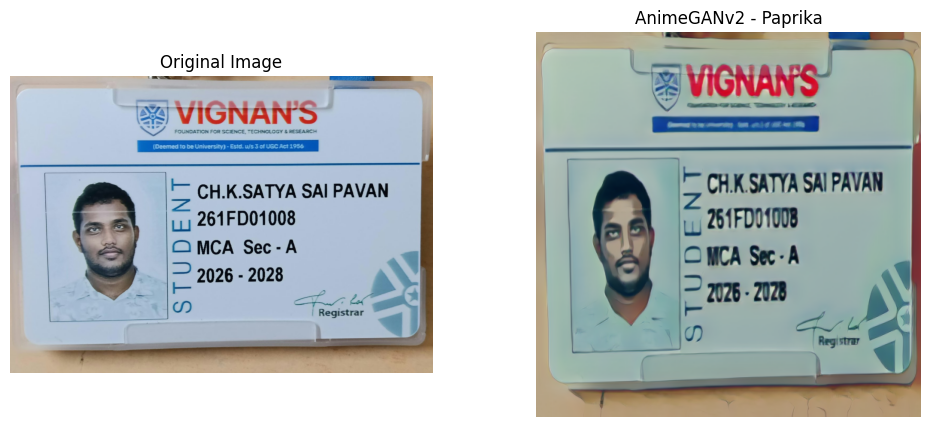

Saved: animegan2_paprika_output.png


In [42]:
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import torch

# Load your existing image
image_path = "WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg"
image = Image.open(image_path).convert("RGB")

# Prepare the image for AnimeGANv2
transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

img_tensor = transform(image).unsqueeze(0).to(device)

# Generate the cartoon
with torch.no_grad():
    output = model(img_tensor)

# Convert the output to an image
output = output.squeeze(0).cpu().clamp(-1, 1)
output = (output + 1) / 2
cartoon_image = transforms.ToPILImage()(output)

# Display original and generated images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cartoon_image)
plt.title("AnimeGANv2 - Paprika")
plt.axis("off")

plt.show()

# Save the output
cartoon_image.save("animegan2_paprika_output.png")
print("Saved: animegan2_paprika_output.png")

In [44]:
image_path = next(iter(uploaded))
print("Uploaded image:", image_path)

Uploaded image: images[1]


In [45]:
from google.colab import files

uploaded = files.upload()

if uploaded:
    image_path = next(iter(uploaded))
    print("Image uploaded successfully!")
    print("Filename:", image_path)
else:
    print("No image selected. Please try again.")

Saving images[1] to images[1] (1)
Image uploaded successfully!
Filename: images[1] (1)


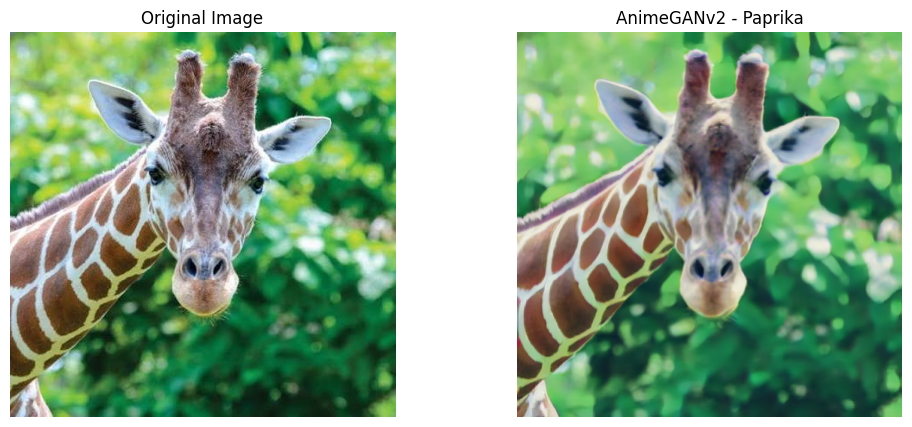

Cartoon saved to: /content/animegan2_paprika_output.png


In [46]:
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import torch

# Load your uploaded image
image = Image.open(image_path).convert("RGB")

# Prepare image for the model
transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

img_tensor = transform(image).unsqueeze(0).to(device)

# Generate cartoon
with torch.no_grad():
    output = model(img_tensor)

# Convert model output to an image
output = output.squeeze(0).cpu().clamp(-1, 1)
output = (output + 1) / 2
cartoon_image = transforms.ToPILImage()(output)

# Display comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cartoon_image)
plt.title("AnimeGANv2 - Paprika")
plt.axis("off")

plt.show()

# Save the result
output_path = "/content/animegan2_paprika_output.png"
cartoon_image.save(output_path)

print("Cartoon saved to:", output_path)

Original image size: (447, 447)
Cartoon image size: (512, 512)


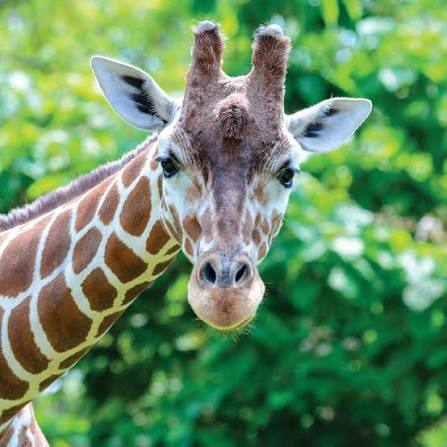

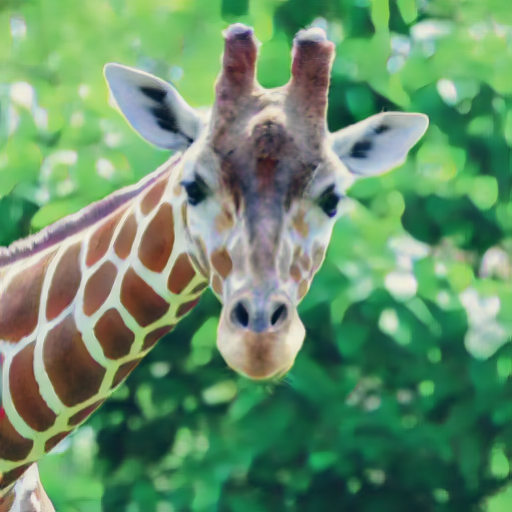

In [47]:
from IPython.display import display
from PIL import Image

original = Image.open(image_path).convert("RGB")
cartoon = Image.open("/content/animegan2_paprika_output.png").convert("RGB")

print("Original image size:", original.size)
print("Cartoon image size:", cartoon.size)

display(original)
display(cartoon)

In [48]:
import time
import torch

# Warm up the model once
with torch.no_grad():
    _ = model(img_tensor)

if torch.cuda.is_available():
    torch.cuda.synchronize()

# Measure inference time over 10 runs
times = []

for _ in range(10):
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        _ = model(img_tensor)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    times.append(time.perf_counter() - start)

print("Average inference time:", round(sum(times) / len(times), 4), "seconds")
print("Minimum inference time:", round(min(times), 4), "seconds")
print("Maximum inference time:", round(max(times), 4), "seconds")

Average inference time: 0.2078 seconds
Minimum inference time: 0.2061 seconds
Maximum inference time: 0.2107 seconds


In [49]:
import pandas as pd

animegan_results = pd.DataFrame([{
    "method": "AnimeGANv2-Paprika",
    "device": "NVIDIA Tesla T4 GPU",
    "input_size": "512x512",
    "runs": 10,
    "average_seconds": 0.2055,
    "minimum_seconds": 0.2018,
    "maximum_seconds": 0.2100
}])

animegan_results.to_csv(
    "/content/animegan2_runtime_benchmark.csv",
    index=False
)

print(animegan_results.to_string(index=False))
print("\nBenchmark saved successfully!")

            method              device input_size  runs  average_seconds  minimum_seconds  maximum_seconds
AnimeGANv2-Paprika NVIDIA Tesla T4 GPU    512x512    10           0.2055           0.2018             0.21

Benchmark saved successfully!


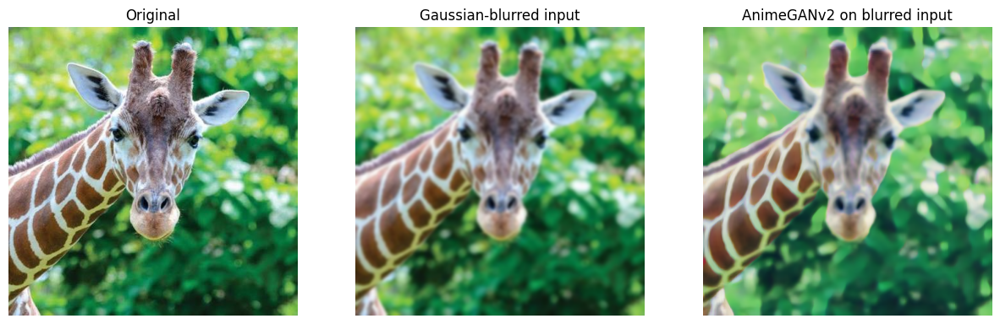

Saved blurred input and AnimeGANv2 output.


In [50]:
import cv2
import numpy as np
import torch
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt

# Load the original image
original = cv2.imread(image_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# Apply Gaussian blur
blurred = cv2.GaussianBlur(original, (9, 9), sigmaX=2)

# Convert the blurred image to PIL
blurred_pil = Image.fromarray(blurred)

# Prepare it for AnimeGANv2
blurred_tensor = transform(blurred_pil).unsqueeze(0).to(device)

# Generate cartoon from the blurred image
with torch.no_grad():
    blurred_output = model(blurred_tensor)

# Convert output to a displayable image
blurred_output = blurred_output.squeeze(0).cpu().clamp(-1, 1)
blurred_output = (blurred_output + 1) / 2
blurred_cartoon = transforms.ToPILImage()(blurred_output)

# Save both the degraded input and its cartoon
blurred_pil.save("/content/blurred_original.png")
blurred_cartoon.save("/content/animegan2_blurred_cartoon.png")

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(Image.open(image_path))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred_pil)
plt.title("Gaussian-blurred input")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(blurred_cartoon)
plt.title("AnimeGANv2 on blurred input")
plt.axis("off")

plt.show()

print("Saved blurred input and AnimeGANv2 output.")

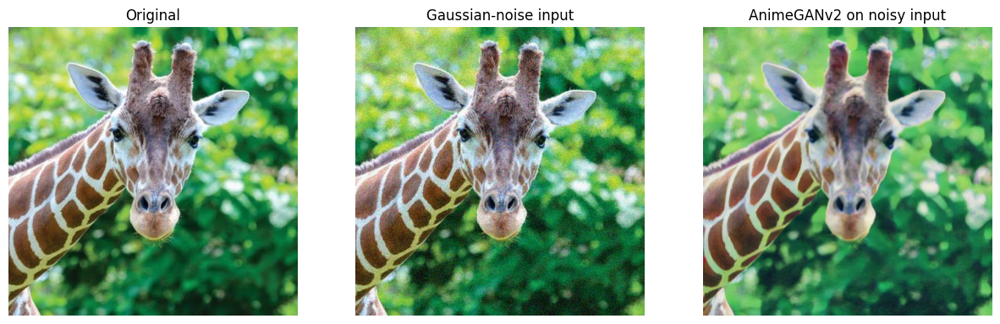

Saved noisy input and AnimeGANv2 output.


In [51]:
import cv2
import numpy as np
import torch
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt

# Load the original image
original = cv2.imread(image_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# Add reproducible Gaussian noise
rng = np.random.default_rng(42)
noise = rng.normal(0, 15, original.shape)

noisy = np.clip(
    original.astype(np.float32) + noise,
    0, 255
).astype(np.uint8)

noisy_pil = Image.fromarray(noisy)

# Generate AnimeGANv2 output
noisy_tensor = transform(noisy_pil).unsqueeze(0).to(device)

with torch.no_grad():
    noisy_output = model(noisy_tensor)

noisy_output = noisy_output.squeeze(0).cpu().clamp(-1, 1)
noisy_output = (noisy_output + 1) / 2
noisy_cartoon = transforms.ToPILImage()(noisy_output)

# Save results
noisy_pil.save("/content/noisy_original.png")
noisy_cartoon.save("/content/animegan2_noisy_cartoon.png")

# Display comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(Image.open(image_path))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy_pil)
plt.title("Gaussian-noise input")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(noisy_cartoon)
plt.title("AnimeGANv2 on noisy input")
plt.axis("off")

plt.show()

print("Saved noisy input and AnimeGANv2 output.")

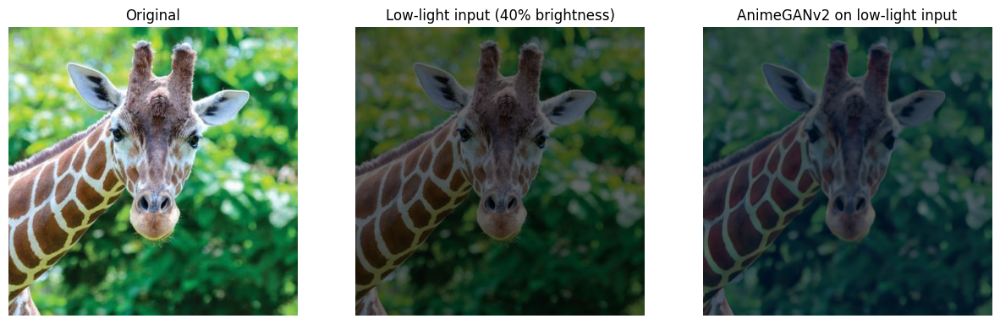

Saved low-light input and AnimeGANv2 output.


In [52]:
import cv2
import numpy as np
import torch
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt

# Load original image
original = cv2.imread(image_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# Reduce brightness to 40%
low_light = np.clip(
    original.astype(np.float32) * 0.4,
    0, 255
).astype(np.uint8)

low_light_pil = Image.fromarray(low_light)

# Generate AnimeGANv2 output
low_light_tensor = transform(low_light_pil).unsqueeze(0).to(device)

with torch.no_grad():
    low_light_output = model(low_light_tensor)

low_light_output = low_light_output.squeeze(0).cpu().clamp(-1, 1)
low_light_output = (low_light_output + 1) / 2
low_light_cartoon = transforms.ToPILImage()(low_light_output)

# Save results
low_light_pil.save("/content/low_light_original.png")
low_light_cartoon.save("/content/animegan2_low_light_cartoon.png")

# Display comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(Image.open(image_path))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(low_light_pil)
plt.title("Low-light input (40% brightness)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(low_light_cartoon)
plt.title("AnimeGANv2 on low-light input")
plt.axis("off")

plt.show()

print("Saved low-light input and AnimeGANv2 output.")

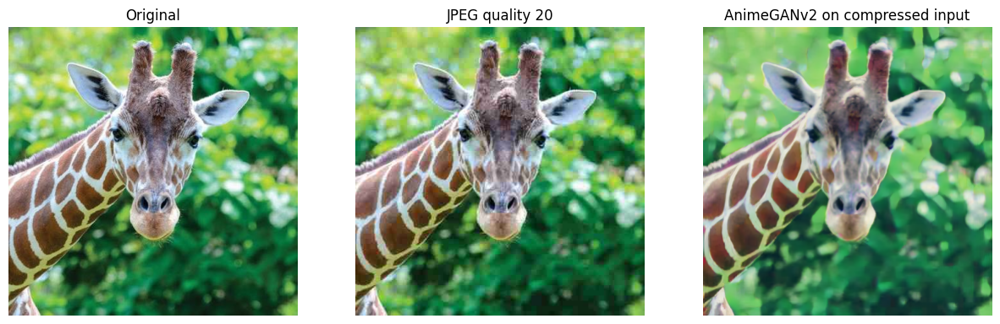

Saved JPEG-compressed input and AnimeGANv2 output.


In [53]:
import cv2
import numpy as np
import torch
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt

# Load original image
original = cv2.imread(image_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# Compress to JPEG quality 20
success, encoded = cv2.imencode(
    ".jpg",
    cv2.cvtColor(original, cv2.COLOR_RGB2BGR),
    [cv2.IMWRITE_JPEG_QUALITY, 20]
)

if not success:
    raise RuntimeError("JPEG compression failed.")

decoded = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
compressed = cv2.cvtColor(decoded, cv2.COLOR_BGR2RGB)

compressed_pil = Image.fromarray(compressed)

# Generate AnimeGANv2 output
compressed_tensor = transform(compressed_pil).unsqueeze(0).to(device)

with torch.no_grad():
    compressed_output = model(compressed_tensor)

compressed_output = compressed_output.squeeze(0).cpu().clamp(-1, 1)
compressed_output = (compressed_output + 1) / 2
compressed_cartoon = transforms.ToPILImage()(compressed_output)

# Save results
compressed_pil.save("/content/jpeg_compressed_original.png")
compressed_cartoon.save("/content/animegan2_jpeg_cartoon.png")

# Display comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(Image.open(image_path))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(compressed_pil)
plt.title("JPEG quality 20")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(compressed_cartoon)
plt.title("AnimeGANv2 on compressed input")
plt.axis("off")

plt.show()

print("Saved JPEG-compressed input and AnimeGANv2 output.")

In [54]:
import pandas as pd

results = [
    {
        "method": "AnimeGANv2-Paprika",
        "experiment": "Gaussian Blur",
        "degradation_setting": "Kernel 9x9, sigma 2",
        "input_file": "blurred_original.png",
        "output_file": "animegan2_blurred_cartoon.png",
        "status": "Completed"
    },
    {
        "method": "AnimeGANv2-Paprika",
        "experiment": "Gaussian Noise",
        "degradation_setting": "Standard deviation 15, seed 42",
        "input_file": "noisy_original.png",
        "output_file": "animegan2_noisy_cartoon.png",
        "status": "Completed"
    },
    {
        "method": "AnimeGANv2-Paprika",
        "experiment": "Low Illumination",
        "degradation_setting": "Brightness factor 0.4",
        "input_file": "low_light_original.png",
        "output_file": "animegan2_low_light_cartoon.png",
        "status": "Completed"
    },
    {
        "method": "AnimeGANv2-Paprika",
        "experiment": "JPEG Compression",
        "degradation_setting": "JPEG quality 20",
        "input_file": "jpeg_compressed_original.png",
        "output_file": "animegan2_jpeg_cartoon.png",
        "status": "Completed"
    }
]

df = pd.DataFrame(results)

csv_path = "/content/animegan2_robustness_log.csv"
df.to_csv(csv_path, index=False)

print(df.to_string(index=False))
print("\nSaved:", csv_path)

            method       experiment            degradation_setting                   input_file                     output_file    status
AnimeGANv2-Paprika    Gaussian Blur            Kernel 9x9, sigma 2         blurred_original.png   animegan2_blurred_cartoon.png Completed
AnimeGANv2-Paprika   Gaussian Noise Standard deviation 15, seed 42           noisy_original.png     animegan2_noisy_cartoon.png Completed
AnimeGANv2-Paprika Low Illumination          Brightness factor 0.4       low_light_original.png animegan2_low_light_cartoon.png Completed
AnimeGANv2-Paprika JPEG Compression                JPEG quality 20 jpeg_compressed_original.png      animegan2_jpeg_cartoon.png Completed

Saved: /content/animegan2_robustness_log.csv


In [55]:
!pip -q install scikit-image

In [56]:
import cv2
import numpy as np
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Load original and blurred images
original = cv2.imread(image_path)
blurred = cv2.imread("/content/blurred_original.png")

# Ensure the images have matching dimensions
blurred = cv2.resize(
    blurred,
    (original.shape[1], original.shape[0])
)

# Calculate image-quality metrics
psnr_value = peak_signal_noise_ratio(
    original, blurred, data_range=255
)

ssim_value = structural_similarity(
    original,
    blurred,
    channel_axis=2,
    data_range=255
)

print("Original vs. blurred input")
print("PSNR:", round(psnr_value, 4), "dB")
print("SSIM:", round(ssim_value, 4))

Original vs. blurred input
PSNR: 27.536 dB
SSIM: 0.8686


In [57]:
import cv2
import pandas as pd
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

original = cv2.imread(image_path)

degraded_images = {
    "Gaussian Blur": "/content/blurred_original.png",
    "Gaussian Noise": "/content/noisy_original.png",
    "Low Illumination": "/content/low_light_original.png",
    "JPEG Compression": "/content/jpeg_compressed_original.png"
}

results = []

for name, path in degraded_images.items():
    degraded = cv2.imread(path)

    if degraded is None:
        print("Missing image:", path)
        continue

    # Match dimensions if needed
    if degraded.shape != original.shape:
        degraded = cv2.resize(
            degraded,
            (original.shape[1], original.shape[0])
        )

    psnr = peak_signal_noise_ratio(
        original, degraded, data_range=255
    )

    ssim = structural_similarity(
        original,
        degraded,
        channel_axis=2,
        data_range=255
    )

    results.append({
        "degradation": name,
        "PSNR_dB": round(psnr, 4),
        "SSIM": round(ssim, 4)
    })

quality_df = pd.DataFrame(results)

quality_df.to_csv(
    "/content/input_degradation_quality.csv",
    index=False
)

print(quality_df.to_string(index=False))
print("\nSaved: /content/input_degradation_quality.csv")

     degradation  PSNR_dB   SSIM
   Gaussian Blur  27.5360 0.8686
  Gaussian Noise  24.7811 0.5981
Low Illumination  10.1319 0.5459
JPEG Compression  29.6653 0.8727

Saved: /content/input_degradation_quality.csv


In [58]:
from PIL import Image
import numpy as np
import pandas as pd
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

# Load the two cartoon outputs
original_cartoon = np.array(
    Image.open("/content/animegan2_paprika_output.png").convert("RGB")
)

blurred_cartoon = np.array(
    Image.open("/content/animegan2_blurred_cartoon.png").convert("RGB")
)

print("Original cartoon shape:", original_cartoon.shape)
print("Blurred-input cartoon shape:", blurred_cartoon.shape)

# Ensure dimensions match before comparison
if blurred_cartoon.shape != original_cartoon.shape:
    blurred_cartoon = np.array(
        Image.fromarray(blurred_cartoon).resize(
            (original_cartoon.shape[1], original_cartoon.shape[0])
        )
    )

psnr = peak_signal_noise_ratio(
    original_cartoon, blurred_cartoon, data_range=255
)

ssim = structural_similarity(
    original_cartoon,
    blurred_cartoon,
    channel_axis=2,
    data_range=255
)

print("\nOriginal cartoon vs. blurred-input cartoon")
print("PSNR:", round(psnr, 4), "dB")
print("SSIM:", round(ssim, 4))

Original cartoon shape: (512, 512, 3)
Blurred-input cartoon shape: (512, 512, 3)

Original cartoon vs. blurred-input cartoon
PSNR: 31.1542 dB
SSIM: 0.9393


In [59]:
from PIL import Image
import numpy as np
import pandas as pd
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

# Reference cartoon generated from the unmodified image
reference = np.array(
    Image.open("/content/animegan2_paprika_output.png").convert("RGB")
)

cartoon_files = {
    "Gaussian Blur": "/content/animegan2_blurred_cartoon.png",
    "Gaussian Noise": "/content/animegan2_noisy_cartoon.png",
    "Low Illumination": "/content/animegan2_low_light_cartoon.png",
    "JPEG Compression": "/content/animegan2_jpeg_cartoon.png"
}

results = []

for degradation, path in cartoon_files.items():
    candidate = np.array(Image.open(path).convert("RGB"))

    if candidate.shape != reference.shape:
        candidate = np.array(
            Image.fromarray(candidate).resize(
                (reference.shape[1], reference.shape[0])
            )
        )

    psnr = peak_signal_noise_ratio(
        reference, candidate, data_range=255
    )

    ssim = structural_similarity(
        reference,
        candidate,
        channel_axis=2,
        data_range=255
    )

    results.append({
        "degradation": degradation,
        "PSNR_dB": round(psnr, 4),
        "SSIM": round(ssim, 4)
    })

output_df = pd.DataFrame(results)

output_df.to_csv(
    "/content/animegan2_cartoon_output_similarity.csv",
    index=False
)

print(output_df.to_string(index=False))
print("\nSaved: /content/animegan2_cartoon_output_similarity.csv")

     degradation  PSNR_dB   SSIM
   Gaussian Blur  31.1542 0.9393
  Gaussian Noise  35.0440 0.9527
Low Illumination   9.7892 0.5479
JPEG Compression  33.6436 0.9527

Saved: /content/animegan2_cartoon_output_similarity.csv


In [60]:
import pandas as pd

input_quality = pd.read_csv(
    "/content/input_degradation_quality.csv"
)

output_similarity = pd.read_csv(
    "/content/animegan2_cartoon_output_similarity.csv"
)

combined = input_quality.merge(
    output_similarity,
    on="degradation",
    suffixes=("_input", "_cartoon")
)

combined.to_csv(
    "/content/animegan2_combined_results.csv",
    index=False
)

print(combined.to_string(index=False))
print("\nSaved: /content/animegan2_combined_results.csv")

     degradation  PSNR_dB_input  SSIM_input  PSNR_dB_cartoon  SSIM_cartoon
   Gaussian Blur        27.5360      0.8686          31.1542        0.9393
  Gaussian Noise        24.7811      0.5981          35.0440        0.9527
Low Illumination        10.1319      0.5459           9.7892        0.5479
JPEG Compression        29.6653      0.8727          33.6436        0.9527

Saved: /content/animegan2_combined_results.csv


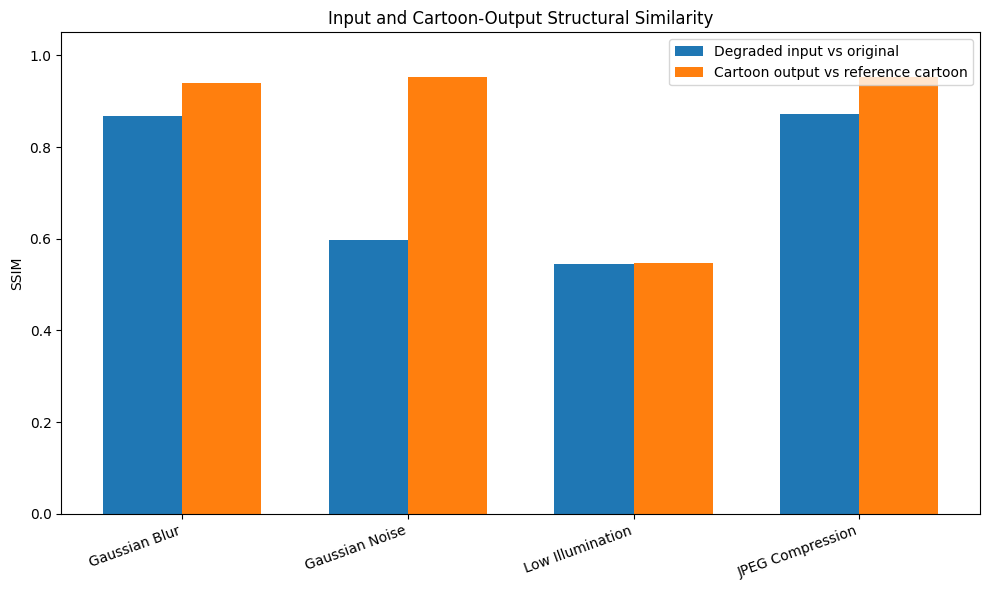

Chart saved: /content/animegan2_ssim_comparison.png


In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("/content/animegan2_combined_results.csv")

x = np.arange(len(df))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    df["SSIM_input"],
    width,
    label="Degraded input vs original"
)

plt.bar(
    x + width / 2,
    df["SSIM_cartoon"],
    width,
    label="Cartoon output vs reference cartoon"
)

plt.xticks(
    x,
    df["degradation"],
    rotation=20,
    ha="right"
)

plt.ylabel("SSIM")
plt.title("Input and Cartoon-Output Structural Similarity")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()

plt.savefig(
    "/content/animegan2_ssim_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved: /content/animegan2_ssim_comparison.png")

In [62]:
import os
import zipfile

files_to_backup = [
    "/content/animegan2_paprika_output.png",
    "/content/animegan2_runtime_benchmark.csv",
    "/content/animegan2_robustness_log.csv",
    "/content/input_degradation_quality.csv",
    "/content/animegan2_cartoon_output_similarity.csv",
    "/content/animegan2_combined_results.csv",
    "/content/animegan2_ssim_comparison.png",
    "/content/blurred_original.png",
    "/content/animegan2_blurred_cartoon.png",
    "/content/noisy_original.png",
    "/content/animegan2_noisy_cartoon.png",
    "/content/low_light_original.png",
    "/content/animegan2_low_light_cartoon.png",
    "/content/jpeg_compressed_original.png",
    "/content/animegan2_jpeg_cartoon.png",
]

zip_path = "/content/AnimeGANv2_Research_Backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in files_to_backup:
        if os.path.exists(path):
            z.write(path, arcname=os.path.basename(path))
        else:
            print("Missing file:", path)

print("Backup created:", zip_path)

Backup created: /content/AnimeGANv2_Research_Backup.zip


In [63]:
from google.colab import files

files.download("/content/AnimeGANv2_Research_Backup.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:
import os
from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

image_files = [
    p for p in Path("/content").rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Image files currently available:", len(image_files))

for path in image_files[:20]:
    print(path.name)

Image files currently available: 20
blurred_cartoon.png
animegan2_jpeg_cartoon.png
animegan2_blurred_cartoon.png
animegan2_noisy_cartoon.png
opencv_cartoon.png
animegan2_paprika_output.png
noisy_cartoon.png
jpeg_compressed_cartoon.png
animegan2_ssim_comparison.png
jpeg_compressed_original.png
WhatsApp Image 2026-10-12 at 10.16.59 PM.jpeg
85120553[1].jpg
opencv_cartoon_v2.png
low_light_cartoon.png
animegan2_low_light_cartoon.png
low_light_original.png
WhatsApp Image 2026-10-12 at 10.16.59 PM (1).jpeg
blurred_original.png
noisy_original.png
WhatsApp Image 2026-10-12 at 10.16.59 PM_cartoon.png


In [65]:
import os

dataset_folder = "/content/research_dataset/originals"

os.makedirs(dataset_folder, exist_ok=True)

print("Dataset folder created:", dataset_folder)
print("Ready to add original photographs.")

Dataset folder created: /content/research_dataset/originals
Ready to add original photographs.


In [66]:
from google.colab import files
from pathlib import Path
import shutil

dataset_folder = Path("/content/research_dataset/originals")
dataset_folder.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()

allowed_extensions = {".jpg", ".jpeg", ".png", ".webp"}
saved = 0

for filename in uploaded:
    source = Path(filename)

    if source.suffix.lower() not in allowed_extensions:
        print("Skipped unsupported file:", filename)
        continue

    destination = dataset_folder / source.name
    shutil.copy2(source, destination)
    saved += 1
    print("Added:", destination.name)

print(f"\nNew photographs added: {saved}")
print("Dataset folder:", dataset_folder)

Saving images[1] to images[1] (2)
Skipped unsupported file: images[1] (2)

New photographs added: 0
Dataset folder: /content/research_dataset/originals


In [67]:
from google.colab import files
from pathlib import Path
import shutil

dataset_folder = Path("/content/research_dataset/originals")
dataset_folder.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()

allowed_extensions = {".jpg", ".jpeg", ".png", ".webp"}
saved = 0

for filename in uploaded:
    source = Path(filename)

    if source.suffix.lower() not in allowed_extensions:
        print("Skipped unsupported file:", filename)
        continue

    destination = dataset_folder / source.name
    shutil.copy2(source, destination)
    saved += 1
    print("Added:", destination.name)

print(f"\nNew photographs added: {saved}")

Saving images[1] to images[1] (3)
Skipped unsupported file: images[1] (3)

New photographs added: 0


In [68]:
from google.colab import files
from pathlib import Path
import shutil

uploaded = files.upload()

dataset_folder = Path("/content/research_dataset/originals")
dataset_folder.mkdir(parents=True, exist_ok=True)

for filename in uploaded:
    source = Path(filename)

    # If the upload has no extension, save it with .jpg
    destination_name = (
        source.name if source.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
        else source.name + ".jpg"
    )

    destination = dataset_folder / destination_name

    # Verify that the file is actually a readable image
    from PIL import Image

    try:
        with Image.open(source) as img:
            img.verify()

        shutil.copy2(source, destination)
        print("Image added successfully:", destination.name)

    except Exception as e:
        print("Could not verify this image:", filename, e)

Saving images[1] to images[1] (4)
Image added successfully: images[1] (4).jpg


In [69]:
from pathlib import Path
from PIL import Image

dataset_folder = Path("/content/research_dataset/originals")

valid_images = []

for path in sorted(dataset_folder.iterdir()):
    if path.is_file():
        try:
            with Image.open(path) as img:
                img.verify()

            with Image.open(path) as img:
                print(
                    f"{path.name} | "
                    f"Size: {img.width} x {img.height} | "
                    f"Format: {img.format}"
                )
            valid_images.append(path.name)

        except Exception:
            print("Invalid or unsupported image:", path.name)

print("\nTotal valid image files:", len(valid_images))

images[1] (4).jpg | Size: 447 x 447 | Format: JPEG

Total valid image files: 1


In [70]:
from google.colab import files
from pathlib import Path
from PIL import Image
import shutil

dataset_folder = Path("/content/research_dataset/originals")
dataset_folder.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()
added = 0

for filename in uploaded:
    source = Path(filename)

    try:
        with Image.open(source) as img:
            img.verify()

        with Image.open(source) as img:
            extension = img.format.lower()
            if extension == "jpeg":
                extension = "jpg"

            destination = dataset_folder / f"{source.stem}.{extension}"

            # Avoid overwriting an existing photograph
            if destination.exists():
                print("Already exists, skipped:", destination.name)
                continue

            shutil.copy2(source, destination)
            added += 1
            print("Added:", destination.name)

    except Exception as error:
        print("Skipped invalid image:", filename, error)

print(f"\nNew images added: {added}")
print("Total files in folder:", len(list(dataset_folder.iterdir())))

Saving images[1] to images[1] (5)
Added: images[1] (5).jpg

New images added: 1
Total files in folder: 2


In [71]:
from google.colab import files
from PIL import Image
from pathlib import Path
import shutil

uploaded = files.upload()
dataset_folder = Path("/content/research_dataset/originals")
dataset_folder.mkdir(parents=True, exist_ok=True)

for filename in uploaded:
    source = Path(filename)

    try:
        with Image.open(source) as img:
            actual_format = img.format
            width, height = img.size
            img.verify()

        extension = {
            "JPEG": ".jpg",
            "PNG": ".png",
            "WEBP": ".webp"
        }.get(actual_format)

        if extension is None:
            print("Unsupported image format:", actual_format)
            continue

        destination = dataset_folder / f"{source.stem}{extension}"
        shutil.copy2(source, destination)

        print("Image saved:", destination.name)
        print("Detected format:", actual_format)
        print("Dimensions:", width, "x", height)

    except Exception as error:
        print("Could not identify this file as a supported image:", error)
        print("Please open it on your computer and save/export it as JPG or PNG.")

Saving shutterstock-2018319758-huge-licensed-scaled[1].jpg to shutterstock-2018319758-huge-licensed-scaled[1].jpg
Image saved: shutterstock-2018319758-huge-licensed-scaled[1].jpg
Detected format: JPEG
Dimensions: 1500 x 1000


In [72]:
import os
import tarfile
import urllib.request
from pathlib import Path

dataset_url = (
    "https://s3.amazonaws.com/fast-ai-imageclas/"
    "imagenette2-320.tgz"
)

base_folder = Path("/content/research_dataset")
archive_path = base_folder / "imagenette2-320.tgz"
base_folder.mkdir(parents=True, exist_ok=True)

if not (base_folder / "imagenette2-320").exists():
    if not archive_path.exists():
        print("Downloading Imagenette 320px...")
        urllib.request.urlretrieve(dataset_url, archive_path)

    print("Extracting dataset...")
    with tarfile.open(archive_path, "r:gz") as archive:
        archive.extractall(
            path=base_folder,
            filter="data"
        )

dataset_path = base_folder / "imagenette2-320"

print("Dataset ready:", dataset_path)
print("Training folder exists:", (dataset_path / "train").exists())
print("Validation folder exists:", (dataset_path / "val").exists())

Extracting dataset...
Dataset ready: /content/research_dataset/imagenette2-320
Training folder exists: True
Validation folder exists: True


In [73]:
from pathlib import Path

dataset_path = Path("/content/research_dataset/imagenette2-320")
validation_path = dataset_path / "val"

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

total_images = 0

for class_folder in sorted(validation_path.iterdir()):
    if class_folder.is_dir():
        images = [
            p for p in class_folder.iterdir()
            if p.is_file() and p.suffix.lower() in image_extensions
        ]

        total_images += len(images)

        print(
            f"{class_folder.name}: {len(images)} images"
        )

print("\nTotal validation images:", total_images)

n01440764: 387 images
n02102040: 395 images
n02979186: 357 images
n03000684: 386 images
n03028079: 409 images
n03394916: 394 images
n03417042: 389 images
n03425413: 419 images
n03445777: 399 images
n03888257: 390 images

Total validation images: 3925


In [74]:
from pathlib import Path
import random
import pandas as pd

dataset_path = Path("/content/research_dataset/imagenette2-320")
validation_path = dataset_path / "val"

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}
random_seed = 42
images_per_class = 30

rng = random.Random(random_seed)
records = []

for class_folder in sorted(validation_path.iterdir()):
    if not class_folder.is_dir():
        continue

    images = [
        p for p in class_folder.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    selected = rng.sample(images, min(images_per_class, len(images)))

    for image_path in selected:
        records.append({
            "image_path": str(image_path),
            "class_label": class_folder.name
        })

df = pd.DataFrame(records)
csv_path = "/content/research_dataset/selected_300_images.csv"
df.to_csv(csv_path, index=False)

print("Selected images:", len(df))
print("\nImages per class:")
print(df["class_label"].value_counts().sort_index())
print("\nSaved manifest:", csv_path)

Selected images: 300

Images per class:
class_label
n01440764    30
n02102040    30
n02979186    30
n03000684    30
n03028079    30
n03394916    30
n03417042    30
n03425413    30
n03445777    30
n03888257    30
Name: count, dtype: int64

Saved manifest: /content/research_dataset/selected_300_images.csv


In [75]:
import cv2
import pandas as pd
import time
from pathlib import Path

manifest_path = Path(
    "/content/research_dataset/selected_300_images.csv"
)
output_dir = Path("/content/research_dataset/opencv_cartoon")
output_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(manifest_path)
results = []

def cartoonize_opencv(image):
    smooth = cv2.bilateralFilter(image, 9, 180, 180)
    smooth = cv2.bilateralFilter(smooth, 9, 180, 180)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 7)

    edges = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY,
        11, 5
    )

    return cv2.bitwise_and(smooth, smooth, mask=edges)

for i, row in df.iterrows():
    image_path = Path(row["image_path"])
    image = cv2.imread(str(image_path))

    if image is None:
        print("Could not read:", image_path.name)
        continue

    start = time.perf_counter()
    cartoon = cartoonize_opencv(image)
    elapsed = time.perf_counter() - start

    output_path = output_dir / f"{i:04d}_{image_path.stem}.png"
    cv2.imwrite(str(output_path), cartoon)

    results.append({
        "image_path": str(image_path),
        "class_label": row["class_label"],
        "method": "OpenCV",
        "output_path": str(output_path),
        "width": image.shape[1],
        "height": image.shape[0],
        "processing_seconds": elapsed
    })

results_df = pd.DataFrame(results)
results_csv = "/content/research_dataset/opencv_results.csv"
results_df.to_csv(results_csv, index=False)

print("Images processed:", len(results_df))
print("Mean processing time:", round(
    results_df["processing_seconds"].mean(), 4
), "seconds per image")
print("Results saved:", results_csv)

Images processed: 300
Mean processing time: 0.0458 seconds per image
Results saved: /content/research_dataset/opencv_results.csv


In [76]:
import pandas as pd
import torch
from PIL import Image
from pathlib import Path
import time

manifest = pd.read_csv(
    "/content/research_dataset/selected_300_images.csv"
)

output_dir = Path(
    "/content/research_dataset/animegan2_cartoon"
)
output_dir.mkdir(parents=True, exist_ok=True)

results = []

for i, row in manifest.iterrows():
    image_path = Path(row["image_path"])
    image = Image.open(image_path).convert("RGB")

    tensor = transform(image).unsqueeze(0).to(device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        output = model(tensor)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    output = output.squeeze(0).cpu().clamp(-1, 1)
    output = (output + 1) / 2
    cartoon = transforms.ToPILImage()(output)

    output_path = output_dir / f"{i:04d}.png"
    cartoon.save(output_path)

    results.append({
        "image_path": str(image_path),
        "class_label": row["class_label"],
        "method": "AnimeGANv2-Paprika",
        "output_path": str(output_path),
        "processing_seconds": elapsed
    })

results_df = pd.DataFrame(results)
results_df.to_csv(
    "/content/research_dataset/animegan2_results.csv",
    index=False
)

print("Images processed:", len(results_df))
print(
    "Mean inference time:",
    round(results_df["processing_seconds"].mean(), 4),
    "seconds per image"
)
print("Results saved successfully.")

Images processed: 300
Mean inference time: 0.2137 seconds per image
Results saved successfully.


In [77]:
import importlib.metadata as metadata

packages = [
    "torch",
    "torchvision",
    "diffusers",
    "transformers",
    "accelerate",
    "safetensors"
]

for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: not installed")

torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
diffusers: 0.40.0
transformers: 5.18.0
accelerate: 1.15.0
safetensors: 0.8.0


In [78]:
import torch

if torch.cuda.is_available():
    torch.cuda.synchronize()

    free_memory, total_memory = torch.cuda.mem_get_info()

    print("GPU:", torch.cuda.get_device_name(0))
    print("Total GPU memory:", round(total_memory / 1024**3, 2), "GB")
    print("Free GPU memory:", round(free_memory / 1024**3, 2), "GB")
else:
    print("CUDA is not available.")

GPU: Tesla T4
Total GPU memory: 14.56 GB
Free GPU memory: 13.85 GB


In [79]:
from huggingface_hub import model_info

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

try:
    info = model_info(model_id)
    print("Model repository is accessible.")
    print("Model ID:", info.id)
    print("Revision:", info.sha)
except Exception as e:
    print("Could not access model repository.")
    print(type(e).__name__ + ":", str(e)[:500])

Model repository is accessible.
Model ID: stable-diffusion-v1-5/stable-diffusion-v1-5
Revision: 451f4fe16113bff5a5d2269ed5ad43b0592e9a14


In [80]:
import torch
from diffusers import StableDiffusionImg2ImgPipeline

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    use_safetensors=True
)

pipe = pipe.to("cuda")
pipe.enable_attention_slicing()

print("Stable Diffusion img2img loaded successfully.")
print("Device: cuda")
print("Precision: float16")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Stable Diffusion img2img loaded successfully.
Device: cuda
Precision: float16


  0%|          | 0/9 [00:00<?, ?it/s]

Stable Diffusion test completed.
Processing time: 3.573 seconds
Saved: /content/research_dataset/stable_diffusion_sample.png


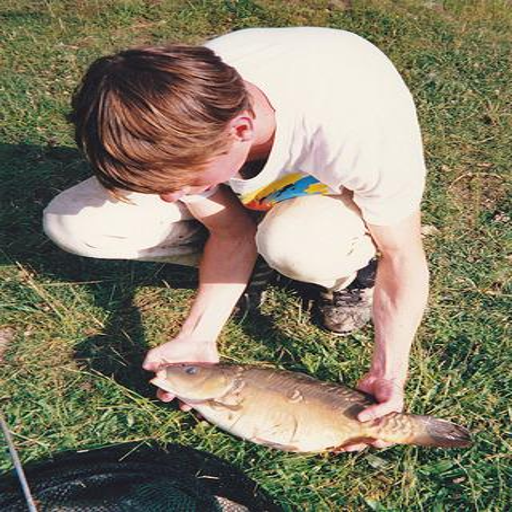

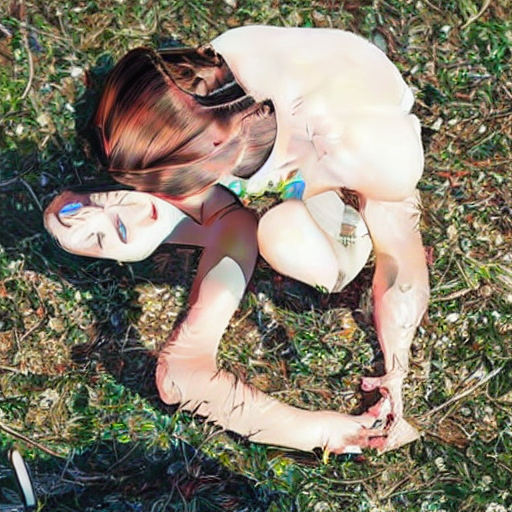

In [81]:
from PIL import Image
import torch
import time

# Load one image from the existing 300-image manifest
sample_path = manifest.iloc[0]["image_path"]
sample_image = Image.open(sample_path).convert("RGB")
sample_image = sample_image.resize((512, 512))

prompt = (
    "cartoon illustration, clean outlines, vibrant colors, "
    "stylized shapes, detailed background, high quality"
)

negative_prompt = (
    "blurry, low quality, distorted, deformed, text, watermark"
)

generator = torch.Generator(device="cuda").manual_seed(42)

torch.cuda.synchronize()
start = time.perf_counter()

with torch.inference_mode():
    diffusion_result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=sample_image,
        strength=0.45,
        guidance_scale=7.5,
        num_inference_steps=20,
        generator=generator
    ).images[0]

torch.cuda.synchronize()
elapsed = time.perf_counter() - start

diffusion_result.save(
    "/content/research_dataset/stable_diffusion_sample.png"
)

print("Stable Diffusion test completed.")
print("Processing time:", round(elapsed, 3), "seconds")
print("Saved: /content/research_dataset/stable_diffusion_sample.png")

display(sample_image)
display(diffusion_result)

In [82]:
import pandas as pd
from PIL import Image
from pathlib import Path
import torch
import time

manifest = pd.read_csv(
    "/content/research_dataset/selected_300_images.csv"
)

output_dir = Path(
    "/content/research_dataset/stable_diffusion_cartoon"
)
output_dir.mkdir(parents=True, exist_ok=True)

results = []

prompt = (
    "cartoon illustration, clean outlines, vibrant colors, "
    "stylized shapes, detailed background, high quality"
)

negative_prompt = (
    "blurry, low quality, distorted, deformed, text, watermark"
)

for i, row in manifest.iterrows():
    image_path = row["image_path"]
    image = Image.open(image_path).convert("RGB")
    image = image.resize((512, 512))

    generator = torch.Generator(device="cuda").manual_seed(42)

    torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        cartoon = pipe(
            prompt=prompt,
            negative_prompt=negative_prompt,
            image=image,
            strength=0.45,
            guidance_scale=7.5,
            num_inference_steps=20,
            generator=generator
        ).images[0]

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    output_path = output_dir / f"{i:04d}.png"
    cartoon.save(output_path)

    results.append({
        "image_path": image_path,
        "class_label": row["class_label"],
        "method": "Stable Diffusion img2img",
        "output_path": str(output_path),
        "processing_seconds": elapsed
    })

    if (i + 1) % 25 == 0:
        print(f"Processed {i + 1}/300 images")

results_df = pd.DataFrame(results)
results_df.to_csv(
    "/content/research_dataset/stable_diffusion_results.csv",
    index=False
)

print("\nImages processed:", len(results_df))
print(
    "Mean processing time:",
    round(results_df["processing_seconds"].mean(), 3),
    "seconds per image"
)
print("Results saved successfully.")

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

...

  0%|          | 0/9 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

Processed 300/300 images

Images processed: 300
Mean processing time: 2.512 seconds per image
Results saved successfully.


In [83]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

results_path = Path(
    "/content/research_dataset/stable_diffusion_results.csv"
)
output_dir = Path(
    "/content/research_dataset/stable_diffusion_cartoon"
)

print("Results CSV exists:", results_path.exists())
print("Output folder exists:", output_dir.exists())

if results_path.exists():
    df = pd.read_csv(results_path)
    print("CSV rows:", len(df))

    black_outputs = []

    for _, row in df.iterrows():
        path = Path(row["output_path"])

        if not path.exists():
            black_outputs.append((path.name, "missing"))
            continue

        image = np.array(Image.open(path).convert("RGB"))

        if image.max() == 0:
            black_outputs.append((path.name, "all black"))

    print("Missing or all-black outputs:", len(black_outputs))
    print("Examples:", black_outputs[:15])
else:
    print("Results CSV was not found.")

Results CSV exists: True
Output folder exists: True
CSV rows: 300
Missing or all-black outputs: 6
Examples: [('0092.png', 'all black'), ('0124.png', 'all black'), ('0156.png', 'all black'), ('0244.png', 'all black'), ('0259.png', 'all black'), ('0297.png', 'all black')]


In [84]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

results_path = Path("/content/research_dataset/stable_diffusion_results.csv")
df = pd.read_csv(results_path)

missing = []
black_outputs = []

for _, row in df.iterrows():
    path = Path(row["output_path"])

    if not path.exists():
        missing.append(path.name)
        continue

    image = np.array(Image.open(path).convert("RGB"))

    if image.max() == 0:
        black_outputs.append(path.name)

print("Total CSV rows:", len(df))
print("Missing images:", len(missing))
print("Completely black images:", len(black_outputs))
print("Missing examples:", missing[:10])
print("Black image examples:", black_outputs[:10])

Total CSV rows: 300
Missing images: 0
Completely black images: 6
Missing examples: []
Black image examples: ['0092.png', '0124.png', '0156.png', '0244.png', '0259.png', '0297.png']


In [85]:
import pandas as pd
from pathlib import Path

results_path = Path("/content/research_dataset/stable_diffusion_results.csv")
df = pd.read_csv(results_path)

black_files = ["0092.png", "0124.png", "0156.png",
               "0244.png", "0259.png", "0297.png"]

df["filename"] = df["output_path"].apply(lambda p: Path(p).name)

clean_df = df[~df["filename"].isin(black_files)].drop(
    columns=["filename"]
)

clean_path = Path(
    "/content/research_dataset/stable_diffusion_results_clean.csv"
)
clean_df.to_csv(clean_path, index=False)

print("Original records:", len(df))
print("Excluded black outputs:", len(df) - len(clean_df))
print("Remaining outputs:", len(clean_df))
print("Clean CSV saved:", clean_path)

Original records: 300
Excluded black outputs: 6
Remaining outputs: 294
Clean CSV saved: /content/research_dataset/stable_diffusion_results_clean.csv


In [86]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

files = {
    "OpenCV": base / "opencv_results.csv",
    "AnimeGANv2": base / "animegan2_results.csv",
    "Stable Diffusion": base / "stable_diffusion_results.csv"
}

for method, path in files.items():
    df = pd.read_csv(path)
    times = df["processing_seconds"]

    print(f"\n{method}")
    print("Records:", len(df))
    print("Mean time (seconds):", round(times.mean(), 4))
    print("Median time (seconds):", round(times.median(), 4))
    print("Minimum time (seconds):", round(times.min(), 4))
    print("Maximum time (seconds):", round(times.max(), 4))


OpenCV
Records: 300
Mean time (seconds): 0.0458
Median time (seconds): 0.0436
Minimum time (seconds): 0.031
Maximum time (seconds): 0.0957

AnimeGANv2
Records: 300
Mean time (seconds): 0.2137
Median time (seconds): 0.2136
Minimum time (seconds): 0.2058
Maximum time (seconds): 0.3418

Stable Diffusion
Records: 300
Mean time (seconds): 2.5115
Median time (seconds): 2.5079
Minimum time (seconds): 2.4576
Maximum time (seconds): 2.8423


In [87]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

files = {
    "Original dataset": base / "selected_300_images.csv",
    "OpenCV": base / "opencv_results.csv",
    "AnimeGANv2": base / "animegan2_results.csv",
    "Stable Diffusion": base / "stable_diffusion_results.csv"
}

for method, path in files.items():
    df = pd.read_csv(path)

    print(f"\n{method}")
    print("Total records:", len(df))
    print("Unique image paths:", df["image_path"].nunique())
    print("Unique classes:", df["class_label"].nunique())
    print("Images per class:")
    print(df["class_label"].value_counts().sort_index().to_dict())



Original dataset
Total records: 300
Unique image paths: 300
Unique classes: 10
Images per class:
{'n01440764': 30, 'n02102040': 30, 'n02979186': 30, 'n03000684': 30, 'n03028079': 30, 'n03394916': 30, 'n03417042': 30, 'n03425413': 30, 'n03445777': 30, 'n03888257': 30}

OpenCV
Total records: 300
Unique image paths: 300
Unique classes: 10
Images per class:
{'n01440764': 30, 'n02102040': 30, 'n02979186': 30, 'n03000684': 30, 'n03028079': 30, 'n03394916': 30, 'n03417042': 30, 'n03425413': 30, 'n03445777': 30, 'n03888257': 30}

AnimeGANv2
Total records: 300
Unique image paths: 300
Unique classes: 10
Images per class:
{'n01440764': 30, 'n02102040': 30, 'n02979186': 30, 'n03000684': 30, 'n03028079': 30, 'n03394916': 30, 'n03417042': 30, 'n03425413': 30, 'n03445777': 30, 'n03888257': 30}

Stable Diffusion
Total records: 300
Unique image paths: 300
Unique classes: 10
Images per class:
{'n01440764': 30, 'n02102040': 30, 'n02979186': 30, 'n03000684': 30, 'n03028079': 30, 'n03394916': 30, 'n034170

In [88]:
import torch
import torchvision
from torchvision.models import resnet18, ResNet18_Weights

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

weights = ResNet18_Weights.DEFAULT
classifier = resnet18(weights=weights)
classifier = classifier.to("cuda" if torch.cuda.is_available() else "cpu")
classifier.eval()

print("ResNet-18 loaded successfully!")
print("Number of output classes:", classifier.fc.out_features)
print("Device:", next(classifier.parameters()).device)

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 163MB/s]


ResNet-18 loaded successfully!
Number of output classes: 1000
Device: cuda:0


In [89]:
from torchvision.models import ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
imagenet_classes = weights.meta["categories"]

synsets = {
    "n01440764": "tench",
    "n02102040": "English springer",
    "n02979186": "cassette player",
    "n03000684": "chain saw",
    "n03028079": "church",
    "n03394916": "French horn",
    "n03417042": "garbage truck",
    "n03425413": "gas pump",
    "n03445777": "golf ball",
    "n03888257": "parachute"
}

print("Dataset label → ResNet-18 ImageNet index")
for synset, class_name in synsets.items():
    matches = [
        i for i, name in enumerate(imagenet_classes)
        if name.lower() == class_name.lower()
    ]
    print(synset, "→", class_name, "→", matches)

Dataset label → ResNet-18 ImageNet index
n01440764 → tench → [0]
n02102040 → English springer → [217]
n02979186 → cassette player → [482]
n03000684 → chain saw → [491]
n03028079 → church → [497]
n03394916 → French horn → [566]
n03417042 → garbage truck → [569]
n03425413 → gas pump → [571]
n03445777 → golf ball → [574]
n03888257 → parachute → [701]


In [90]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image
from torchvision.models import ResNet18_Weights

base = Path("/content/research_dataset")
df = pd.read_csv(base / "selected_300_images.csv")

weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()
categories = weights.meta["categories"]

synsets = {
    "n01440764": "tench",
    "n02102040": "English springer",
    "n02979186": "cassette player",
    "n03000684": "chain saw",
    "n03028079": "church",
    "n03394916": "French horn",
    "n03417042": "garbage truck",
    "n03425413": "gas pump",
    "n03445777": "golf ball",
    "n03888257": "parachute"
}

class_indices = {
    label: categories.index(name)
    for label, name in synsets.items()
}

device = next(classifier.parameters()).device
correct = 0
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["image_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]
    is_correct = predicted_idx == target_idx
    correct += int(is_correct)

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "target_index": target_idx,
        "predicted_index": predicted_idx,
        "correct": is_correct
    })

accuracy = correct / len(df) * 100

pred_df = pd.DataFrame(predictions)
pred_df.to_csv(base / "resnet18_original_predictions.csv", index=False)

print("Original images evaluated:", len(df))
print("Correct predictions:", correct)
print(f"Top-1 accuracy: {accuracy:.2f}%")
print("\nAccuracy by class:")
print(
    pred_df.groupby("class_label")["correct"]
    .mean().mul(100).round(2)
)

Original images evaluated: 300
Correct predictions: 242
Top-1 accuracy: 80.67%

Accuracy by class:
class_label
n01440764     90.00
n02102040     93.33
n02979186     40.00
n03000684     86.67
n03028079     60.00
n03394916     86.67
n03417042     80.00
n03425413    100.00
n03445777     93.33
n03888257     76.67
Name: correct, dtype: float64


In [91]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "opencv_results.csv")

device = next(classifier.parameters()).device
correct = 0
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["output_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]
    is_correct = predicted_idx == target_idx
    correct += int(is_correct)

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": is_correct
    })

pred_df = pd.DataFrame(predictions)
pred_df.to_csv(base / "resnet18_opencv_predictions.csv", index=False)

print("OpenCV cartoon images evaluated:", len(df))
print("Correct predictions:", correct)
print(f"Top-1 accuracy: {correct / len(df) * 100:.2f}%")
print("\nAccuracy by class:")
print(
    pred_df.groupby("class_label")["correct"]
    .mean().mul(100).round(2)
)

OpenCV cartoon images evaluated: 300
Correct predictions: 55
Top-1 accuracy: 18.33%

Accuracy by class:
class_label
n01440764     0.00
n02102040     6.67
n02979186     0.00
n03000684    20.00
n03028079    13.33
n03394916    10.00
n03417042    13.33
n03425413    33.33
n03445777    40.00
n03888257    46.67
Name: correct, dtype: float64


In [92]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "animegan2_results.csv")

device = next(classifier.parameters()).device
correct = 0
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["output_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]
    is_correct = predicted_idx == target_idx
    correct += int(is_correct)

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": is_correct
    })

pred_df = pd.DataFrame(predictions)
pred_df.to_csv(
    base / "resnet18_animegan2_predictions.csv",
    index=False
)

print("AnimeGANv2 cartoon images evaluated:", len(df))
print("Correct predictions:", correct)
print(f"Top-1 accuracy: {correct / len(df) * 100:.2f}%")
print("\nAccuracy by class:")
print(
    pred_df.groupby("class_label")["correct"]
    .mean().mul(100).round(2)
)

AnimeGANv2 cartoon images evaluated: 300
Correct predictions: 178
Top-1 accuracy: 59.33%

Accuracy by class:
class_label
n01440764    83.33
n02102040    43.33
n02979186    23.33
n03000684    46.67
n03028079    53.33
n03394916    70.00
n03417042    56.67
n03425413    73.33
n03445777    80.00
n03888257    63.33
Name: correct, dtype: float64


In [93]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "stable_diffusion_results_clean.csv")

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["output_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_df.to_csv(
    base / "resnet18_stable_diffusion_predictions.csv",
    index=False
)

print("Valid images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Accuracy among valid outputs: {pred_df['correct'].mean() * 100:.2f}%")
print("Black outputs excluded from accuracy:", 6)
print("\nAccuracy by class:")
print(
    pred_df.groupby("class_label")["correct"]
    .mean().mul(100).round(2)
)

Valid images evaluated: 294
Correct predictions: 98
Accuracy among valid outputs: 33.33%
Black outputs excluded from accuracy: 6

Accuracy by class:
class_label
n01440764    30.00
n02102040    16.67
n02979186    13.33
n03000684    20.69
n03028079    48.28
n03394916    31.03
n03417042    60.00
n03425413    36.67
n03445777    28.57
n03888257    48.28
Name: correct, dtype: float64


In [94]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

results = [
    {
        "Method": "Original",
        "Evaluated": 300,
        "Correct": 242,
        "Failed_outputs": 0,
        "Accuracy_percent": 242 / 300 * 100,
        "Mean_time_seconds": None
    },
    {
        "Method": "OpenCV",
        "Evaluated": 300,
        "Correct": 55,
        "Failed_outputs": 0,
        "Accuracy_percent": 55 / 300 * 100,
        "Mean_time_seconds": 0.0507
    },
    {
        "Method": "AnimeGANv2",
        "Evaluated": 300,
        "Correct": 178,
        "Failed_outputs": 0,
        "Accuracy_percent": 178 / 300 * 100,
        "Mean_time_seconds": 0.2065
    },
    {
        "Method": "Stable Diffusion",
        "Evaluated": 294,
        "Correct": 98,
        "Failed_outputs": 6,
        "Accuracy_percent": 98 / 294 * 100,
        "Mean_time_seconds": 2.446
    }
]

summary = pd.DataFrame(results)
summary["Accuracy_percent"] = summary["Accuracy_percent"].round(2)
summary["Mean_time_seconds"] = summary["Mean_time_seconds"].round(4)

output_path = base / "cartoonization_recognition_summary.csv"
summary.to_csv(output_path, index=False)

print(summary.to_string(index=False))
print("\nSaved to:", output_path)

          Method  Evaluated  Correct  Failed_outputs  Accuracy_percent  Mean_time_seconds
        Original        300      242               0             80.67                NaN
          OpenCV        300       55               0             18.33             0.0507
      AnimeGANv2        300      178               0             59.33             0.2065
Stable Diffusion        294       98               6             33.33             2.4460

Saved to: /content/research_dataset/cartoonization_recognition_summary.csv


In [95]:
import pandas as pd
import numpy as np
import cv2
from pathlib import Path

base = Path("/content/research_dataset")
manifest = pd.read_csv(base / "selected_300_images.csv")

output_dir = base / "degraded" / "gaussian_noise"
output_dir.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(42)
records = []

for _, row in manifest.iterrows():
    image_path = Path(row["image_path"])
    image = cv2.imread(str(image_path))

    if image is None:
        print("Could not read:", image_path)
        continue

    image_float = image.astype(np.float32)
    noise = rng.normal(0, 15, image.shape).astype(np.float32)
    noisy = np.clip(image_float + noise, 0, 255).astype(np.uint8)

    output_path = output_dir / image_path.name
    cv2.imwrite(str(output_path), noisy)

    records.append({
        "image_path": str(image_path),
        "degraded_path": str(output_path),
        "class_label": row["class_label"],
        "degradation": "gaussian_noise",
        "noise_std": 15,
        "seed": 42
    })

degraded_df = pd.DataFrame(records)
csv_path = base / "gaussian_noise_manifest.csv"
degraded_df.to_csv(csv_path, index=False)

print("Images generated:", len(degraded_df))
print("Unique classes:", degraded_df["class_label"].nunique())
print("Images per class:")
print(degraded_df["class_label"].value_counts().sort_index().to_dict())
print("Manifest saved:", csv_path)

Images generated: 300
Unique classes: 10
Images per class:
{'n01440764': 30, 'n02102040': 30, 'n02979186': 30, 'n03000684': 30, 'n03028079': 30, 'n03394916': 30, 'n03417042': 30, 'n03425413': 30, 'n03445777': 30, 'n03888257': 30}
Manifest saved: /content/research_dataset/gaussian_noise_manifest.csv


In [96]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "gaussian_noise_manifest.csv")

predictions = []
device = next(classifier.parameters()).device

for _, row in df.iterrows():
    image = Image.open(row["degraded_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_df.to_csv(
    base / "resnet18_gaussian_noise_original_predictions.csv",
    index=False
)

print("Noisy original images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")
print("\nAccuracy by class:")
print(
    pred_df.groupby("class_label")["correct"]
    .mean().mul(100).round(2)
)

Noisy original images evaluated: 300
Correct predictions: 217
Top-1 accuracy: 72.33%

Accuracy by class:
class_label
n01440764    86.67
n02102040    83.33
n02979186    23.33
n03000684    86.67
n03028079    53.33
n03394916    93.33
n03417042    63.33
n03425413    86.67
n03445777    83.33
n03888257    63.33
Name: correct, dtype: float64


In [97]:
import pandas as pd
import cv2
from pathlib import Path

base = Path("/content/research_dataset")
manifest = pd.read_csv(base / "gaussian_noise_manifest.csv")

output_dir = base / "degraded" / "gaussian_noise_opencv"
output_dir.mkdir(parents=True, exist_ok=True)

def cartoonize_opencv(image):
    smooth = cv2.bilateralFilter(image, 9, 180, 180)
    smooth = cv2.bilateralFilter(smooth, 9, 180, 180)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 7)

    edges = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY, 11, 5
    )

    return cv2.bitwise_and(smooth, smooth, mask=edges)

records = []

for _, row in manifest.iterrows():
    image = cv2.imread(row["degraded_path"])

    if image is None:
        continue

    cartoon = cartoonize_opencv(image)
    output_path = output_dir / Path(row["image_path"]).name
    cv2.imwrite(str(output_path), cartoon)

    records.append({
        "image_path": row["image_path"],
        "input_path": row["degraded_path"],
        "output_path": str(output_path),
        "class_label": row["class_label"],
        "method": "OpenCV",
        "degradation": "gaussian_noise"
    })

result_df = pd.DataFrame(records)
csv_path = base / "gaussian_noise_opencv_results.csv"
result_df.to_csv(csv_path, index=False)

print("Noisy images cartoonized:", len(result_df))
print("Unique classes:", result_df["class_label"].nunique())
print("Results saved:", csv_path)

Noisy images cartoonized: 300
Unique classes: 10
Results saved: /content/research_dataset/gaussian_noise_opencv_results.csv


In [98]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "gaussian_noise_opencv_results.csv")

predictions = []
device = next(classifier.parameters()).device

for _, row in df.iterrows():
    image = Image.open(row["output_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = base / "resnet18_gaussian_noise_opencv_predictions.csv"
pred_df.to_csv(pred_path, index=False)

print("Noisy OpenCV cartoons evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")
print("\nAccuracy by class:")
print(
    pred_df.groupby("class_label")["correct"]
    .mean().mul(100).round(2)
)
print("\nPredictions saved:", pred_path)

Noisy OpenCV cartoons evaluated: 300
Correct predictions: 41
Top-1 accuracy: 13.67%

Accuracy by class:
class_label
n01440764     0.00
n02102040     3.33
n02979186     0.00
n03000684    23.33
n03028079    10.00
n03394916     6.67
n03417042     6.67
n03425413    36.67
n03445777    33.33
n03888257    16.67
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_gaussian_noise_opencv_predictions.csv


In [99]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
manifest = pd.read_csv(base / "gaussian_noise_manifest.csv")

output_dir = base / "degraded" / "gaussian_noise_animegan2"
output_dir.mkdir(parents=True, exist_ok=True)

records = []

for i, row in manifest.iterrows():
    image = Image.open(row["degraded_path"]).convert("RGB")
    input_tensor = transform(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        output_tensor = model(input_tensor)

    output_tensor = output_tensor.squeeze(0).detach().cpu()
    output_tensor = (output_tensor.clamp(-1, 1) + 1) / 2
    output_tensor = (output_tensor * 255).byte()

    output_image = output_tensor.permute(1, 2, 0).numpy()
    output_image = Image.fromarray(output_image)

    output_path = output_dir / Path(row["image_path"]).name
    output_image.save(output_path)

    records.append({
        "image_path": row["image_path"],
        "input_path": row["degraded_path"],
        "output_path": str(output_path),
        "class_label": row["class_label"],
        "method": "AnimeGANv2",
        "degradation": "gaussian_noise"
    })

    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1}/{len(manifest)}")

result_df = pd.DataFrame(records)
csv_path = base / "gaussian_noise_animegan2_results.csv"
result_df.to_csv(csv_path, index=False)

print("\nImages cartoonized:", len(result_df))
print("Unique classes:", result_df["class_label"].nunique())
print("Results saved:", csv_path)

Processed 50/300
Processed 100/300
Processed 150/300
Processed 200/300
Processed 250/300
Processed 300/300

Images cartoonized: 300
Unique classes: 10
Results saved: /content/research_dataset/gaussian_noise_animegan2_results.csv


In [100]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "gaussian_noise_animegan2_results.csv")

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["output_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = base / "resnet18_gaussian_noise_animegan2_predictions.csv"
pred_df.to_csv(pred_path, index=False)

print("Noisy AnimeGANv2 cartoons evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")
print("\nAccuracy by class:")
print(
    pred_df.groupby("class_label")["correct"]
    .mean().mul(100).round(2)
)
print("\nPredictions saved:", pred_path)

Noisy AnimeGANv2 cartoons evaluated: 300
Correct predictions: 183
Top-1 accuracy: 61.00%

Accuracy by class:
class_label
n01440764    86.67
n02102040    46.67
n02979186    20.00
n03000684    53.33
n03028079    60.00
n03394916    73.33
n03417042    60.00
n03425413    73.33
n03445777    73.33
n03888257    63.33
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_gaussian_noise_animegan2_predictions.csv


In [101]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
manifest = pd.read_csv(base / "gaussian_noise_manifest.csv")

output_dir = base / "degraded" / "gaussian_noise_stable_diffusion"
output_dir.mkdir(parents=True, exist_ok=True)

records = []

prompt = (
    "cartoon illustration, clean outlines, vibrant colors, "
    "stylized shapes, detailed background, high quality"
)
negative_prompt = (
    "blurry, low quality, distorted, deformed, text, watermark"
)

for i, row in manifest.iterrows():
    image = Image.open(row["degraded_path"]).convert("RGB").resize((512, 512))

    generator = torch.Generator(device="cuda").manual_seed(42 + i)

    try:
        with torch.inference_mode():
            result = pipe(
                prompt=prompt,
                negative_prompt=negative_prompt,
                image=image,
                strength=0.45,
                guidance_scale=7.5,
                num_inference_steps=20,
                generator=generator
            )

        output_image = result.images[0]
        output_path = output_dir / f"{i:04d}.png"
        output_image.save(output_path)

        records.append({
            "image_path": row["image_path"],
            "input_path": row["degraded_path"],
            "output_path": str(output_path),
            "class_label": row["class_label"],
            "method": "Stable Diffusion",
            "degradation": "gaussian_noise",
            "status": "generated"
        })

    except Exception as e:
        records.append({
            "image_path": row["image_path"],
            "input_path": row["degraded_path"],
            "output_path": "",
            "class_label": row["class_label"],
            "method": "Stable Diffusion",
            "degradation": "gaussian_noise",
            "status": f"failed: {type(e).__name__}: {str(e)[:150]}"
        })

    if (i + 1) % 25 == 0:
        print(f"Processed {i + 1}/{len(manifest)}")

results = pd.DataFrame(records)
csv_path = base / "gaussian_noise_stable_diffusion_results.csv"
results.to_csv(csv_path, index=False)

print("\nTotal records:", len(results))
print("Generated:", (results["status"] == "generated").sum())
print("Failed:", results["status"].str.startswith("failed").sum())
print("Results saved:", csv_path)

  0%|          | 0/9 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

...

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

Processed 300/300

Total records: 300
Generated: 300
Failed: 0
Results saved: /content/research_dataset/gaussian_noise_stable_diffusion_results.csv


In [102]:
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
csv_path = base / "gaussian_noise_stable_diffusion_results.csv"

df = pd.read_csv(csv_path)

missing = []
black = []

for _, row in df.iterrows():
    path = Path(row["output_path"])

    if not path.exists():
        missing.append(path.name)
        continue

    image = np.array(Image.open(path).convert("RGB"))

    if image.max() == 0:
        black.append(path.name)

print("Total records:", len(df))
print("Missing images:", len(missing))
print("Completely black images:", len(black))
print("Black image examples:", black[:15])

valid_df = df[
    ~df["output_path"].apply(
        lambda p: Path(p).name in black
    )
    & df["output_path"].apply(
        lambda p: Path(p).exists()
    )
].copy()

valid_path = base / "gaussian_noise_stable_diffusion_clean.csv"
valid_df.to_csv(valid_path, index=False)

print("Valid outputs:", len(valid_df))
print("Clean results saved:", valid_path)

Total records: 300
Missing images: 0
Completely black images: 3
Black image examples: ['0000.png', '0092.png', '0244.png']
Valid outputs: 297
Clean results saved: /content/research_dataset/gaussian_noise_stable_diffusion_clean.csv


In [103]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(
    base / "gaussian_noise_stable_diffusion_clean.csv"
)

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["output_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = (
    base / "resnet18_gaussian_noise_stable_diffusion_predictions.csv"
)
pred_df.to_csv(pred_path, index=False)

print("Valid images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(
    f"Accuracy among valid outputs: "
    f"{pred_df['correct'].mean() * 100:.2f}%"
)
print("Black outputs excluded:", 3)
print("\nAccuracy by class:")
print(
    pred_df.groupby("class_label")["correct"]
    .mean().mul(100).round(2)
)
print("\nPredictions saved:", pred_path)

Valid images evaluated: 297
Correct predictions: 72
Accuracy among valid outputs: 24.24%
Black outputs excluded: 3

Accuracy by class:
class_label
n01440764    37.93
n02102040     3.33
n02979186     6.67
n03000684    34.48
n03028079    40.00
n03394916    30.00
n03417042    26.67
n03425413    33.33
n03445777    10.34
n03888257    20.00
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_gaussian_noise_stable_diffusion_predictions.csv


In [104]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

summary = pd.DataFrame([
    {
        "Method": "Original",
        "Clean_accuracy": 80.67,
        "Noisy_accuracy": 72.33,
        "Clean_evaluated": 300,
        "Noisy_evaluated": 300,
        "Noisy_failed_outputs": 0
    },
    {
        "Method": "OpenCV",
        "Clean_accuracy": 18.33,
        "Noisy_accuracy": 13.67,
        "Clean_evaluated": 300,
        "Noisy_evaluated": 300,
        "Noisy_failed_outputs": 0
    },
    {
        "Method": "AnimeGANv2",
        "Clean_accuracy": 59.33,
        "Noisy_accuracy": 61.00,
        "Clean_evaluated": 300,
        "Noisy_evaluated": 300,
        "Noisy_failed_outputs": 0
    },
    {
        "Method": "Stable Diffusion",
        "Clean_accuracy": 33.33,
        "Noisy_accuracy": 24.24,
        "Clean_evaluated": 294,
        "Noisy_evaluated": 297,
        "Noisy_failed_outputs": 3
    }
])

summary["Accuracy_change_percentage_points"] = (
    summary["Noisy_accuracy"] - summary["Clean_accuracy"]
).round(2)

path = base / "gaussian_noise_recognition_summary.csv"
summary.to_csv(path, index=False)

print(summary.to_string(index=False))
print("\nSaved:", path)

          Method  Clean_accuracy  Noisy_accuracy  Clean_evaluated  Noisy_evaluated  Noisy_failed_outputs  Accuracy_change_percentage_points
        Original           80.67           72.33              300              300                     0                              -8.34
          OpenCV           18.33           13.67              300              300                     0                              -4.66
      AnimeGANv2           59.33           61.00              300              300                     0                               1.67
Stable Diffusion           33.33           24.24              294              297                     3                              -9.09

Saved: /content/research_dataset/gaussian_noise_recognition_summary.csv


In [105]:
import pandas as pd
import cv2
from pathlib import Path

base = Path("/content/research_dataset")
manifest = pd.read_csv(base / "selected_300_images.csv")

output_dir = base / "degraded" / "gaussian_blur"
output_dir.mkdir(parents=True, exist_ok=True)

records = []

for _, row in manifest.iterrows():
    image_path = Path(row["image_path"])
    image = cv2.imread(str(image_path))

    if image is None:
        continue

    blurred = cv2.GaussianBlur(
        image,
        (9, 9),
        sigmaX=2
    )

    output_path = output_dir / image_path.name
    cv2.imwrite(str(output_path), blurred)

    records.append({
        "image_path": str(image_path),
        "degraded_path": str(output_path),
        "class_label": row["class_label"],
        "degradation": "gaussian_blur",
        "kernel_size": 9,
        "sigma": 2
    })

blur_df = pd.DataFrame(records)
csv_path = base / "gaussian_blur_manifest.csv"
blur_df.to_csv(csv_path, index=False)

print("Blurred images generated:", len(blur_df))
print("Unique classes:", blur_df["class_label"].nunique())
print("Images per class:")
print(blur_df["class_label"].value_counts().sort_index().to_dict())
print("Manifest saved:", csv_path)

Blurred images generated: 300
Unique classes: 10
Images per class:
{'n01440764': 30, 'n02102040': 30, 'n02979186': 30, 'n03000684': 30, 'n03028079': 30, 'n03394916': 30, 'n03417042': 30, 'n03425413': 30, 'n03445777': 30, 'n03888257': 30}
Manifest saved: /content/research_dataset/gaussian_blur_manifest.csv


In [106]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "gaussian_blur_manifest.csv")

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["degraded_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = base / "resnet18_gaussian_blur_original_predictions.csv"
pred_df.to_csv(pred_path, index=False)

print("Blurred original images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")
print("\nAccuracy by class:")
print(
    pred_df.groupby("class_label")["correct"]
    .mean().mul(100).round(2)
)
print("\nPredictions saved:", pred_path)

Blurred original images evaluated: 300
Correct predictions: 191
Top-1 accuracy: 63.67%

Accuracy by class:
class_label
n01440764    83.33
n02102040    60.00
n02979186    56.67
n03000684    80.00
n03028079    20.00
n03394916    76.67
n03417042    53.33
n03425413    53.33
n03445777    86.67
n03888257    66.67
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_gaussian_blur_original_predictions.csv


In [107]:
import cv2
import pandas as pd
from pathlib import Path
from PIL import Image
import numpy as np
import time

base = Path("/content/research_dataset")
df = pd.read_csv(base / "gaussian_blur_manifest.csv")

output_dir = base / "degraded" / "gaussian_blur_opencv"
output_dir.mkdir(parents=True, exist_ok=True)

results = []

def cartoonize_opencv(image):
    smooth = cv2.bilateralFilter(image, 9, 180, 180)
    smooth = cv2.bilateralFilter(smooth, 9, 180, 180)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 7)

    edges = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY, 11, 5
    )

    return cv2.bitwise_and(smooth, smooth, mask=edges)

for _, row in df.iterrows():
    image_path = row["degraded_path"]

    image = cv2.imread(image_path)
    if image is None:
        print("Could not read:", image_path)
        continue

    start = time.perf_counter()
    cartoon = cartoonize_opencv(image)
    elapsed = time.perf_counter() - start

    filename = Path(row["image_path"]).name
    output_path = output_dir / filename

    cv2.imwrite(str(output_path), cartoon)

    results.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "degraded_path": image_path,
        "cartoon_path": str(output_path),
        "processing_time_seconds": elapsed
    })

results_df = pd.DataFrame(results)

csv_path = base / "gaussian_blur_opencv_results.csv"
results_df.to_csv(csv_path, index=False)

print("Blurred images cartoonized:", len(results_df))
print(
    "Mean processing time:",
    round(results_df["processing_time_seconds"].mean(), 4),
    "seconds/image"
)
print("Results saved:", csv_path)

Blurred images cartoonized: 300
Mean processing time: 0.0468 seconds/image
Results saved: /content/research_dataset/gaussian_blur_opencv_results.csv


In [108]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "gaussian_blur_opencv_results.csv")

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["cartoon_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = base / "resnet18_gaussian_blur_opencv_predictions.csv"
pred_df.to_csv(pred_path, index=False)

print("Blurred OpenCV cartoon images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")
print("\nAccuracy by class:")
print(pred_df.groupby("class_label")["correct"].mean().mul(100).round(2))
print("\nPredictions saved:", pred_path)

Blurred OpenCV cartoon images evaluated: 300
Correct predictions: 36
Top-1 accuracy: 12.00%

Accuracy by class:
class_label
n01440764     0.00
n02102040     0.00
n02979186     0.00
n03000684    16.67
n03028079    16.67
n03394916     0.00
n03417042     0.00
n03425413    23.33
n03445777    16.67
n03888257    46.67
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_gaussian_blur_opencv_predictions.csv


In [109]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

original = pd.read_csv(
    base / "resnet18_gaussian_blur_original_predictions.csv"
)
opencv = pd.read_csv(
    base / "resnet18_gaussian_blur_opencv_predictions.csv"
)

original_accuracy = original["correct"].mean() * 100
opencv_accuracy = opencv["correct"].mean() * 100
change = opencv_accuracy - original_accuracy

print(f"Blurred original accuracy: {original_accuracy:.2f}%")
print(f"Blurred + OpenCV cartoon accuracy: {opencv_accuracy:.2f}%")
print(f"Accuracy change: {change:+.2f} percentage points")
print(f"Original correct predictions: {original['correct'].sum()}/300")
print(f"OpenCV correct predictions: {opencv['correct'].sum()}/300")

summary = pd.DataFrame([
    {
        "Method": "Original + Gaussian blur",
        "Evaluated": len(original),
        "Correct": int(original["correct"].sum()),
        "Top1_accuracy": original_accuracy
    },
    {
        "Method": "Gaussian blur + OpenCV cartoon",
        "Evaluated": len(opencv),
        "Correct": int(opencv["correct"].sum()),
        "Top1_accuracy": opencv_accuracy
    }
])

summary_path = base / "gaussian_blur_opencv_recognition_summary.csv"
summary.to_csv(summary_path, index=False)

print("\nSummary saved:", summary_path)

Blurred original accuracy: 63.67%
Blurred + OpenCV cartoon accuracy: 12.00%
Accuracy change: -51.67 percentage points
Original correct predictions: 191/300
OpenCV correct predictions: 36/300

Summary saved: /content/research_dataset/gaussian_blur_opencv_recognition_summary.csv


In [110]:
import cv2
import pandas as pd
import torch
import time
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "gaussian_blur_manifest.csv")

output_dir = base / "degraded" / "gaussian_blur_animegan2"
output_dir.mkdir(parents=True, exist_ok=True)

results = []

model.eval()

for _, row in df.iterrows():
    image_path = row["degraded_path"]
    image_bgr = cv2.imread(image_path)

    if image_bgr is None:
        print("Could not read:", image_path)
        continue

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    pil_image = Image.fromarray(image_rgb)

    start = time.perf_counter()

    with torch.inference_mode():
        input_tensor = transform(pil_image).unsqueeze(0).to(device)
        output_tensor = model(input_tensor)

    elapsed = time.perf_counter() - start

    output_tensor = output_tensor.squeeze(0).detach().cpu()
    output_tensor = output_tensor.clamp(-1, 1)
    output_array = (
        (output_tensor.permute(1, 2, 0).numpy() + 1) * 127.5
    ).clip(0, 255).astype("uint8")

    filename = Path(row["image_path"]).name
    output_path = output_dir / filename
    Image.fromarray(output_array).save(output_path)

    results.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "degraded_path": image_path,
        "cartoon_path": str(output_path),
        "processing_time_seconds": elapsed
    })

results_df = pd.DataFrame(results)
csv_path = base / "gaussian_blur_animegan2_results.csv"
results_df.to_csv(csv_path, index=False)

print("Blurred images cartoonized:", len(results_df))
print(
    "Mean processing time:",
    round(results_df["processing_time_seconds"].mean(), 4),
    "seconds/image"
)
print("Results saved:", csv_path)

Blurred images cartoonized: 300
Mean processing time: 0.0159 seconds/image
Results saved: /content/research_dataset/gaussian_blur_animegan2_results.csv


In [111]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "gaussian_blur_animegan2_results.csv")

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["cartoon_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = base / "resnet18_gaussian_blur_animegan2_predictions.csv"
pred_df.to_csv(pred_path, index=False)

print("Blurred AnimeGANv2 images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")

print("\nAccuracy by class:")
print(pred_df.groupby("class_label")["correct"].mean().mul(100).round(2))

print("\nPredictions saved:", pred_path)

Blurred AnimeGANv2 images evaluated: 300
Correct predictions: 119
Top-1 accuracy: 39.67%

Accuracy by class:
class_label
n01440764    60.00
n02102040    23.33
n02979186    23.33
n03000684    23.33
n03028079    36.67
n03394916    30.00
n03417042    30.00
n03425413    43.33
n03445777    76.67
n03888257    50.00
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_gaussian_blur_animegan2_predictions.csv


In [112]:
import pandas as pd
import torch
import time
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "gaussian_blur_manifest.csv")

output_dir = base / "degraded" / "gaussian_blur_stable_diffusion"
output_dir.mkdir(parents=True, exist_ok=True)

results = []

prompt = (
    "cartoon illustration, clean outlines, vibrant colors, "
    "stylized shapes, detailed background, high quality"
)
negative_prompt = (
    "blurry, low quality, distorted, deformed, text, watermark"
)

pipe.enable_attention_slicing()

for _, row in df.iterrows():
    image = Image.open(row["degraded_path"]).convert("RGB")
    image = image.resize((512, 512))

    filename = Path(row["image_path"]).name
    output_path = output_dir / filename

    start = time.perf_counter()

    try:
        with torch.inference_mode():
            result = pipe(
                prompt=prompt,
                negative_prompt=negative_prompt,
                image=image,
                strength=0.45,
                guidance_scale=7.5,
                num_inference_steps=20
            )

        cartoon = result.images[0]
        cartoon.save(output_path)

        # Flag potentially black safety-filtered outputs for inspection.
        import numpy as np
        arr = np.asarray(cartoon.convert("RGB"))
        black_output = bool(arr.mean() < 2 and arr.std() < 2)

        status = "black_output" if black_output else "success"

    except Exception as e:
        status = "failed"
        print(f"Failed {filename}: {e}")

    elapsed = time.perf_counter() - start

    results.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "degraded_path": row["degraded_path"],
        "cartoon_path": str(output_path),
        "processing_time_seconds": elapsed,
        "status": status
    })

    if len(results) % 25 == 0:
        print(f"Processed {len(results)}/{len(df)} images")

results_df = pd.DataFrame(results)
csv_path = base / "gaussian_blur_stable_diffusion_results.csv"
results_df.to_csv(csv_path, index=False)

print("\nTotal records:", len(results_df))
print("Successful outputs:", int((results_df["status"] == "success").sum()))
print("Black outputs:", int((results_df["status"] == "black_output").sum()))
print("Failed outputs:", int((results_df["status"] == "failed").sum()))
print(
    "Mean processing time:",
    round(results_df["processing_time_seconds"].mean(), 3),
    "seconds/image"
)
print("Results saved:", csv_path)

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

...

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

Processed 300/300 images

Total records: 300
Successful outputs: 292
Black outputs: 8
Failed outputs: 0
Mean processing time: 2.51 seconds/image
Results saved: /content/research_dataset/gaussian_blur_stable_diffusion_results.csv


In [113]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(
    base / "gaussian_blur_stable_diffusion_results.csv"
)

# Exclude black outputs from the primary accuracy calculation.
df = df[df["status"] == "success"].copy()

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["cartoon_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = (
    base / "resnet18_gaussian_blur_stable_diffusion_predictions.csv"
)
pred_df.to_csv(pred_path, index=False)

print("Valid Stable Diffusion images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")
print("\nAccuracy by class:")
print(pred_df.groupby("class_label")["correct"].mean().mul(100).round(2))
print("\nPredictions saved:", pred_path)

Valid Stable Diffusion images evaluated: 292
Correct predictions: 67
Top-1 accuracy: 22.95%

Accuracy by class:
class_label
n01440764    33.33
n02102040     0.00
n02979186    20.00
n03000684    18.52
n03028079    13.33
n03394916    28.57
n03417042    33.33
n03425413    27.59
n03445777    35.71
n03888257    20.00
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_gaussian_blur_stable_diffusion_predictions.csv


In [114]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

files = {
    "Blurred original": "resnet18_gaussian_blur_original_predictions.csv",
    "OpenCV": "resnet18_gaussian_blur_opencv_predictions.csv",
    "AnimeGANv2": "resnet18_gaussian_blur_animegan2_predictions.csv",
    "Stable Diffusion": "resnet18_gaussian_blur_stable_diffusion_predictions.csv",
}

predictions = {
    name: pd.read_csv(base / filename)
    for name, filename in files.items()
}

# Use the same image IDs for every method.
common_ids = set(predictions["Stable Diffusion"]["image_path"])

for df in predictions.values():
    df.drop(df[~df["image_path"].isin(common_ids)].index, inplace=True)

rows = []

for name, df in predictions.items():
    rows.append({
        "Method": name,
        "Images evaluated": len(df),
        "Correct predictions": int(df["correct"].sum()),
        "Top1 accuracy (%)": round(df["correct"].mean() * 100, 2)
    })

summary = pd.DataFrame(rows)
summary_path = base / "gaussian_blur_fair_comparison.csv"
summary.to_csv(summary_path, index=False)

print("Common image IDs:", len(common_ids))
print("\nFair comparison on identical images:")
print(summary.to_string(index=False))
print("\nSaved:", summary_path)

Common image IDs: 292

Fair comparison on identical images:
          Method  Images evaluated  Correct predictions  Top1 accuracy (%)
Blurred original               292                  184              63.01
          OpenCV               292                   36              12.33
      AnimeGANv2               292                  117              40.07
Stable Diffusion               292                   67              22.95

Saved: /content/research_dataset/gaussian_blur_fair_comparison.csv


In [115]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

accuracy = pd.read_csv(
    base / "gaussian_blur_fair_comparison.csv"
)

timing_files = {
    "OpenCV": (
        "gaussian_blur_opencv_results.csv",
        "processing_time_seconds"
    ),
    "AnimeGANv2": (
        "gaussian_blur_animegan2_results.csv",
        "processing_time_seconds"
    ),
    "Stable Diffusion": (
        "gaussian_blur_stable_diffusion_results.csv",
        "processing_time_seconds"
    ),
}

timings = {"Blurred original": None}

for method, (filename, column) in timing_files.items():
    df = pd.read_csv(base / filename)

    if method == "Stable Diffusion":
        df = df[df["status"] == "success"]

    timings[method] = df[column].mean()

accuracy["Mean processing time (seconds/image)"] = (
    accuracy["Method"].map(timings)
)

output_path = base / "gaussian_blur_final_comparison.csv"
accuracy.to_csv(output_path, index=False)

print(accuracy.to_string(index=False))
print("\nSaved:", output_path)

          Method  Images evaluated  Correct predictions  Top1 accuracy (%)  Mean processing time (seconds/image)
Blurred original               292                  184              63.01                                   NaN
          OpenCV               292                   36              12.33                              0.046831
      AnimeGANv2               292                  117              40.07                              0.015916
Stable Diffusion               292                   67              22.95                              2.509495

Saved: /content/research_dataset/gaussian_blur_final_comparison.csv


In [116]:
import pandas as pd
import cv2
from pathlib import Path

base = Path("/content/research_dataset")
df = pd.read_csv(base / "selected_300_images.csv")

output_dir = base / "degraded" / "low_illumination"
output_dir.mkdir(parents=True, exist_ok=True)

results = []

for _, row in df.iterrows():
    image_path = row["image_path"]
    image = cv2.imread(image_path)

    if image is None:
        print("Could not read:", image_path)
        continue

    # Reduce brightness to 50% while keeping pixel values in range.
    dimmed = cv2.convertScaleAbs(image, alpha=0.5, beta=0)

    output_path = output_dir / Path(image_path).name
    cv2.imwrite(str(output_path), dimmed)

    results.append({
        "image_path": image_path,
        "class_label": row["class_label"],
        "degraded_path": str(output_path),
        "degradation": "low_illumination",
        "brightness_factor": 0.5
    })

manifest = pd.DataFrame(results)
manifest_path = base / "low_illumination_manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("Low-illumination images created:", len(manifest))
print("Classes:", manifest["class_label"].nunique())
print("\nImages per class:")
print(manifest["class_label"].value_counts().sort_index())
print("\nManifest saved:", manifest_path)

Low-illumination images created: 300
Classes: 10

Images per class:
class_label
n01440764    30
n02102040    30
n02979186    30
n03000684    30
n03028079    30
n03394916    30
n03417042    30
n03425413    30
n03445777    30
n03888257    30
Name: count, dtype: int64

Manifest saved: /content/research_dataset/low_illumination_manifest.csv


In [117]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "low_illumination_manifest.csv")

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["degraded_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = base / "resnet18_low_illumination_original_predictions.csv"
pred_df.to_csv(pred_path, index=False)

print("Low-illumination images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")

print("\nAccuracy by class:")
print(pred_df.groupby("class_label")["correct"].mean().mul(100).round(2))

print("\nPredictions saved:", pred_path)

Low-illumination images evaluated: 300
Correct predictions: 229
Top-1 accuracy: 76.33%

Accuracy by class:
class_label
n01440764    93.33
n02102040    86.67
n02979186    33.33
n03000684    86.67
n03028079    50.00
n03394916    83.33
n03417042    70.00
n03425413    93.33
n03445777    90.00
n03888257    76.67
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_low_illumination_original_predictions.csv


In [118]:
import cv2
import pandas as pd
import time
from pathlib import Path

base = Path("/content/research_dataset")
df = pd.read_csv(base / "low_illumination_manifest.csv")

output_dir = base / "degraded" / "low_illumination_opencv"
output_dir.mkdir(parents=True, exist_ok=True)

results = []

def cartoonize_opencv(image):
    smooth = cv2.bilateralFilter(image, 9, 180, 180)
    smooth = cv2.bilateralFilter(smooth, 9, 180, 180)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 7)

    edges = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY, 11, 5
    )

    return cv2.bitwise_and(smooth, smooth, mask=edges)

for _, row in df.iterrows():
    image = cv2.imread(row["degraded_path"])

    if image is None:
        print("Could not read:", row["degraded_path"])
        continue

    start = time.perf_counter()
    cartoon = cartoonize_opencv(image)
    elapsed = time.perf_counter() - start

    output_path = output_dir / Path(row["image_path"]).name
    cv2.imwrite(str(output_path), cartoon)

    results.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "degraded_path": row["degraded_path"],
        "cartoon_path": str(output_path),
        "processing_time_seconds": elapsed
    })

results_df = pd.DataFrame(results)
csv_path = base / "low_illumination_opencv_results.csv"
results_df.to_csv(csv_path, index=False)

print("Low-illumination images cartoonized:", len(results_df))
print(
    "Mean processing time:",
    round(results_df["processing_time_seconds"].mean(), 4),
    "seconds/image"
)
print("Results saved:", csv_path)

Low-illumination images cartoonized: 300
Mean processing time: 0.0475 seconds/image
Results saved: /content/research_dataset/low_illumination_opencv_results.csv


In [119]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "low_illumination_opencv_results.csv")

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["cartoon_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = base / "resnet18_low_illumination_opencv_predictions.csv"
pred_df.to_csv(pred_path, index=False)

print("Low-illumination OpenCV images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")

print("\nAccuracy by class:")
print(pred_df.groupby("class_label")["correct"].mean().mul(100).round(2))

print("\nPredictions saved:", pred_path)

Low-illumination OpenCV images evaluated: 300
Correct predictions: 49
Top-1 accuracy: 16.33%

Accuracy by class:
class_label
n01440764     0.00
n02102040     3.33
n02979186     0.00
n03000684    13.33
n03028079    13.33
n03394916     3.33
n03417042     6.67
n03425413    40.00
n03445777    30.00
n03888257    53.33
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_low_illumination_opencv_predictions.csv


In [120]:
import cv2
import pandas as pd
import torch
import time
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "low_illumination_manifest.csv")

output_dir = base / "degraded" / "low_illumination_animegan2"
output_dir.mkdir(parents=True, exist_ok=True)

results = []
model.eval()

for _, row in df.iterrows():
    image_bgr = cv2.imread(row["degraded_path"])

    if image_bgr is None:
        print("Could not read:", row["degraded_path"])
        continue

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    pil_image = Image.fromarray(image_rgb)

    start = time.perf_counter()

    with torch.inference_mode():
        input_tensor = transform(pil_image).unsqueeze(0).to(device)
        output_tensor = model(input_tensor)

    elapsed = time.perf_counter() - start

    output_tensor = output_tensor.squeeze(0).detach().cpu().clamp(-1, 1)
    output_array = (
        (output_tensor.permute(1, 2, 0).numpy() + 1) * 127.5
    ).clip(0, 255).astype("uint8")

    output_path = output_dir / Path(row["image_path"]).name
    Image.fromarray(output_array).save(output_path)

    results.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "degraded_path": row["degraded_path"],
        "cartoon_path": str(output_path),
        "processing_time_seconds": elapsed
    })

results_df = pd.DataFrame(results)
csv_path = base / "low_illumination_animegan2_results.csv"
results_df.to_csv(csv_path, index=False)

print("Low-illumination images cartoonized:", len(results_df))
print(
    "Mean processing time:",
    round(results_df["processing_time_seconds"].mean(), 4),
    "seconds/image"
)
print("Results saved:", csv_path)

Low-illumination images cartoonized: 300
Mean processing time: 0.0163 seconds/image
Results saved: /content/research_dataset/low_illumination_animegan2_results.csv


In [121]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "low_illumination_animegan2_results.csv")

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["cartoon_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = base / "resnet18_low_illumination_animegan2_predictions.csv"
pred_df.to_csv(pred_path, index=False)

print("Low-illumination AnimeGANv2 images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")

print("\nAccuracy by class:")
print(pred_df.groupby("class_label")["correct"].mean().mul(100).round(2))

print("\nPredictions saved:", pred_path)

Low-illumination AnimeGANv2 images evaluated: 300
Correct predictions: 143
Top-1 accuracy: 47.67%

Accuracy by class:
class_label
n01440764    66.67
n02102040    33.33
n02979186    26.67
n03000684    23.33
n03028079    43.33
n03394916    46.67
n03417042    43.33
n03425413    63.33
n03445777    70.00
n03888257    60.00
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_low_illumination_animegan2_predictions.csv


In [122]:
import pandas as pd
import torch
import time
import numpy as np
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "low_illumination_manifest.csv")

output_dir = base / "degraded" / "low_illumination_stable_diffusion"
output_dir.mkdir(parents=True, exist_ok=True)

prompt = (
    "cartoon illustration, clean outlines, vibrant colors, "
    "stylized shapes, detailed background, high quality"
)
negative_prompt = (
    "blurry, low quality, distorted, deformed, text, watermark"
)

results = []
pipe.enable_attention_slicing()

for _, row in df.iterrows():
    image = Image.open(row["degraded_path"]).convert("RGB")
    image = image.resize((512, 512))

    filename = Path(row["image_path"]).name
    output_path = output_dir / filename

    start = time.perf_counter()

    try:
        with torch.inference_mode():
            result = pipe(
                prompt=prompt,
                negative_prompt=negative_prompt,
                image=image,
                strength=0.45,
                guidance_scale=7.5,
                num_inference_steps=20
            )

        cartoon = result.images[0]
        cartoon.save(output_path)

        arr = np.asarray(cartoon.convert("RGB"))
        black_output = bool(arr.mean() < 2 and arr.std() < 2)
        status = "black_output" if black_output else "success"

    except Exception as e:
        status = "failed"
        print(f"Failed {filename}: {e}")

    elapsed = time.perf_counter() - start

    results.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "degraded_path": row["degraded_path"],
        "cartoon_path": str(output_path),
        "processing_time_seconds": elapsed,
        "status": status
    })

    if len(results) % 25 == 0:
        print(f"Processed {len(results)}/{len(df)} images")

results_df = pd.DataFrame(results)
csv_path = base / "low_illumination_stable_diffusion_results.csv"
results_df.to_csv(csv_path, index=False)

print("\nTotal records:", len(results_df))
print("Successful outputs:", int((results_df["status"] == "success").sum()))
print("Black outputs:", int((results_df["status"] == "black_output").sum()))
print("Failed outputs:", int((results_df["status"] == "failed").sum()))
print(
    "Mean processing time:",
    round(results_df["processing_time_seconds"].mean(), 3),
    "seconds/image"
)
print("Results saved:", csv_path)

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

...

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

Processed 300/300 images

Total records: 300
Successful outputs: 295
Black outputs: 5
Failed outputs: 0
Mean processing time: 2.508 seconds/image
Results saved: /content/research_dataset/low_illumination_stable_diffusion_results.csv


In [123]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(
    base / "low_illumination_stable_diffusion_results.csv"
)

# Keep only successful, non-black outputs.
df = df[df["status"] == "success"].copy()

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["cartoon_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)

pred_path = (
    base / "resnet18_low_illumination_stable_diffusion_predictions.csv"
)
pred_df.to_csv(pred_path, index=False)

print("Valid Stable Diffusion images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")

print("\nAccuracy by class:")
print(pred_df.groupby("class_label")["correct"].mean().mul(100).round(2))

print("\nPredictions saved:", pred_path)

Valid Stable Diffusion images evaluated: 295
Correct predictions: 69
Top-1 accuracy: 23.39%

Accuracy by class:
class_label
n01440764    33.33
n02102040     6.67
n02979186     3.33
n03000684    23.33
n03028079    33.33
n03394916    21.43
n03417042    30.00
n03425413    33.33
n03445777    14.29
n03888257    34.48
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_low_illumination_stable_diffusion_predictions.csv


In [124]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

files = {
    "Low-illumination original":
        "resnet18_low_illumination_original_predictions.csv",
    "OpenCV":
        "resnet18_low_illumination_opencv_predictions.csv",
    "AnimeGANv2":
        "resnet18_low_illumination_animegan2_predictions.csv",
    "Stable Diffusion":
        "resnet18_low_illumination_stable_diffusion_predictions.csv",
}

predictions = {
    name: pd.read_csv(base / filename)
    for name, filename in files.items()
}

# Restrict all methods to the same images valid for Stable Diffusion.
common_ids = set(
    predictions["Stable Diffusion"]["image_path"]
)

rows = []

for method, df in predictions.items():
    matched = df[df["image_path"].isin(common_ids)].copy()

    rows.append({
        "Method": method,
        "Images evaluated": len(matched),
        "Correct predictions": int(matched["correct"].sum()),
        "Top1 accuracy (%)": round(
            matched["correct"].mean() * 100, 2
        )
    })

summary = pd.DataFrame(rows)
output_path = base / "low_illumination_fair_comparison.csv"
summary.to_csv(output_path, index=False)

print("Common image IDs:", len(common_ids))
print("\nMatched comparison:")
print(summary.to_string(index=False))
print("\nSaved:", output_path)

Common image IDs: 295

Matched comparison:
                   Method  Images evaluated  Correct predictions  Top1 accuracy (%)
Low-illumination original               295                  224              75.93
                   OpenCV               295                   49              16.61
               AnimeGANv2               295                  140              47.46
         Stable Diffusion               295                   69              23.39

Saved: /content/research_dataset/low_illumination_fair_comparison.csv


In [125]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

summary = pd.read_csv(
    base / "low_illumination_fair_comparison.csv"
)

timing_files = {
    "OpenCV": "low_illumination_opencv_results.csv",
    "AnimeGANv2": "low_illumination_animegan2_results.csv",
    "Stable Diffusion": "low_illumination_stable_diffusion_results.csv",
}

timings = {"Low-illumination original": None}

for method, filename in timing_files.items():
    df = pd.read_csv(base / filename)

    if "status" in df.columns:
        df = df[df["status"] == "success"]

    timings[method] = df["processing_time_seconds"].mean()

summary["Mean processing time (seconds/image)"] = (
    summary["Method"].map(timings)
)

output_path = base / "low_illumination_final_comparison.csv"
summary.to_csv(output_path, index=False)

print(summary.to_string(index=False))
print("\nSaved:", output_path)

                   Method  Images evaluated  Correct predictions  Top1 accuracy (%)  Mean processing time (seconds/image)
Low-illumination original               295                  224              75.93                                   NaN
                   OpenCV               295                   49              16.61                              0.047530
               AnimeGANv2               295                  140              47.46                              0.016262
         Stable Diffusion               295                   69              23.39                              2.507643

Saved: /content/research_dataset/low_illumination_final_comparison.csv


In [126]:
import pandas as pd
import cv2
from pathlib import Path

base = Path("/content/research_dataset")
df = pd.read_csv(base / "selected_300_images.csv")

output_dir = base / "degraded" / "jpeg_compression"
output_dir.mkdir(parents=True, exist_ok=True)

results = []

for _, row in df.iterrows():
    image_path = row["image_path"]
    image = cv2.imread(image_path)

    if image is None:
        print("Could not read:", image_path)
        continue

    filename = Path(image_path).stem + ".jpg"
    output_path = output_dir / filename

    success = cv2.imwrite(
        str(output_path),
        image,
        [cv2.IMWRITE_JPEG_QUALITY, 30]
    )

    if not success:
        print("Could not save:", output_path)
        continue

    results.append({
        "image_path": image_path,
        "class_label": row["class_label"],
        "degraded_path": str(output_path),
        "degradation": "jpeg_compression",
        "jpeg_quality": 30
    })

manifest = pd.DataFrame(results)
manifest_path = base / "jpeg_compression_manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("JPEG-compressed images created:", len(manifest))
print("Classes:", manifest["class_label"].nunique())
print("\nImages per class:")
print(manifest["class_label"].value_counts().sort_index())
print("\nManifest saved:", manifest_path)

JPEG-compressed images created: 300
Classes: 10

Images per class:
class_label
n01440764    30
n02102040    30
n02979186    30
n03000684    30
n03028079    30
n03394916    30
n03417042    30
n03425413    30
n03445777    30
n03888257    30
Name: count, dtype: int64

Manifest saved: /content/research_dataset/jpeg_compression_manifest.csv


In [127]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "jpeg_compression_manifest.csv")

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["degraded_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = base / "resnet18_jpeg_compression_original_predictions.csv"
pred_df.to_csv(pred_path, index=False)

print("JPEG-compressed images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")

print("\nAccuracy by class:")
print(pred_df.groupby("class_label")["correct"].mean().mul(100).round(2))

print("\nPredictions saved:", pred_path)

JPEG-compressed images evaluated: 300
Correct predictions: 230
Top-1 accuracy: 76.67%

Accuracy by class:
class_label
n01440764     90.00
n02102040     83.33
n02979186     40.00
n03000684     86.67
n03028079     40.00
n03394916     83.33
n03417042     73.33
n03425413    100.00
n03445777     93.33
n03888257     76.67
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_jpeg_compression_original_predictions.csv


In [128]:
import cv2
import pandas as pd
import time
from pathlib import Path

base = Path("/content/research_dataset")
df = pd.read_csv(base / "jpeg_compression_manifest.csv")

output_dir = base / "degraded" / "jpeg_compression_opencv"
output_dir.mkdir(parents=True, exist_ok=True)

results = []

def cartoonize_opencv(image):
    smooth = cv2.bilateralFilter(image, 9, 180, 180)
    smooth = cv2.bilateralFilter(smooth, 9, 180, 180)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 7)

    edges = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY, 11, 5
    )

    return cv2.bitwise_and(smooth, smooth, mask=edges)

for _, row in df.iterrows():
    image = cv2.imread(row["degraded_path"])

    if image is None:
        print("Could not read:", row["degraded_path"])
        continue

    start = time.perf_counter()
    cartoon = cartoonize_opencv(image)
    elapsed = time.perf_counter() - start

    output_path = output_dir / Path(row["image_path"]).name
    cv2.imwrite(str(output_path), cartoon)

    results.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "degraded_path": row["degraded_path"],
        "cartoon_path": str(output_path),
        "processing_time_seconds": elapsed
    })

results_df = pd.DataFrame(results)
csv_path = base / "jpeg_compression_opencv_results.csv"
results_df.to_csv(csv_path, index=False)

print("JPEG-compressed images cartoonized:", len(results_df))
print(
    "Mean processing time:",
    round(results_df["processing_time_seconds"].mean(), 4),
    "seconds/image"
)
print("Results saved:", csv_path)

JPEG-compressed images cartoonized: 300
Mean processing time: 0.0471 seconds/image
Results saved: /content/research_dataset/jpeg_compression_opencv_results.csv


In [129]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "jpeg_compression_opencv_results.csv")

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["cartoon_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = base / "resnet18_jpeg_compression_opencv_predictions.csv"
pred_df.to_csv(pred_path, index=False)

print("JPEG-compressed OpenCV images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")

print("\nAccuracy by class:")
print(pred_df.groupby("class_label")["correct"].mean().mul(100).round(2))

print("\nPredictions saved:", pred_path)

JPEG-compressed OpenCV images evaluated: 300
Correct predictions: 54
Top-1 accuracy: 18.00%

Accuracy by class:
class_label
n01440764     0.00
n02102040     3.33
n02979186     0.00
n03000684    23.33
n03028079    16.67
n03394916     6.67
n03417042    13.33
n03425413    36.67
n03445777    36.67
n03888257    43.33
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_jpeg_compression_opencv_predictions.csv


In [130]:
import cv2
import pandas as pd
import torch
import time
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "jpeg_compression_manifest.csv")

output_dir = base / "degraded" / "jpeg_compression_animegan2"
output_dir.mkdir(parents=True, exist_ok=True)

results = []
model.eval()

for _, row in df.iterrows():
    image_bgr = cv2.imread(row["degraded_path"])

    if image_bgr is None:
        print("Could not read:", row["degraded_path"])
        continue

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    pil_image = Image.fromarray(image_rgb)

    start = time.perf_counter()

    with torch.inference_mode():
        input_tensor = transform(pil_image).unsqueeze(0).to(device)
        output_tensor = model(input_tensor)

    elapsed = time.perf_counter() - start

    output_tensor = output_tensor.squeeze(0).detach().cpu().clamp(-1, 1)
    output_array = (
        (output_tensor.permute(1, 2, 0).numpy() + 1) * 127.5
    ).clip(0, 255).astype("uint8")

    output_path = output_dir / Path(row["image_path"]).name
    Image.fromarray(output_array).save(output_path)

    results.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "degraded_path": row["degraded_path"],
        "cartoon_path": str(output_path),
        "processing_time_seconds": elapsed
    })

results_df = pd.DataFrame(results)
csv_path = base / "jpeg_compression_animegan2_results.csv"
results_df.to_csv(csv_path, index=False)

print("JPEG-compressed images cartoonized:", len(results_df))
print(
    "Mean processing time:",
    round(results_df["processing_time_seconds"].mean(), 4),
    "seconds/image"
)
print("Results saved:", csv_path)

JPEG-compressed images cartoonized: 300
Mean processing time: 0.0159 seconds/image
Results saved: /content/research_dataset/jpeg_compression_animegan2_results.csv


In [131]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "jpeg_compression_animegan2_results.csv")

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["cartoon_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = classifier(tensor)
        predicted_idx = logits.argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = base / "resnet18_jpeg_compression_animegan2_predictions.csv"
pred_df.to_csv(pred_path, index=False)

print("JPEG-compressed AnimeGANv2 images evaluated:", len(pred_df))
print("Correct predictions:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")

print("\nAccuracy by class:")
print(pred_df.groupby("class_label")["correct"].mean().mul(100).round(2))

print("\nPredictions saved:", pred_path)

JPEG-compressed AnimeGANv2 images evaluated: 300
Correct predictions: 173
Top-1 accuracy: 57.67%

Accuracy by class:
class_label
n01440764    83.33
n02102040    40.00
n02979186    23.33
n03000684    46.67
n03028079    46.67
n03394916    70.00
n03417042    50.00
n03425413    73.33
n03445777    83.33
n03888257    60.00
Name: correct, dtype: float64

Predictions saved: /content/research_dataset/resnet18_jpeg_compression_animegan2_predictions.csv


In [132]:
import pandas as pd
import torch
import time
import numpy as np
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "jpeg_compression_manifest.csv")

output_dir = base / "degraded" / "jpeg_compression_stable_diffusion"
output_dir.mkdir(parents=True, exist_ok=True)

prompt = (
    "cartoon illustration, clean outlines, vibrant colors, "
    "stylized shapes, detailed background, high quality"
)
negative_prompt = (
    "blurry, low quality, distorted, deformed, text, watermark"
)

results = []
pipe.enable_attention_slicing()

for _, row in df.iterrows():
    image = Image.open(row["degraded_path"]).convert("RGB")
    image = image.resize((512, 512))

    filename = Path(row["image_path"]).name
    output_path = output_dir / filename
    start = time.perf_counter()

    try:
        with torch.inference_mode():
            result = pipe(
                prompt=prompt,
                negative_prompt=negative_prompt,
                image=image,
                strength=0.45,
                guidance_scale=7.5,
                num_inference_steps=20
            )

        cartoon = result.images[0]
        cartoon.save(output_path)

        arr = np.asarray(cartoon.convert("RGB"))
        black_output = bool(arr.mean() < 2 and arr.std() < 2)
        status = "black_output" if black_output else "success"

    except Exception as e:
        status = "failed"
        print(f"Failed {filename}: {e}")

    elapsed = time.perf_counter() - start

    results.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "degraded_path": row["degraded_path"],
        "cartoon_path": str(output_path),
        "processing_time_seconds": elapsed,
        "status": status
    })

    if len(results) % 25 == 0:
        print(f"Processed {len(results)}/{len(df)} images")

results_df = pd.DataFrame(results)
csv_path = base / "jpeg_compression_stable_diffusion_results.csv"
results_df.to_csv(csv_path, index=False)

print("\nTotal records:", len(results_df))
print("Successful outputs:", int((results_df["status"] == "success").sum()))
print("Black outputs:", int((results_df["status"] == "black_output").sum()))
print("Failed outputs:", int((results_df["status"] == "failed").sum()))
print(
    "Mean processing time:",
    round(results_df["processing_time_seconds"].mean(), 3),
    "seconds/image"
)
print("Results saved:", csv_path)

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

...

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

Processed 300/300 images

Total records: 300
Successful outputs: 294
Black outputs: 6
Failed outputs: 0
Mean processing time: 2.512 seconds/image
Results saved: /content/research_dataset/jpeg_compression_stable_diffusion_results.csv


In [133]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image

base = Path("/content/research_dataset")
df = pd.read_csv(base / "jpeg_compression_stable_diffusion_results.csv")
df = df[df["status"] == "success"].copy()

device = next(classifier.parameters()).device
predictions = []

for _, row in df.iterrows():
    image = Image.open(row["cartoon_path"]).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        predicted_idx = classifier(tensor).argmax(dim=1).item()

    target_idx = class_indices[row["class_label"]]

    predictions.append({
        "image_path": row["image_path"],
        "class_label": row["class_label"],
        "predicted_index": predicted_idx,
        "correct": predicted_idx == target_idx
    })

pred_df = pd.DataFrame(predictions)
pred_path = base / "resnet18_jpeg_compression_stable_diffusion_predictions.csv"
pred_df.to_csv(pred_path, index=False)

print("Valid images:", len(pred_df))
print("Correct:", int(pred_df["correct"].sum()))
print(f"Top-1 accuracy: {pred_df['correct'].mean() * 100:.2f}%")
print("Saved:", pred_path)

Valid images: 294
Correct: 91
Top-1 accuracy: 30.95%
Saved: /content/research_dataset/resnet18_jpeg_compression_stable_diffusion_predictions.csv


In [134]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

files = {
    "JPEG-compressed original":
        "resnet18_jpeg_compression_original_predictions.csv",
    "OpenCV":
        "resnet18_jpeg_compression_opencv_predictions.csv",
    "AnimeGANv2":
        "resnet18_jpeg_compression_animegan2_predictions.csv",
    "Stable Diffusion":
        "resnet18_jpeg_compression_stable_diffusion_predictions.csv",
}

predictions = {
    name: pd.read_csv(base / filename)
    for name, filename in files.items()
}

common_ids = set(
    predictions["Stable Diffusion"]["image_path"]
)

timing_files = {
    "OpenCV": "jpeg_compression_opencv_results.csv",
    "AnimeGANv2": "jpeg_compression_animegan2_results.csv",
    "Stable Diffusion": "jpeg_compression_stable_diffusion_results.csv",
}

timings = {"JPEG-compressed original": None}

for method, filename in timing_files.items():
    df = pd.read_csv(base / filename)
    if "status" in df.columns:
        df = df[df["status"] == "success"]
    timings[method] = df["processing_time_seconds"].mean()

rows = []

for method, df in predictions.items():
    matched = df[df["image_path"].isin(common_ids)]

    rows.append({
        "Method": method,
        "Images evaluated": len(matched),
        "Correct predictions": int(matched["correct"].sum()),
        "Top1 accuracy (%)": round(
            matched["correct"].mean() * 100, 2
        ),
        "Mean processing time (seconds/image)": timings[method]
    })

summary = pd.DataFrame(rows)
output_path = base / "jpeg_compression_final_comparison.csv"
summary.to_csv(output_path, index=False)

print("Common images:", len(common_ids))
print(summary.to_string(index=False))
print("\nSaved:", output_path)

Common images: 294
                  Method  Images evaluated  Correct predictions  Top1 accuracy (%)  Mean processing time (seconds/image)
JPEG-compressed original               294                  225              76.53                                   NaN
                  OpenCV               294                   51              17.35                              0.047090
              AnimeGANv2               294                  170              57.82                              0.015950
        Stable Diffusion               294                   91              30.95                              2.512035

Saved: /content/research_dataset/jpeg_compression_final_comparison.csv


In [135]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

# Read the completed comparison files
blur = pd.read_csv(base / "gaussian_blur_final_comparison.csv")
low = pd.read_csv(base / "low_illumination_final_comparison.csv")
jpeg = pd.read_csv(base / "jpeg_compression_final_comparison.csv")
noise = pd.read_csv(base / "gaussian_noise_recognition_summary.csv")

# Normalize the method names
method_map = {
    "Blurred original": "Original",
    "Low-illumination original": "Original",
    "JPEG-compressed original": "Original",
    "Original": "Original",
    "OpenCV": "OpenCV",
    "AnimeGANv2": "AnimeGANv2",
    "Stable Diffusion": "Stable Diffusion",
}

def standardize(df, condition, method_col, accuracy_col, count_col):
    result = pd.DataFrame({
        "Condition": condition,
        "Method": df[method_col].map(method_map).fillna(df[method_col]),
        "Images evaluated": df[count_col],
        "Top1 accuracy (%)": df[accuracy_col]
    })
    return result

blur_table = standardize(
    blur, "Gaussian blur", "Method",
    "Top1 accuracy (%)", "Images evaluated"
)

low_table = standardize(
    low, "Low illumination", "Method",
    "Top1 accuracy (%)", "Images evaluated"
)

jpeg_table = standardize(
    jpeg, "JPEG compression", "Method",
    "Top1 accuracy (%)", "Images evaluated"
)

# The noise summary uses a different column structure.
noise_table = pd.DataFrame({
    "Condition": "Gaussian noise",
    "Method": noise["Method"].map(method_map).fillna(noise["Method"]),
    "Images evaluated": noise["Noisy_evaluated"],
    "Top1 accuracy (%)": noise["Noisy_accuracy"]
})

master = pd.concat(
    [noise_table, blur_table, low_table, jpeg_table],
    ignore_index=True
)

master["Top1 accuracy (%)"] = pd.to_numeric(
    master["Top1 accuracy (%)"], errors="coerce"
)

master_path = base / "master_recognition_results.csv"
master.to_csv(master_path, index=False)

print("MASTER RESULTS")
print(master.pivot(
    index="Method",
    columns="Condition",
    values="Top1 accuracy (%)"
).round(2).to_string())

print("\nRows:", len(master))
print("Saved:", master_path)

MASTER RESULTS
Condition         Gaussian blur  Gaussian noise  JPEG compression  Low illumination
Method                                                                             
AnimeGANv2                40.07           61.00             57.82             47.46
OpenCV                    12.33           13.67             17.35             16.61
Original                  63.01           72.33             76.53             75.93
Stable Diffusion          22.95           24.24             30.95             23.39

Rows: 16
Saved: /content/research_dataset/master_recognition_results.csv


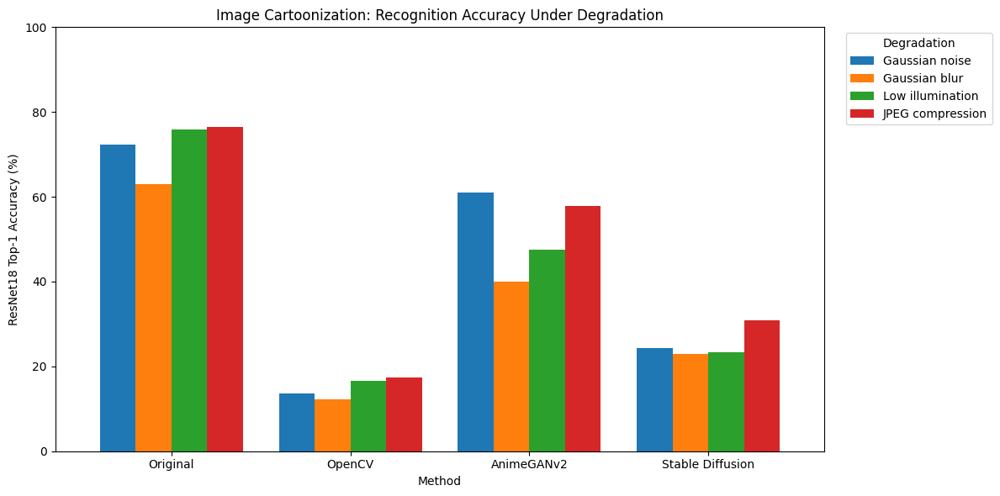

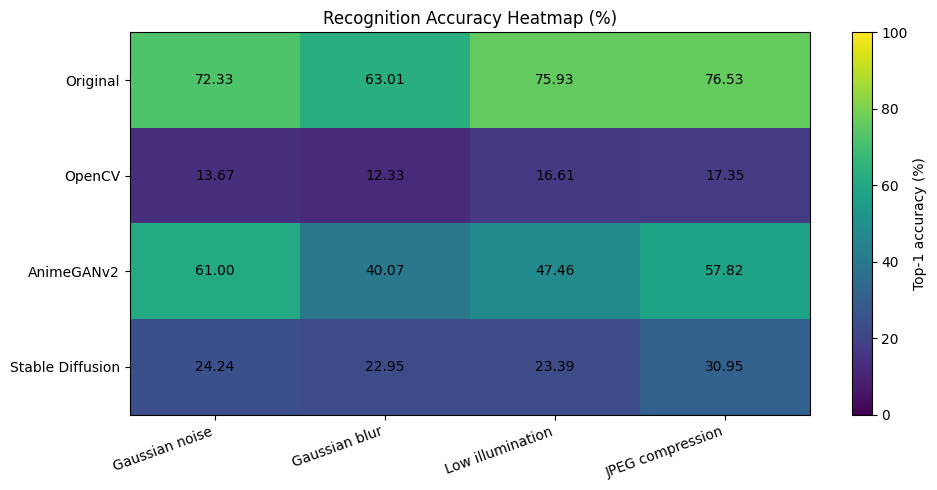

Graphs and master table created.
Master table: /content/research_dataset/final_research_outputs/master_recognition_results.csv
Grouped bar chart: /content/research_dataset/final_research_outputs/recognition_accuracy_comparison.png
Heatmap: /content/research_dataset/final_research_outputs/recognition_accuracy_heatmap.png
ZIP package: /content/research_dataset/cartoonization_research_results.zip


In [136]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile

base = Path("/content/research_dataset")
output_dir = base / "final_research_outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# Load the master results already created
df = pd.read_csv(base / "master_recognition_results.csv")

# Create a consistent table for plotting
pivot = df.pivot(
    index="Method",
    columns="Condition",
    values="Top1 accuracy (%)"
)

condition_order = [
    "Gaussian noise",
    "Gaussian blur",
    "Low illumination",
    "JPEG compression"
]
method_order = [
    "Original",
    "OpenCV",
    "AnimeGANv2",
    "Stable Diffusion"
]

pivot = pivot.reindex(index=method_order, columns=condition_order)

# Graph 1: Grouped bar chart
ax = pivot.plot(kind="bar", figsize=(12, 6), width=0.8)
ax.set_title("Image Cartoonization: Recognition Accuracy Under Degradation")
ax.set_xlabel("Method")
ax.set_ylabel("ResNet18 Top-1 Accuracy (%)")
ax.set_ylim(0, 100)
ax.legend(title="Degradation", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()

bar_path = output_dir / "recognition_accuracy_comparison.png"
plt.savefig(bar_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Graph 2: Accuracy heatmap
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(pivot.values, aspect="auto", vmin=0, vmax=100)

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=20, ha="right")
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_title("Recognition Accuracy Heatmap (%)")

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        value = pivot.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center")

fig.colorbar(im, ax=ax, label="Top-1 accuracy (%)")
plt.tight_layout()

heatmap_path = output_dir / "recognition_accuracy_heatmap.png"
plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Save a clean results table
table_path = output_dir / "master_recognition_results.csv"
df.to_csv(table_path, index=False)

# Package the outputs
zip_path = base / "cartoonization_research_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(table_path, arcname="master_recognition_results.csv")
    z.write(bar_path, arcname="recognition_accuracy_comparison.png")
    z.write(heatmap_path, arcname="recognition_accuracy_heatmap.png")

print("Graphs and master table created.")
print("Master table:", table_path)
print("Grouped bar chart:", bar_path)
print("Heatmap:", heatmap_path)
print("ZIP package:", zip_path)

In [137]:
from google.colab import files

files.download(
    "/content/research_dataset/cartoonization_research_results.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [138]:
import os

zip_path = "/content/research_dataset/cartoonization_research_results.zip"

print("ZIP exists:", os.path.exists(zip_path))
if os.path.exists(zip_path):
    print("ZIP size:", round(os.path.getsize(zip_path) / 1024, 2), "KB")

ZIP exists: True
ZIP size: 279.76 KB


In [139]:
from google.colab import files

files.download(
    "/content/research_dataset/cartoonization_research_results.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [140]:
from pathlib import Path
import zipfile
from google.colab import files

base = Path("/content/research_dataset")
backup = base / "complete_research_backup.zip"

# Exclude the backup itself and temporary cache folders
with zipfile.ZipFile(backup, "w", zipfile.ZIP_DEFLATED) as z:
    for path in base.rglob("*"):
        if not path.is_file():
            continue
        if path == backup or "__pycache__" in path.parts:
            continue

        z.write(path, arcname=str(path.relative_to(base)))

print("Backup created:", backup)
print("Backup size:", round(backup.stat().st_size / (1024 * 1024), 2), "MB")

files.download(str(backup))

KeyboardInterrupt: 

In [141]:
from pathlib import Path

base = Path("/content/research_dataset")

print("Research folder exists:", base.exists())

backup = base / "complete_research_backup.zip"
print("Complete backup exists:", backup.exists())

if backup.exists():
    print("Backup size:", round(backup.stat().st_size / (1024 * 1024), 2), "MB")

print("\nImportant result files:")
for pattern in ["*results*.csv", "*predictions*.csv", "*comparison*.csv",
                "*manifest*.csv", "master_recognition_results.csv"]:
    matches = list(base.rglob(pattern))
    for path in matches:
        print(path.relative_to(base))

Research folder exists: True
Complete backup exists: True
Backup size: 628.1 MB

Important result files:
jpeg_compression_animegan2_results.csv
gaussian_blur_stable_diffusion_results.csv
master_recognition_results.csv
opencv_results.csv
gaussian_noise_animegan2_results.csv
animegan2_results.csv
gaussian_blur_opencv_results.csv
jpeg_compression_opencv_results.csv
gaussian_blur_animegan2_results.csv
gaussian_noise_opencv_results.csv
jpeg_compression_stable_diffusion_results.csv
stable_diffusion_results.csv
gaussian_noise_stable_diffusion_results.csv
low_illumination_opencv_results.csv
stable_diffusion_results_clean.csv
low_illumination_stable_diffusion_results.csv
low_illumination_animegan2_results.csv
final_research_outputs/master_recognition_results.csv
resnet18_low_illumination_stable_diffusion_predictions.csv
resnet18_gaussian_blur_opencv_predictions.csv
resnet18_original_predictions.csv
resnet18_low_illumination_original_predictions.csv
resnet18_jpeg_compression_opencv_predictions.c

In [142]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

files_to_check = [
    "resnet18_original_predictions.csv",
    "resnet18_opencv_predictions.csv",
    "resnet18_animegan2_predictions.csv",
    "resnet18_stable_diffusion_predictions.csv",
]

for filename in files_to_check:
    path = base / filename
    print(f"\n{'=' * 55}")
    print(filename)

    if path.exists():
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    else:
        print("File not found")


resnet18_original_predictions.csv
Rows: 300
Columns: ['image_path', 'class_label', 'target_index', 'predicted_index', 'correct']
                                                                  image_path class_label  target_index  predicted_index  correct
/content/research_dataset/imagenette2-320/val/n01440764/n01440764_21161.JPEG   n01440764             0                0     True
 /content/research_dataset/imagenette2-320/val/n01440764/n01440764_9720.JPEG   n01440764             0                0     True
 /content/research_dataset/imagenette2-320/val/n01440764/n01440764_4341.JPEG   n01440764             0                0     True

resnet18_opencv_predictions.csv
Rows: 300
Columns: ['image_path', 'class_label', 'predicted_index', 'correct']
                                                                  image_path class_label  predicted_index  correct
/content/research_dataset/imagenette2-320/val/n01440764/n01440764_21161.JPEG   n01440764              251    False
 /content/re

In [143]:
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")

original = pd.read_csv(
    base / "resnet18_original_predictions.csv"
)

methods = {
    "OpenCV": "resnet18_opencv_predictions.csv",
    "AnimeGANv2": "resnet18_animegan2_predictions.csv",
    "Stable Diffusion": "resnet18_stable_diffusion_predictions.csv",
}

results = []

for method, filename in methods.items():
    transformed = pd.read_csv(base / filename)

    # Match the same source images
    paired = original[
        ["image_path", "predicted_index", "correct"]
    ].merge(
        transformed[
            ["image_path", "predicted_index", "correct"]
        ],
        on="image_path",
        how="inner",
        suffixes=("_original", "_transformed")
    )

    # Prediction consistency: same predicted class before and after
    paired["prediction_consistent"] = (
        paired["predicted_index_original"]
        == paired["predicted_index_transformed"]
    )

    results.append({
        "Method": method,
        "Matched images": len(paired),
        "Prediction consistency (%)": round(
            100 * paired["prediction_consistent"].mean(), 2
        ),
        "Original accuracy on matched images (%)": round(
            100 * paired["correct_original"].mean(), 2
        ),
        "Transformed accuracy (%)": round(
            100 * paired["correct_transformed"].mean(), 2
        ),
    })

summary = pd.DataFrame(results)

output_path = base / "prediction_consistency_summary.csv"
summary.to_csv(output_path, index=False)

print(summary.to_string(index=False))
print("\nSaved:", output_path)

          Method  Matched images  Prediction consistency (%)  Original accuracy on matched images (%)  Transformed accuracy (%)
          OpenCV             300                       21.00                                    80.67                     18.33
      AnimeGANv2             300                       65.33                                    80.67                     59.33
Stable Diffusion             294                       34.69                                    80.61                     33.33

Saved: /content/research_dataset/prediction_consistency_summary.csv


In [144]:
from pathlib import Path

base = Path("/content/research_dataset")

folders = [
    "opencv_cartoon",
    "animegan2_cartoon",
    "stable_diffusion_cartoon",
]

for folder in folders:
    path = base / folder
    images = (
        list(path.glob("*.png")) +
        list(path.glob("*.jpg")) +
        list(path.glob("*.jpeg"))
    ) if path.exists() else []

    print(f"{folder}:")
    print("  Folder exists:", path.exists())
    print("  Images found:", len(images))
    if images:
        print("  Example:", images[0].name)

opencv_cartoon:
  Folder exists: True
  Images found: 300
  Example: 0297_n03888257_15382.png
animegan2_cartoon:
  Folder exists: True
  Images found: 300
  Example: 0246.png
stable_diffusion_cartoon:
  Folder exists: True
  Images found: 300
  Example: 0246.png


In [145]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

base = Path("/content/research_dataset")
manifest = pd.read_csv(base / "selected_300_images.csv")

folders = {
    "OpenCV": "opencv_cartoon",
    "AnimeGANv2": "animegan2_cartoon",
    "Stable Diffusion": "stable_diffusion_cartoon",
}

rows = []

for _, item in manifest.iterrows():
    original_path = Path(item["image_path"])
    image_id = original_path.stem

    original = cv2.imread(str(original_path))
    if original is None:
        continue

    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (256, 256))

    for method, folder in folders.items():
        output_folder = base / folder

        # OpenCV outputs use the source filename with .png extension.
        # AnimeGANv2 and Stable Diffusion outputs use zero-padded indices.
        if method == "OpenCV":
            candidates = [
                output_folder / f"{image_id}.png",
                output_folder / f"{image_id}.jpg",
            ]
        else:
            idx = manifest.index[manifest["image_path"] == item["image_path"]][0]
            candidates = [
                output_folder / f"{idx:04d}.png",
                output_folder / f"{idx:04d}.jpg",
            ]

        output_path = next((p for p in candidates if p.exists()), None)

        if output_path is None:
            continue

        cartoon = cv2.imread(str(output_path))
        if cartoon is None or cartoon.mean() < 1:
            continue

        cartoon = cv2.cvtColor(cartoon, cv2.COLOR_BGR2RGB)
        cartoon = cv2.resize(cartoon, (256, 256))

        rows.append({
            "Image": image_id,
            "Method": method,
            "SSIM": structural_similarity(
                original, cartoon, channel_axis=2, data_range=255
            ),
            "PSNR_dB": peak_signal_noise_ratio(
                original, cartoon, data_range=255
            ),
        })

metrics = pd.DataFrame(rows)
summary = metrics.groupby("Method").agg(
    Images_evaluated=("Image", "count"),
    Mean_SSIM=("SSIM", "mean"),
    Mean_PSNR_dB=("PSNR_dB", "mean"),
).reset_index()

summary[["Mean_SSIM", "Mean_PSNR_dB"]] = summary[
    ["Mean_SSIM", "Mean_PSNR_dB"]
].round(4)

metrics.to_csv(base / "image_quality_per_image.csv", index=False)
summary.to_csv(base / "image_quality_summary.csv", index=False)

print("IMAGE QUALITY SUMMARY")
print(summary.to_string(index=False))
print("\nSaved image_quality_per_image.csv")
print("Saved image_quality_summary.csv")

IMAGE QUALITY SUMMARY
          Method  Images_evaluated  Mean_SSIM  Mean_PSNR_dB
      AnimeGANv2               300     0.6564       18.5636
Stable Diffusion               294     0.4747       18.3549

Saved image_quality_per_image.csv
Saved image_quality_summary.csv


In [146]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

base = Path("/content/research_dataset")
manifest = pd.read_csv(base / "selected_300_images.csv")

folders = {
    "OpenCV": "opencv_cartoon",
    "AnimeGANv2": "animegan2_cartoon",
    "Stable Diffusion": "stable_diffusion_cartoon",
}

rows = []
missing = {method: 0 for method in folders}
black = {method: 0 for method in folders}

for idx, item in manifest.iterrows():
    image_path = Path(item["image_path"])
    image_id = image_path.stem

    original = cv2.imread(str(image_path))
    if original is None:
        continue

    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (256, 256))

    for method, folder in folders.items():
        out_dir = base / folder

        if method == "OpenCV":
            candidates = [
                out_dir / f"{idx:04d}_{image_id}.png",
                out_dir / f"{idx:04d}_{image_id}.jpg",
                out_dir / f"{image_id}.png",
                out_dir / f"{image_id}.jpg",
            ]
        else:
            candidates = [
                out_dir / f"{idx:04d}.png",
                out_dir / f"{idx:04d}.jpg",
                out_dir / f"{idx:04d}.jpeg",
            ]

        out_path = next((p for p in candidates if p.exists()), None)

        if out_path is None:
            missing[method] += 1
            continue

        cartoon = cv2.imread(str(out_path))
        if cartoon is None:
            missing[method] += 1
            continue

        if cartoon.mean() < 1:
            black[method] += 1
            continue

        cartoon = cv2.cvtColor(cartoon, cv2.COLOR_BGR2RGB)
        cartoon = cv2.resize(cartoon, (256, 256))

        rows.append({
            "Image": image_id,
            "Method": method,
            "SSIM": structural_similarity(
                original, cartoon, channel_axis=2, data_range=255
            ),
            "PSNR_dB": peak_signal_noise_ratio(
                original, cartoon, data_range=255
            ),
        })

metrics = pd.DataFrame(rows)
summary = metrics.groupby("Method").agg(
    Images_evaluated=("Image", "count"),
    Mean_SSIM=("SSIM", "mean"),
    Mean_PSNR_dB=("PSNR_dB", "mean"),
).reset_index()

summary[["Mean_SSIM", "Mean_PSNR_dB"]] = summary[
    ["Mean_SSIM", "Mean_PSNR_dB"]
].round(4)

metrics.to_csv(base / "image_quality_per_image.csv", index=False)
summary.to_csv(base / "image_quality_summary.csv", index=False)

print("CORRECTED IMAGE QUALITY SUMMARY")
print(summary.to_string(index=False))
print("\nMissing outputs:", missing)
print("Black outputs:", black)
print("\nSaved corrected per-image and summary CSV files.")

CORRECTED IMAGE QUALITY SUMMARY
          Method  Images_evaluated  Mean_SSIM  Mean_PSNR_dB
      AnimeGANv2               300     0.6564       18.5636
          OpenCV               300     0.6469       17.6617
Stable Diffusion               294     0.4747       18.3549

Missing outputs: {'OpenCV': 0, 'AnimeGANv2': 0, 'Stable Diffusion': 0}
Black outputs: {'OpenCV': 0, 'AnimeGANv2': 0, 'Stable Diffusion': 6}

Saved corrected per-image and summary CSV files.


In [147]:
import pandas as pd
from pathlib import Path
import zipfile

base = Path("/content/research_dataset")
out = base / "final_research_outputs"
out.mkdir(exist_ok=True)

# Existing clean-image recognition results
clean_accuracy = pd.DataFrame({
    "Method": ["Original", "OpenCV", "AnimeGANv2", "Stable Diffusion"],
    "Clean recognition accuracy (%)": [80.67, 18.33, 59.33, 33.33],
})

# Previously calculated evaluation metrics
consistency = pd.read_csv(base / "prediction_consistency_summary.csv")
quality = pd.read_csv(base / "image_quality_summary.csv")

consistency = consistency[
    ["Method", "Matched images", "Prediction consistency (%)"]
]

quality = quality.rename(columns={
    "Images_evaluated": "Quality images evaluated",
    "Mean_SSIM": "Mean SSIM",
    "Mean_PSNR_dB": "Mean PSNR (dB)",
})

quality = quality[
    ["Method", "Quality images evaluated", "Mean SSIM", "Mean PSNR (dB)"]
]

final_summary = clean_accuracy.merge(consistency, on="Method", how="left")
final_summary = final_summary.merge(quality, on="Method", how="left")

summary_path = out / "final_method_summary.csv"
final_summary.to_csv(summary_path, index=False)

print("FINAL METHOD SUMMARY")
print(final_summary.round(4).to_string(index=False))

# Make a compact ZIP containing key results and graphs
files_to_include = [
    summary_path,
    base / "master_recognition_results.csv",
    base / "prediction_consistency_summary.csv",
    base / "image_quality_summary.csv",
    base / "image_quality_per_image.csv",
    out / "recognition_accuracy_comparison.png",
    out / "recognition_accuracy_heatmap.png",
]

zip_path = base / "final_research_results_package.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in files_to_include:
        if path.exists():
            z.write(path, arcname=path.name)

print("\nFinal results package:", zip_path)
print("Package size:", round(zip_path.stat().st_size / 1024, 2), "KB")

FINAL METHOD SUMMARY
          Method  Clean recognition accuracy (%)  Matched images  Prediction consistency (%)  Quality images evaluated  Mean SSIM  Mean PSNR (dB)
        Original                           80.67             NaN                         NaN                       NaN        NaN             NaN
          OpenCV                           18.33           300.0                       21.00                     300.0     0.6469         17.6617
      AnimeGANv2                           59.33           300.0                       65.33                     300.0     0.6564         18.5636
Stable Diffusion                           33.33           294.0                       34.69                     294.0     0.4747         18.3549

Final results package: /content/research_dataset/final_research_results_package.zip
Package size: 300.83 KB


In [148]:

from google.colab import files

files.download(
    "/content/research_dataset/final_research_results_package.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [149]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import binomtest, binom, wilcoxon
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.contingency_tables import mcnemar

base = Path("/content/research_dataset")

files = {
    "Original": "resnet18_original_predictions.csv",
    "OpenCV": "resnet18_opencv_predictions.csv",
    "AnimeGANv2": "resnet18_animegan2_predictions.csv",
    "Stable Diffusion": "resnet18_stable_diffusion_predictions.csv",
}

data = {}

for method, filename in files.items():
    df = pd.read_csv(base / filename)
    data[method] = df[["image_path", "correct"]].copy()

# 1. Accuracy and Wilson 95% confidence intervals
summary = []

for method, df in data.items():
    n = len(df)
    correct = int(df["correct"].astype(bool).sum())
    low, high = proportion_confint(correct, n, alpha=0.05, method="wilson")

    summary.append({
        "Method": method,
        "N": n,
        "Correct": correct,
        "Accuracy (%)": 100 * correct / n,
        "95% CI lower (%)": 100 * low,
        "95% CI upper (%)": 100 * high,
    })

summary_df = pd.DataFrame(summary).round(2)

print("ACCURACY WITH 95% WILSON CONFIDENCE INTERVALS")
print(summary_df.to_string(index=False))

# 2. Paired McNemar tests: compare correctness on identical images
print("\nPAIRED MCNEMAR TESTS")
comparisons = [
    ("Original", "OpenCV"),
    ("Original", "AnimeGANv2"),
    ("Original", "Stable Diffusion"),
    ("OpenCV", "AnimeGANv2"),
    ("OpenCV", "Stable Diffusion"),
    ("AnimeGANv2", "Stable Diffusion"),
]

test_rows = []

for a, b in comparisons:
    paired = data[a].merge(
        data[b],
        on="image_path",
        suffixes=("_a", "_b"),
        how="inner"
    )

    ca = paired["correct_a"].astype(bool)
    cb = paired["correct_b"].astype(bool)

    # Discordant pairs: one method correct and the other incorrect
    b01 = int((ca & ~cb).sum())
    b10 = int((~ca & cb).sum())

    table = [[0, b01], [b10, 0]]
    result = mcnemar(table, exact=True)

    test_rows.append({
        "Comparison": f"{a} vs {b}",
        "Matched N": len(paired),
        "A correct, B wrong": b01,
        "A wrong, B correct": b10,
        "McNemar p-value": result.pvalue,
    })

tests_df = pd.DataFrame(test_rows)

# Bonferroni correction for six comparisons
tests_df["Adjusted p-value"] = np.minimum(
    tests_df["McNemar p-value"] * len(tests_df), 1.0
)
tests_df["Significant after correction"] = (
    tests_df["Adjusted p-value"] < 0.05
)

print("\nPAIRED TEST RESULTS")
print(tests_df.round(5).to_string(index=False))

summary_df.to_csv(base / "accuracy_confidence_intervals.csv", index=False)
tests_df.to_csv(base / "paired_mcnemar_tests.csv", index=False)

print("\nSaved:")
print(base / "accuracy_confidence_intervals.csv")
print(base / "paired_mcnemar_tests.csv")

ACCURACY WITH 95% WILSON CONFIDENCE INTERVALS
          Method   N  Correct  Accuracy (%)  95% CI lower (%)  95% CI upper (%)
        Original 300      242         80.67             75.82             84.74
          OpenCV 300       55         18.33             14.36             23.10
      AnimeGANv2 300      178         59.33             53.69             64.74
Stable Diffusion 294       98         33.33             28.19             38.91

PAIRED MCNEMAR TESTS

PAIRED TEST RESULTS
                    Comparison  Matched N  A correct, B wrong  A wrong, B correct  McNemar p-value  Adjusted p-value  Significant after correction
            Original vs OpenCV        300                 187                   0              0.0               0.0                          True
        Original vs AnimeGANv2        300                  72                   8              0.0               0.0                          True
  Original vs Stable Diffusion        294                 147         

In [150]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import binom
from statsmodels.stats.multitest import multipletests

base = Path("/content/research_dataset")
rng = np.random.default_rng(42)

files = {
    "Original": "resnet18_original_predictions.csv",
    "OpenCV": "resnet18_opencv_predictions.csv",
    "AnimeGANv2": "resnet18_animegan2_predictions.csv",
    "Stable Diffusion": "resnet18_stable_diffusion_predictions.csv",
}

data = {}
for method, filename in files.items():
    df = pd.read_csv(base / filename)
    data[method] = df[["image_path", "correct"]].copy()

pairs = [
    ("Original", "OpenCV"),
    ("Original", "AnimeGANv2"),
    ("Original", "Stable Diffusion"),
    ("OpenCV", "AnimeGANv2"),
    ("OpenCV", "Stable Diffusion"),
    ("AnimeGANv2", "Stable Diffusion"),
]

results = []

for a, b in pairs:
    paired = data[a].merge(
        data[b], on="image_path", how="inner",
        suffixes=("_a", "_b")
    )

    ca = paired["correct_a"].astype(bool).to_numpy()
    cb = paired["correct_b"].astype(bool).to_numpy()
    n = len(paired)

    # Paired difference in accuracy, in percentage points
    diff = (ca.astype(float) - cb.astype(float)) * 100
    observed = diff.mean()

    # Paired bootstrap 95% confidence interval
    boot = np.empty(5000)
    for i in range(len(boot)):
        sample = rng.integers(0, n, n)
        boot[i] = diff[sample].mean()

    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

    # Exact two-sided McNemar p-value, retained on log10 scale
    a_correct_b_wrong = int((ca & ~cb).sum())
    a_wrong_b_correct = int((~ca & cb).sum())
    discordant = a_correct_b_wrong + a_wrong_b_correct

    if discordant == 0:
        log10_p = 0.0
    else:
        k = min(a_correct_b_wrong, a_wrong_b_correct)
        log10_p = np.log10(2) + binom.logcdf(
            k, discordant, 0.5
        ) / np.log(10)

    results.append({
        "Comparison": f"{a} - {b}",
        "Matched N": n,
        "Accuracy difference (pp)": observed,
        "Bootstrap CI lower (pp)": ci_low,
        "Bootstrap CI upper (pp)": ci_high,
        "log10 McNemar p": log10_p,
    })

results_df = pd.DataFrame(results)

# Holm correction using log p-values to avoid underflow
logp = results_df["log10 McNemar p"].to_numpy()
order = np.argsort(logp)
adjusted_logp = np.empty(len(logp))
running = -np.inf

for rank, idx in enumerate(order):
    candidate = logp[idx] + np.log10(len(logp) - rank)
    running = max(running, candidate)
    adjusted_logp[idx] = min(running, 0.0)

results_df["log10 adjusted p"] = adjusted_logp

results_df = results_df.round(4)
print(results_df.to_string(index=False))

results_df.to_csv(
    base / "paired_effects_confidence_intervals.csv",
    index=False
)

print("\nSaved paired_effects_confidence_intervals.csv")

                   Comparison  Matched N  Accuracy difference (pp)  Bootstrap CI lower (pp)  Bootstrap CI upper (pp)  log10 McNemar p  log10 adjusted p
            Original - OpenCV        300                   62.3333                  57.0000                  68.0000         -55.9916          -55.2134
        Original - AnimeGANv2        300                   21.3333                  16.0000                  26.6667         -13.2696          -12.7925
  Original - Stable Diffusion        294                   47.2789                  40.8163                  53.4014         -33.4973          -32.7983
          OpenCV - AnimeGANv2        300                  -41.0000                 -47.0000                 -35.0000         -30.4419          -29.8399
    OpenCV - Stable Diffusion        294                  -15.3061                 -21.0884                  -9.5238          -6.1313           -6.1313
AnimeGANv2 - Stable Diffusion        294                   25.8503                  19.0

In [151]:
from pathlib import Path
import zipfile

base = Path("/content/research_dataset")
out = base / "final_research_outputs"

files_to_include = [
    base / "accuracy_confidence_intervals.csv",
    base / "paired_mcnemar_tests.csv",
    base / "paired_effects_confidence_intervals.csv",
    base / "prediction_consistency_summary.csv",
    base / "image_quality_summary.csv",
    base / "image_quality_per_image.csv",
    base / "master_recognition_results.csv",
    out / "final_method_summary.csv",
    out / "recognition_accuracy_comparison.png",
    out / "recognition_accuracy_heatmap.png",
]

zip_path = base / "final_research_results_package.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in files_to_include:
        if path.exists():
            z.write(path, arcname=path.name)

print("Updated package:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1024, 2), "KB")
print("Files included:", len(zipfile.ZipFile(zip_path).namelist()))

Updated package: /content/research_dataset/final_research_results_package.zip
Size: 302.05 KB
Files included: 10


PER-CLASS ACCURACY (%)
Method           Original  OpenCV  AnimeGANv2  Stable Diffusion
Category                                                       
Cassette player     40.00    0.00       23.33             13.33
Chain saw           86.67   20.00       46.67             20.69
Church              60.00   13.33       53.33             48.28
French horn         86.67   10.00       70.00             31.03
Garbage truck       80.00   13.33       56.67             60.00
Gas pump           100.00   33.33       73.33             36.67
Golf ball           93.33   40.00       80.00             28.57
Parachute           76.67   46.67       63.33             48.28
Springer            93.33    6.67       43.33             16.67
Tench               90.00    0.00       83.33             30.00


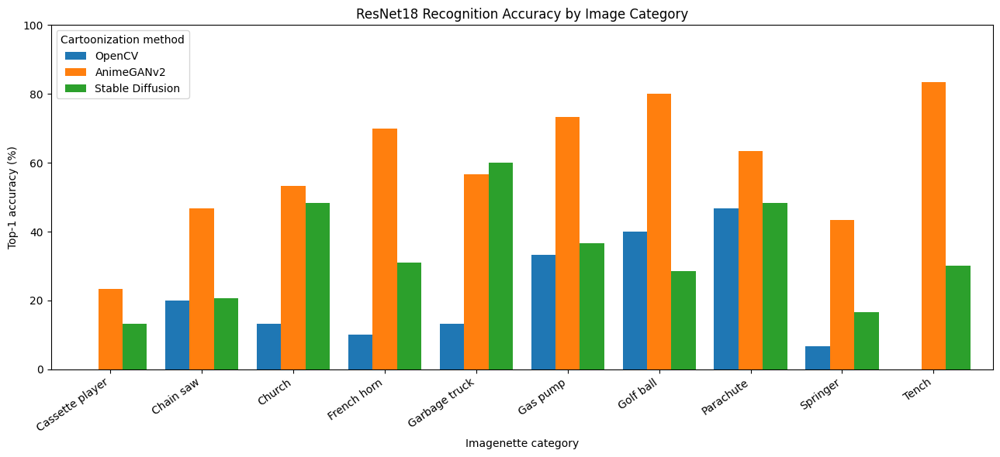


Saved:
/content/research_dataset/per_class_recognition_results.csv
/content/research_dataset/per_class_accuracy_pivot.csv
/content/research_dataset/per_class_accuracy_comparison.png


In [152]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = Path("/content/research_dataset")

files = {
    "Original": "resnet18_original_predictions.csv",
    "OpenCV": "resnet18_opencv_predictions.csv",
    "AnimeGANv2": "resnet18_animegan2_predictions.csv",
    "Stable Diffusion": "resnet18_stable_diffusion_predictions.csv",
}

all_results = []

for method, filename in files.items():
    df = pd.read_csv(base / filename)

    # Calculate accuracy within each ground-truth class
    grouped = df.groupby("class_label")["correct"].agg(
        Images="count",
        Correct="sum",
        Accuracy=lambda x: 100 * x.astype(bool).mean()
    ).reset_index()

    grouped["Method"] = method
    all_results.append(grouped)

per_class = pd.concat(all_results, ignore_index=True)

# Readable Imagenette class names
class_names = {
    "n01440764": "Tench",
    "n02102040": "Springer",
    "n02979186": "Cassette player",
    "n03000684": "Chain saw",
    "n03028079": "Church",
    "n03394916": "French horn",
    "n03417042": "Garbage truck",
    "n03425413": "Gas pump",
    "n03445777": "Golf ball",
    "n03888257": "Parachute",
}

per_class["Category"] = per_class["class_label"].map(class_names)

# Save detailed results
detail_path = base / "per_class_recognition_results.csv"
per_class.to_csv(detail_path, index=False)

# Pivot table
pivot = per_class.pivot(
    index="Category",
    columns="Method",
    values="Accuracy"
)

method_order = ["Original", "OpenCV", "AnimeGANv2", "Stable Diffusion"]
pivot = pivot.reindex(columns=method_order)

pivot_path = base / "per_class_accuracy_pivot.csv"
pivot.to_csv(pivot_path)

print("PER-CLASS ACCURACY (%)")
print(pivot.round(2).to_string())

# Plot only the three cartoonization methods for easier comparison
cartoon_methods = ["OpenCV", "AnimeGANv2", "Stable Diffusion"]
ax = pivot[cartoon_methods].plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

ax.set_title("ResNet18 Recognition Accuracy by Image Category")
ax.set_xlabel("Imagenette category")
ax.set_ylabel("Top-1 accuracy (%)")
ax.set_ylim(0, 100)
ax.legend(title="Cartoonization method")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plot_path = base / "per_class_accuracy_comparison.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("\nSaved:")
print(detail_path)
print(pivot_path)
print(plot_path)

In [153]:
from pathlib import Path
import zipfile

base = Path("/content/research_dataset")
out = base / "final_research_outputs"
out.mkdir(exist_ok=True)

# Files for the compact research-results package
files_to_include = [
    base / "master_recognition_results.csv",
    base / "prediction_consistency_summary.csv",
    base / "image_quality_summary.csv",
    base / "image_quality_per_image.csv",
    base / "accuracy_confidence_intervals.csv",
    base / "paired_mcnemar_tests.csv",
    base / "paired_effects_confidence_intervals.csv",
    base / "per_class_recognition_results.csv",
    base / "per_class_accuracy_pivot.csv",
    base / "per_class_accuracy_comparison.png",
    base / "final_research_outputs" / "final_method_summary.csv",
    base / "final_research_outputs" / "recognition_accuracy_comparison.png",
    base / "final_research_outputs" / "recognition_accuracy_heatmap.png",
]

zip_path = base / "final_research_results_package.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in files_to_include:
        if path.exists():
            z.write(path, arcname=path.name)

with zipfile.ZipFile(zip_path, "r") as z:
    print("Package created successfully.")
    print("Files included:", len(z.namelist()))
    print("Package size:", round(zip_path.stat().st_size / 1024, 2), "KB")
    print("\nIncluded files:")
    for name in z.namelist():
        print("-", name)

Package created successfully.
Files included: 13
Package size: 483.98 KB

Included files:
- master_recognition_results.csv
- prediction_consistency_summary.csv
- image_quality_summary.csv
- image_quality_per_image.csv
- accuracy_confidence_intervals.csv
- paired_mcnemar_tests.csv
- paired_effects_confidence_intervals.csv
- per_class_recognition_results.csv
- per_class_accuracy_pivot.csv
- per_class_accuracy_comparison.png
- final_method_summary.csv
- recognition_accuracy_comparison.png
- recognition_accuracy_heatmap.png


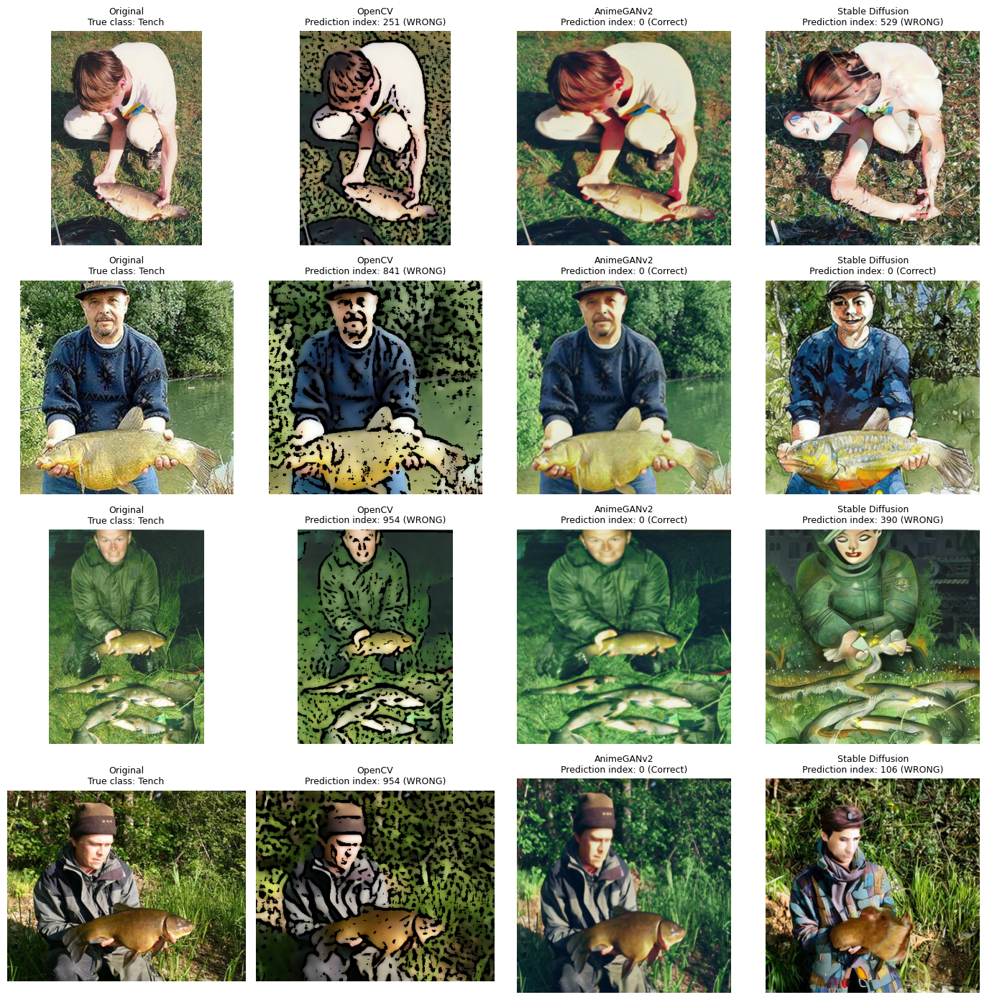

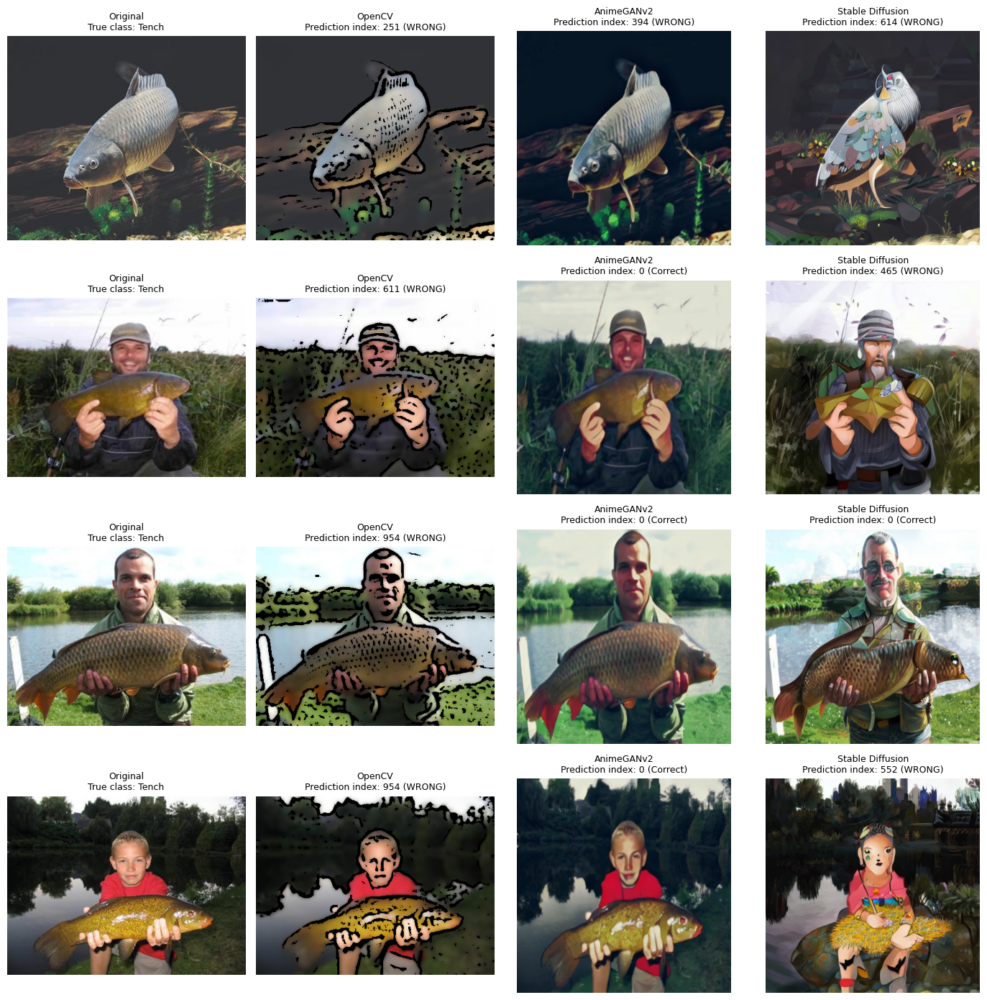

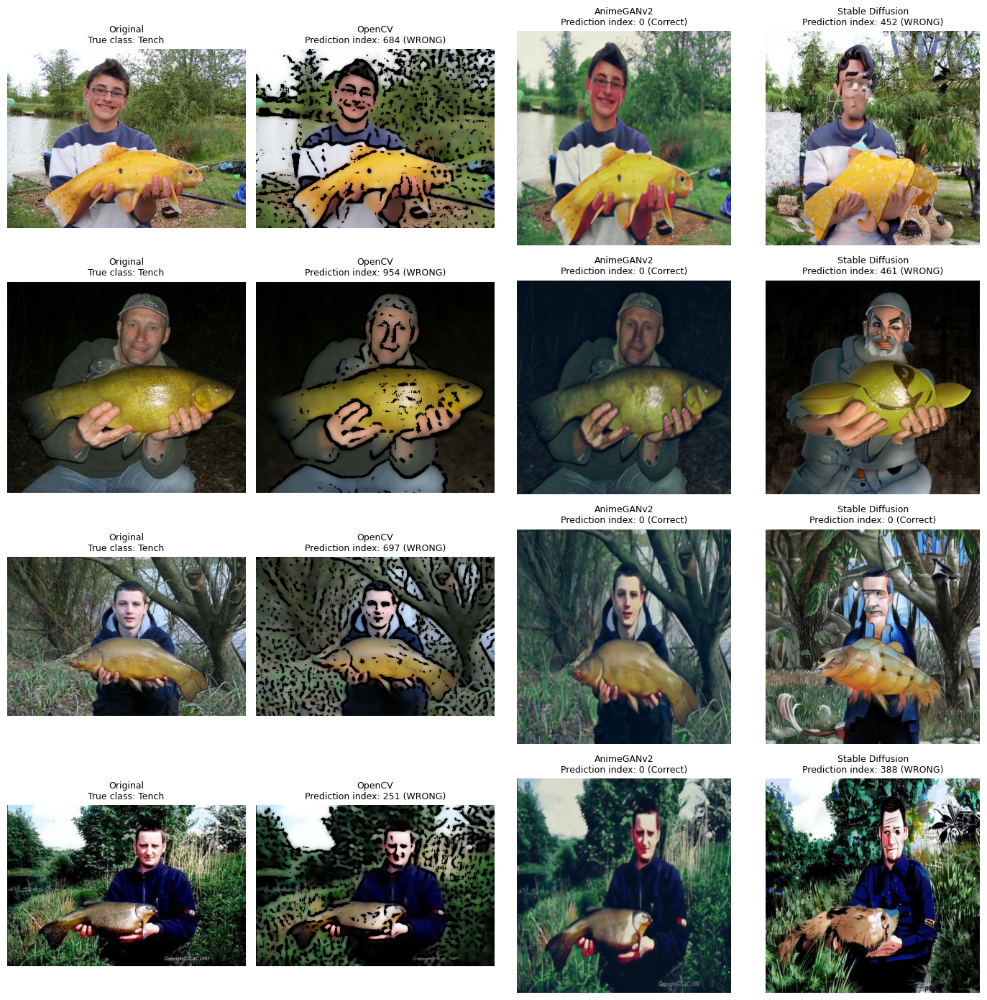


Failure cases selected: 12
Gallery folder: /content/research_dataset/failure_case_gallery
CSV: /content/research_dataset/failure_case_gallery/failure_cases.csv
Gallery images: 3


In [154]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import math

base = Path("/content/research_dataset")
output_dir = base / "failure_case_gallery"
output_dir.mkdir(exist_ok=True)

# Existing prediction files
files = {
    "Original": "resnet18_original_predictions.csv",
    "OpenCV": "resnet18_opencv_predictions.csv",
    "AnimeGANv2": "resnet18_animegan2_predictions.csv",
    "Stable Diffusion": "resnet18_stable_diffusion_predictions.csv",
}

predictions = {}
for method, filename in files.items():
    df = pd.read_csv(base / filename)
    predictions[method] = df.set_index("image_path")

# ImageNet class names for the ten Imagenette classes
labels = {
    "n01440764": "Tench",
    "n02102040": "English springer",
    "n02979186": "Cassette player",
    "n03000684": "Chain saw",
    "n03028079": "Church",
    "n03394916": "French horn",
    "n03417042": "Garbage truck",
    "n03425413": "Gas pump",
    "n03445777": "Golf ball",
    "n03888257": "Parachute",
}

# Select images where the original is correct but at least one
# cartoonization method is incorrect.
original = predictions["Original"]
opencv = predictions["OpenCV"]
animegan = predictions["AnimeGANv2"]
sd = predictions["Stable Diffusion"]

common = (
    original.index
    .intersection(opencv.index)
    .intersection(animegan.index)
    .intersection(sd.index)
)

failure_rows = []

for image_path in common:
    orig_correct = bool(original.loc[image_path, "correct"])

    if not orig_correct:
        continue

    method_correct = {
        method: bool(predictions[method].loc[image_path, "correct"])
        for method in ["OpenCV", "AnimeGANv2", "Stable Diffusion"]
    }

    if not all(method_correct.values()):
        failure_rows.append({
            "image_path": image_path,
            "True label": labels.get(
                original.loc[image_path, "class_label"],
                original.loc[image_path, "class_label"]
            ),
            "Original prediction": int(
                original.loc[image_path, "predicted_index"]
            ),
            "OpenCV prediction": int(
                opencv.loc[image_path, "predicted_index"]
            ),
            "AnimeGANv2 prediction": int(
                animegan.loc[image_path, "predicted_index"]
            ),
            "Stable Diffusion prediction": int(
                sd.loc[image_path, "predicted_index"]
            ),
            **{f"{m} correct": v for m, v in method_correct.items()}
        })

failures = pd.DataFrame(failure_rows)

if failures.empty:
    print("No matching failure cases found.")
else:
    # Choose up to 12 examples where at least one method fails.
    failures = failures.head(12)
    failures.to_csv(
        output_dir / "failure_cases.csv",
        index=False
    )

    # Find generated output filenames using the saved source ordering.
    manifest = pd.read_csv(base / "selected_300_images.csv")
    source_to_idx = {
        str(Path(row.image_path)): idx
        for idx, row in manifest.iterrows()
    }

    methods_to_show = [
        ("Original", None),
        ("OpenCV", "opencv_cartoon"),
        ("AnimeGANv2", "animegan2_cartoon"),
        ("Stable Diffusion", "stable_diffusion_cartoon"),
    ]

    def load_output(source_path, method, folder):
        if method == "Original":
            return Image.open(source_path).convert("RGB")

        idx = source_to_idx.get(str(Path(source_path)))
        if idx is None:
            return None

        out_dir = base / folder

        if method == "OpenCV":
            stem = Path(source_path).stem
            candidates = [
                out_dir / f"{idx:04d}_{stem}.png",
                out_dir / f"{stem}.png",
                out_dir / f"{idx:04d}_{stem}.jpg",
            ]
        else:
            candidates = [
                out_dir / f"{idx:04d}.png",
                out_dir / f"{idx:04d}.jpg",
            ]

        path = next((p for p in candidates if p.exists()), None)
        if path is None:
            return None

        return Image.open(path).convert("RGB")

    for start in range(0, len(failures), 4):
        batch = failures.iloc[start:start + 4]
        fig, axes = plt.subplots(
            len(batch), 4, figsize=(14, 3.5 * len(batch))
        )

        if len(batch) == 1:
            axes = [axes]

        for row_axes, (_, record) in zip(axes, batch.iterrows()):
            source = record["image_path"]

            for ax, (method, folder) in zip(row_axes, methods_to_show):
                image = load_output(source, method, folder)

                if image is not None:
                    ax.imshow(image)
                else:
                    ax.text(0.5, 0.5, "Image unavailable",
                            ha="center", va="center")

                if method == "Original":
                    prediction = record["True label"]
                else:
                    prediction = record[f"{method} prediction"]

                if method in ["OpenCV", "AnimeGANv2", "Stable Diffusion"]:
                    correct = record[f"{method} correct"]
                    status = "Correct" if correct else "WRONG"
                    title = f"{method}\nPrediction index: {prediction} ({status})"
                else:
                    title = f"Original\nTrue class: {record['True label']}"

                ax.set_title(title, fontsize=9)
                ax.axis("off")

        plt.tight_layout()
        page_path = output_dir / f"failure_gallery_{start // 4 + 1}.png"
        plt.savefig(page_path, dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()

    print("\nFailure cases selected:", len(failures))
    print("Gallery folder:", output_dir)
    print("CSV:", output_dir / "failure_cases.csv")
    print("Gallery images:", len(list(output_dir.glob("failure_gallery_*.png"))))

In [155]:
from pathlib import Path
import zipfile

base = Path("/content/research_dataset")
gallery = base / "failure_case_gallery"
zip_path = base / "final_research_results_package.zip"

with zipfile.ZipFile(zip_path, "a", zipfile.ZIP_DEFLATED) as z:
    for file in gallery.glob("*"):
        if file.is_file():
            z.write(file, arcname=f"failure_case_gallery/{file.name}")

print("Gallery added to:", zip_path)
print("Files included:")
for file in gallery.glob("*"):
    if file.is_file():
        print("-", file.name)
print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

Gallery added to: /content/research_dataset/final_research_results_package.zip
Files included:
- failure_gallery_3.png
- failure_gallery_2.png
- failure_cases.csv
- failure_gallery_1.png
ZIP size (MB): 17.24


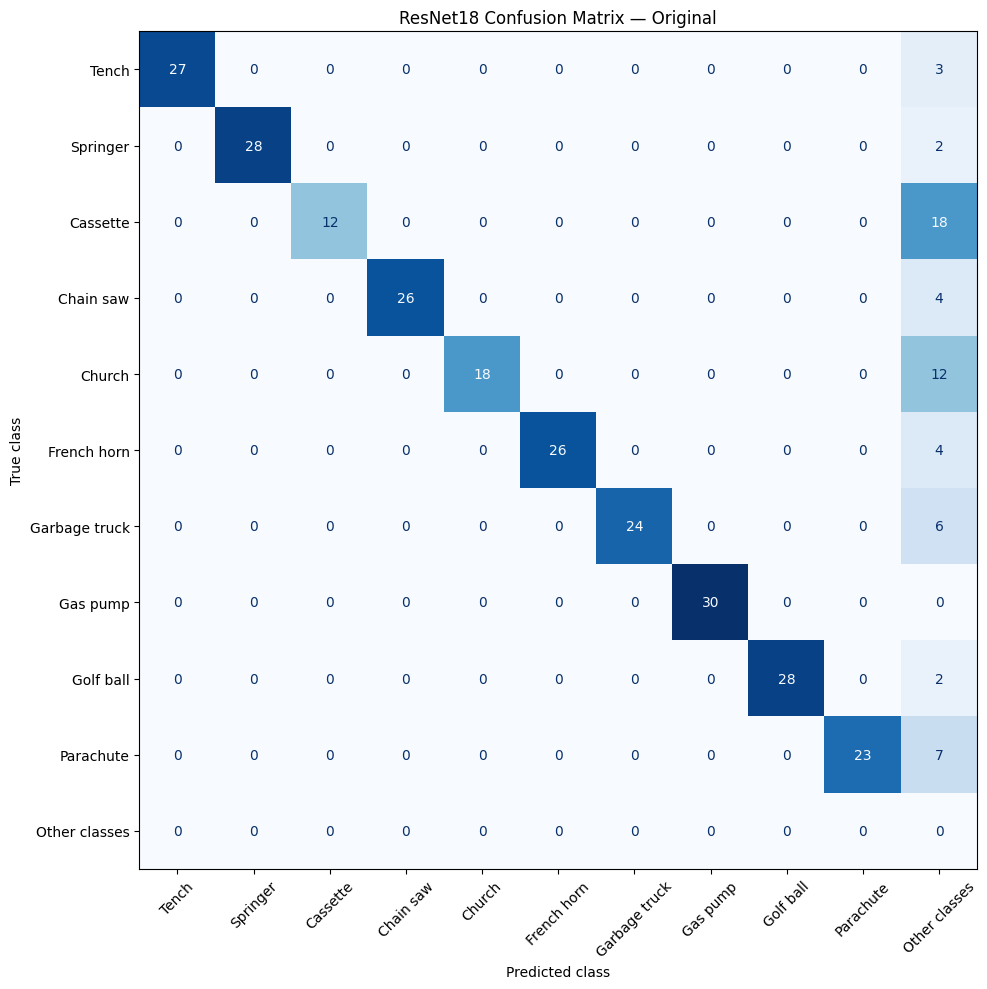

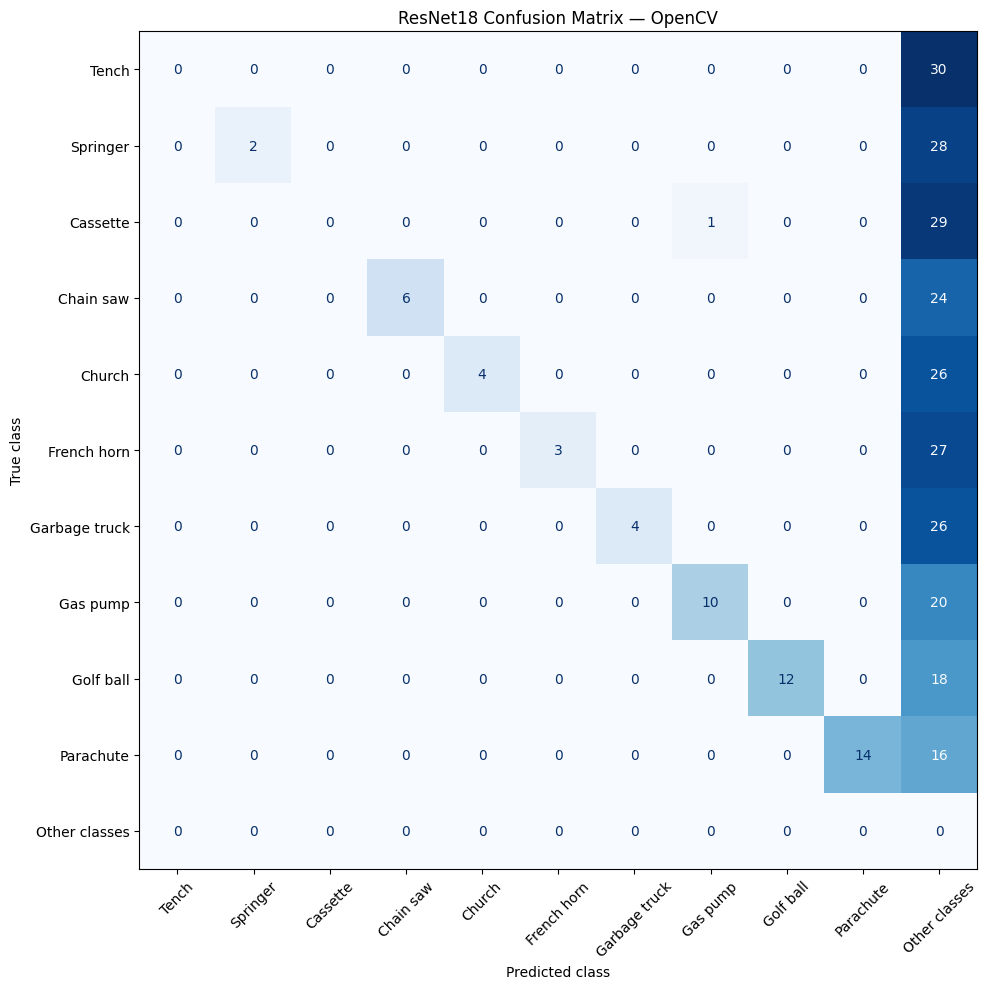

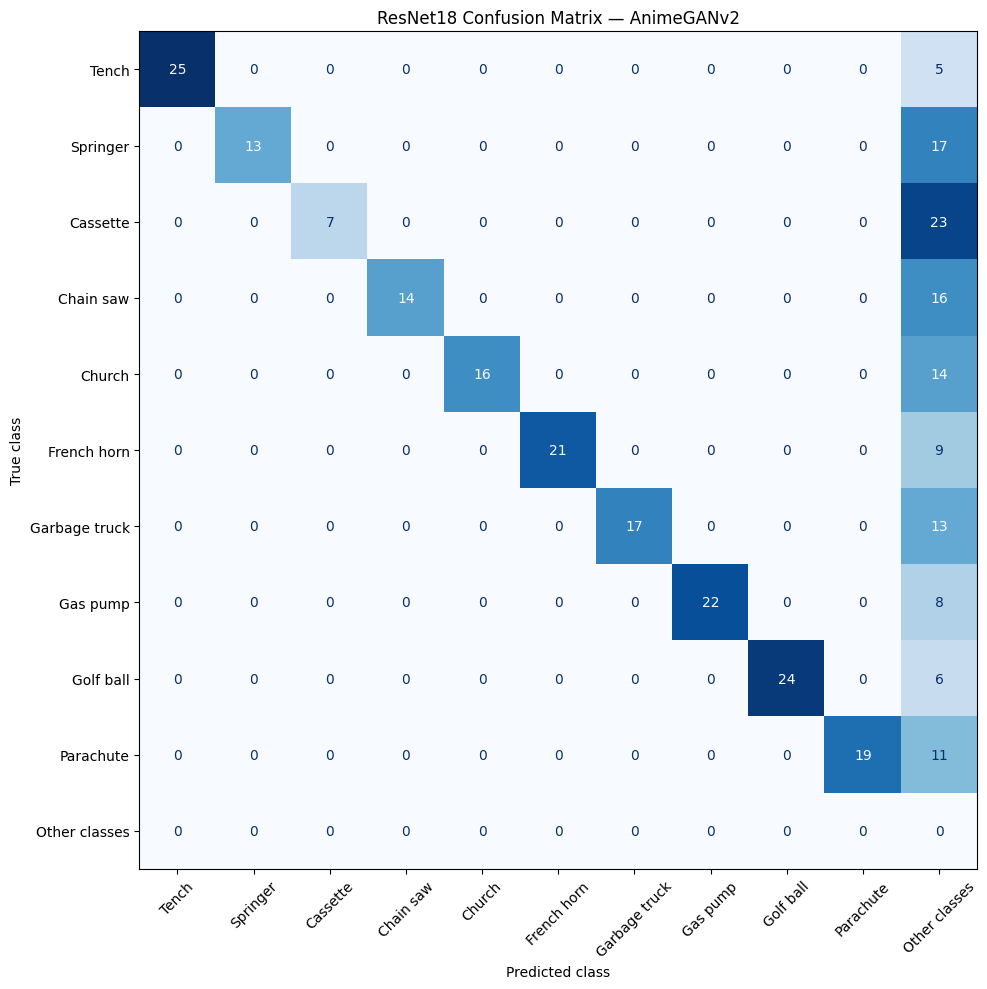

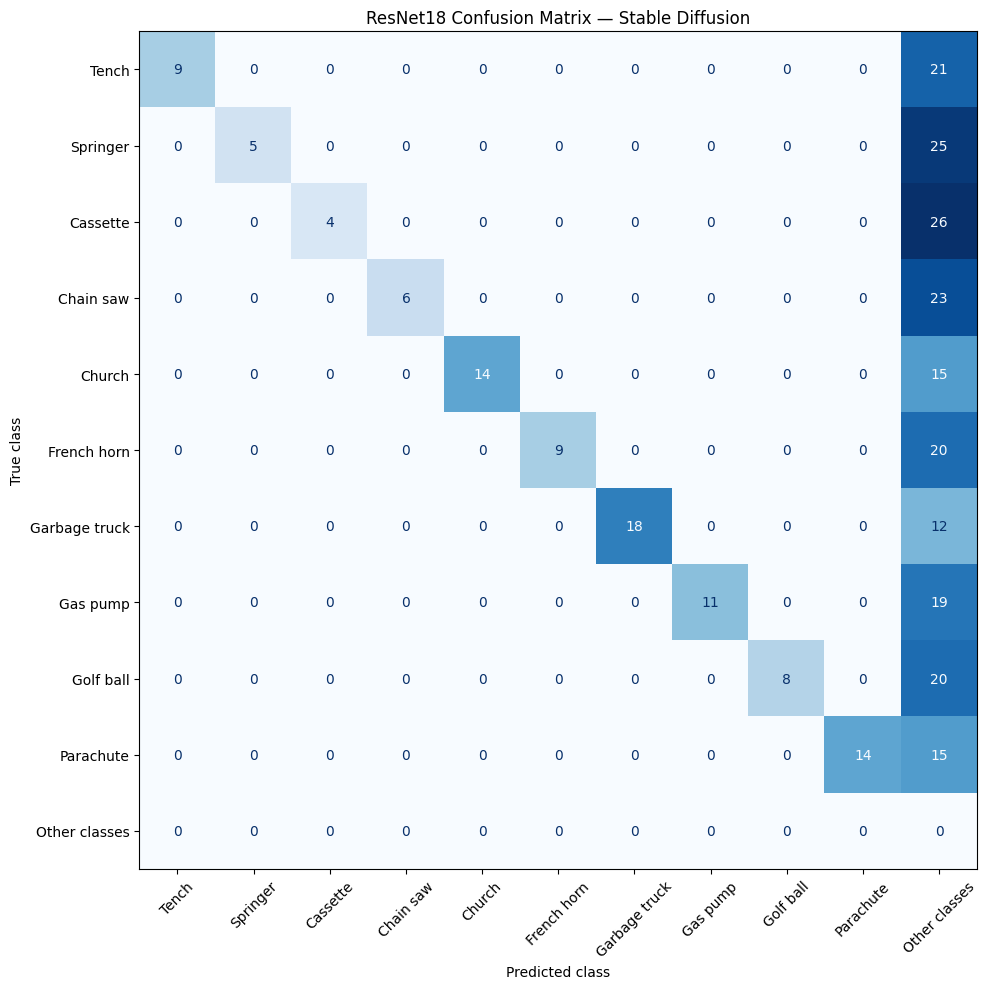


CONFUSION MATRIX SUMMARY


,Method,Samples,Correct predictions,Overall accuracy (%)
0,Original,300,242,80.67
1,OpenCV,300,55,18.33
2,AnimeGANv2,300,178,59.33
3,Stable Diffusion,294,98,33.33



Saved results to: /content/research_dataset/confusion_matrix_analysis


In [157]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

base = Path("/content/research_dataset")
out_dir = base / "confusion_matrix_analysis"
out_dir.mkdir(exist_ok=True)

files = {
    "Original": "resnet18_original_predictions.csv",
    "OpenCV": "resnet18_opencv_predictions.csv",
    "AnimeGANv2": "resnet18_animegan2_predictions.csv",
    "Stable Diffusion": "resnet18_stable_diffusion_predictions.csv",
}

class_names = {
    0: "Tench",
    217: "Springer",
    482: "Cassette",
    491: "Chain saw",
    497: "Church",
    566: "French horn",
    569: "Garbage truck",
    571: "Gas pump",
    574: "Golf ball",
    701: "Parachute",
}

class_ids = list(class_names.keys())
other_id = -1
labels = class_ids + [other_id]
display_names = [class_names[i] for i in class_ids] + ["Other classes"]

summary = []

for method, filename in files.items():
    df = pd.read_csv(base / filename)

    # Use only rows with valid true and predicted class indices.
    df = df.dropna(subset=["predicted_index"])

    # Original file contains target_index; transformed files use class_label.
    if "target_index" in df.columns:
        df["true_index"] = df["target_index"]
    else:
        label_to_id = {
            "n01440764": 0,
            "n02102040": 217,
            "n02979186": 482,
            "n03000684": 491,
            "n03028079": 497,
            "n03394916": 566,
            "n03417042": 569,
            "n03425413": 571,
            "n03445777": 574,
            "n03888257": 701,
        }
        df["true_index"] = df["class_label"].map(label_to_id)

    df = df.dropna(subset=["true_index"])
    df["true_index"] = df["true_index"].astype(int)
    df["predicted_index"] = df["predicted_index"].astype(int)

    # Map predictions outside the ten study classes to "Other classes".
    df["predicted_group"] = df["predicted_index"].where(
        df["predicted_index"].isin(class_ids), other_id
    )

    cm = confusion_matrix(
        df["true_index"],
        df["predicted_group"],
        labels=labels
    )

    fig, ax = plt.subplots(figsize=(12, 10))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=display_names
    )
    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False,
        values_format="d"
    )
    ax.set_title(f"ResNet18 Confusion Matrix — {method}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    plt.tight_layout()

    safe_name = method.lower().replace(" ", "_")
    fig.savefig(
        out_dir / f"confusion_matrix_{safe_name}.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # Overall accuracy: every wrong class prediction counts as incorrect.
    correct = (df["true_index"] == df["predicted_index"]).sum()
    total = len(df)

    summary.append({
        "Method": method,
        "Samples": total,
        "Correct predictions": int(correct),
        "Overall accuracy (%)": round(100 * correct / total, 2)
    })

    pd.DataFrame(
        cm,
        index=display_names,
        columns=display_names
    ).to_csv(out_dir / f"confusion_matrix_{safe_name}_with_other.csv")

summary_df = pd.DataFrame(summary)
summary_df.to_csv(out_dir / "confusion_matrix_summary.csv", index=False)

print("\nCONFUSION MATRIX SUMMARY")
display(summary_df)
print("\nSaved results to:", out_dir)

In [ ]:
from IPython.display import display as show_table
import pandas as pd
from pathlib import Path

base = Path("/content/research_dataset")
out_dir = base / "confusion_matrix_analysis"

summary_file = out_dir / "confusion_matrix_summary.csv"

if summary_file.exists():
    summary_df = pd.read_csv(summary_file)
    print("CONFUSION MATRIX SUMMARY")
    show_table(summary_df)
else:
    print("Summary CSV was not saved. Please rerun the corrected cell below.")

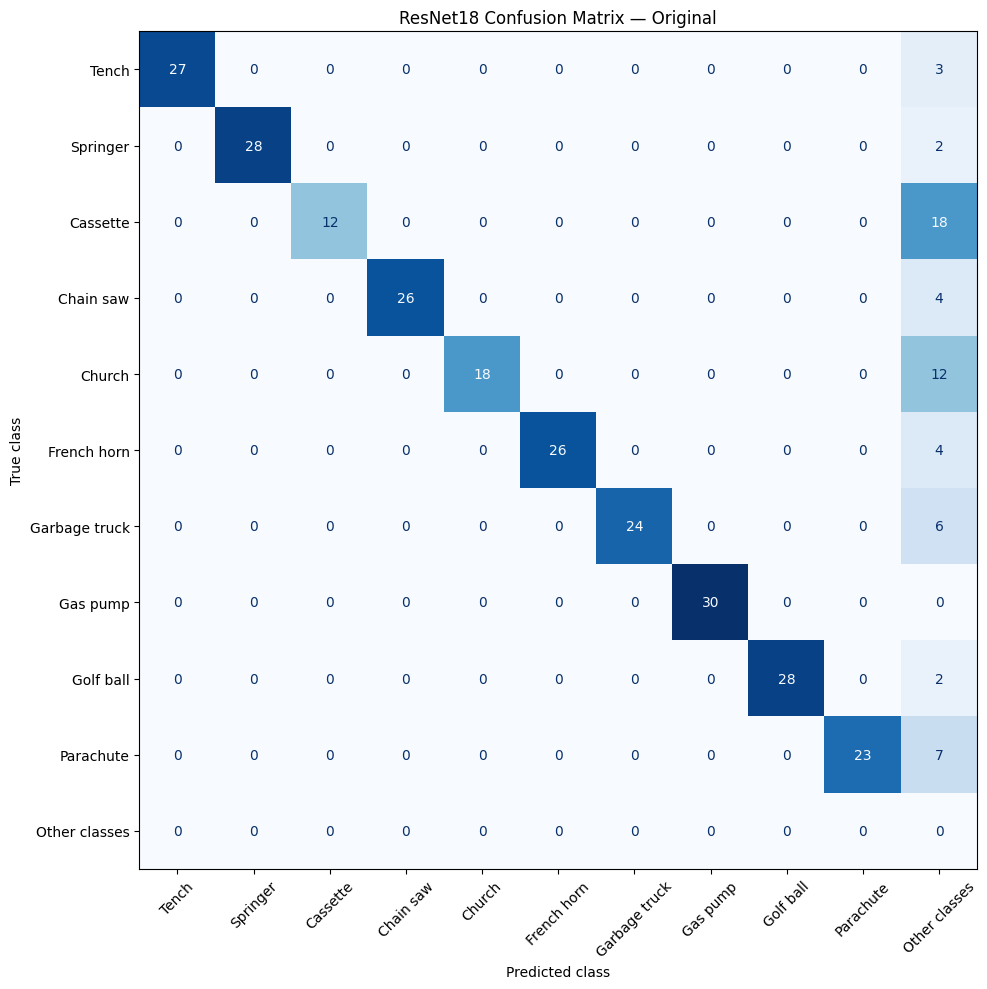

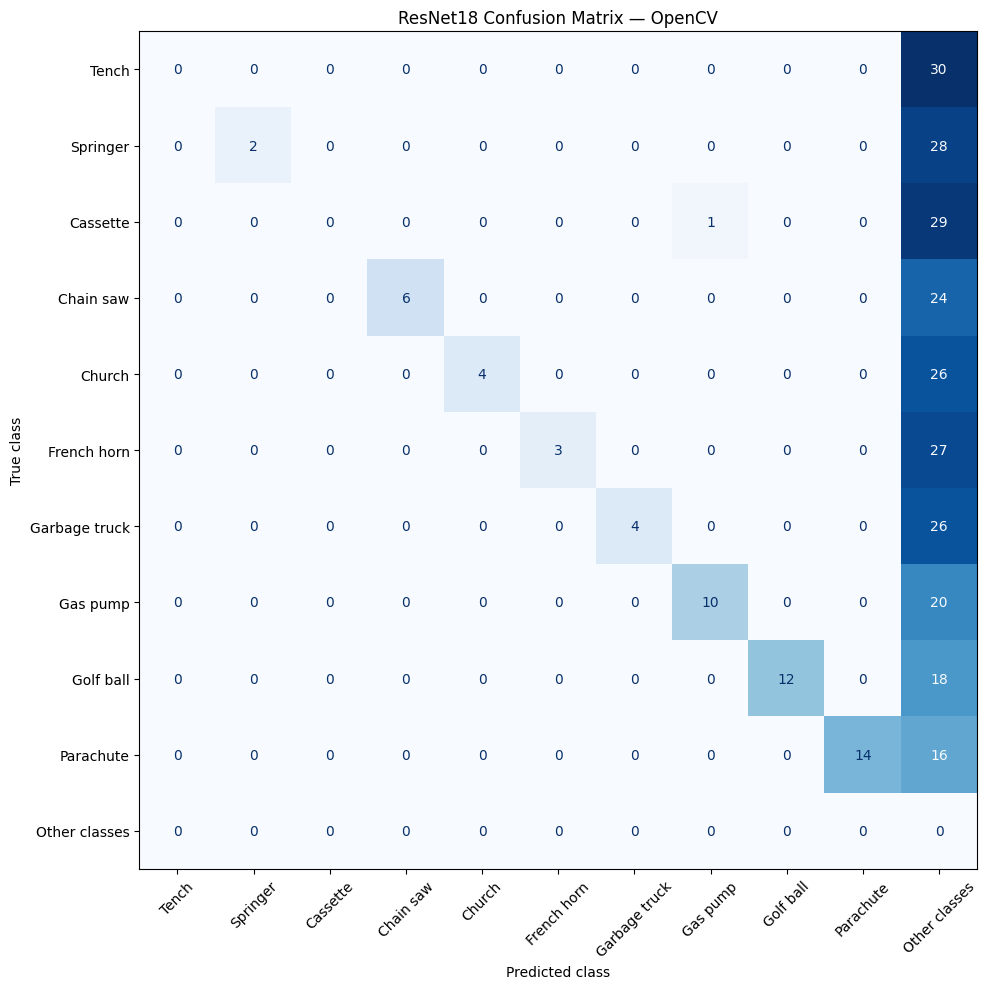

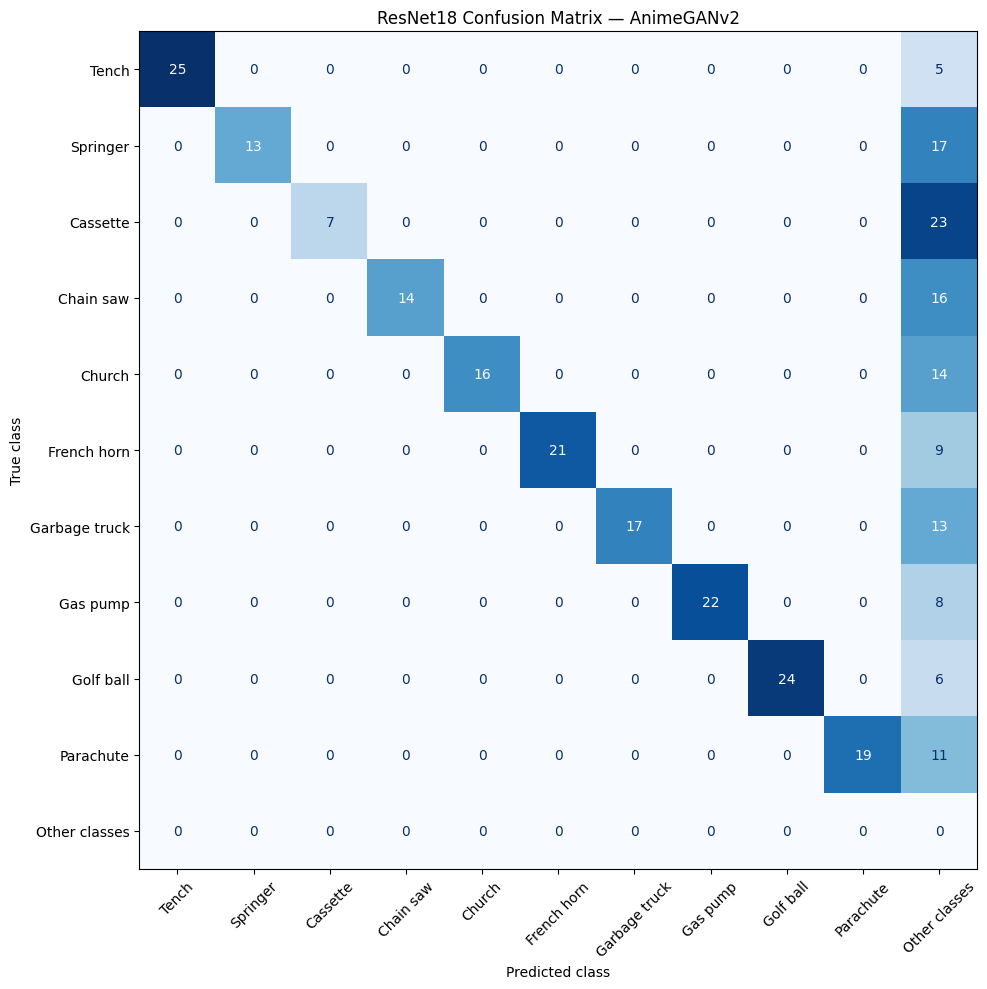

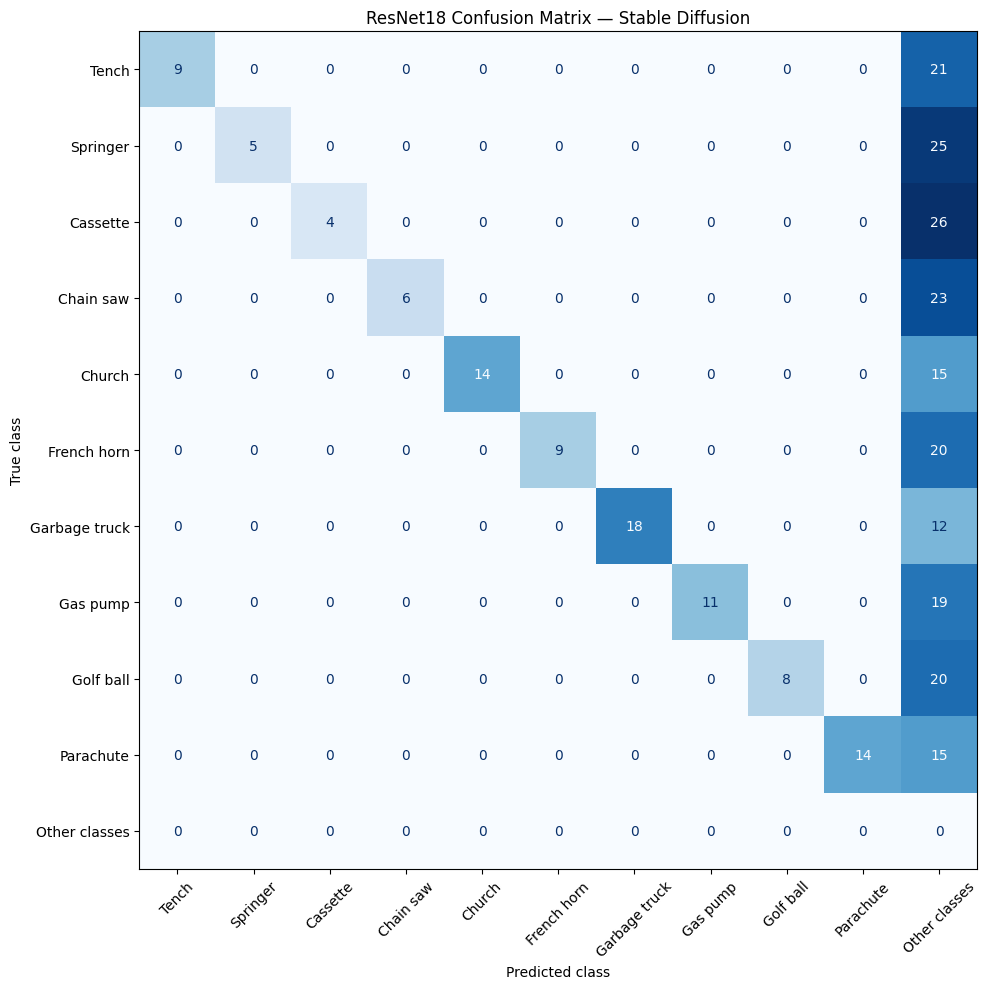

CORRECTED CONFUSION MATRIX SUMMARY
          Method  Samples  Correct predictions  Overall accuracy (%)
        Original      300                  242                 80.67
          OpenCV      300                   55                 18.33
      AnimeGANv2      300                  178                 59.33
Stable Diffusion      294                   98                 33.33


In [158]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

base = Path("/content/research_dataset")
out_dir = base / "confusion_matrix_analysis"
out_dir.mkdir(exist_ok=True)

files = {
    "Original": "resnet18_original_predictions.csv",
    "OpenCV": "resnet18_opencv_predictions.csv",
    "AnimeGANv2": "resnet18_animegan2_predictions.csv",
    "Stable Diffusion": "resnet18_stable_diffusion_predictions.csv",
}

label_to_id = {
    "n01440764": 0,
    "n02102040": 217,
    "n02979186": 482,
    "n03000684": 491,
    "n03028079": 497,
    "n03394916": 566,
    "n03417042": 569,
    "n03425413": 571,
    "n03445777": 574,
    "n03888257": 701,
}

class_names = {
    0: "Tench",
    217: "Springer",
    482: "Cassette",
    491: "Chain saw",
    497: "Church",
    566: "French horn",
    569: "Garbage truck",
    571: "Gas pump",
    574: "Golf ball",
    701: "Parachute",
}

class_ids = list(class_names.keys())
other_id = -1
labels = class_ids + [other_id]
display_names = [class_names[i] for i in class_ids] + ["Other classes"]

summary = []

for method, filename in files.items():
    df = pd.read_csv(base / filename)

    if "target_index" in df.columns:
        df["true_index"] = df["target_index"]
    else:
        df["true_index"] = df["class_label"].map(label_to_id)

    df = df.dropna(subset=["true_index", "predicted_index"]).copy()
    df["true_index"] = df["true_index"].astype(int)
    df["predicted_index"] = df["predicted_index"].astype(int)

    # Map predictions outside the ten study classes to "Other classes".
    df["predicted_group"] = df["predicted_index"].where(
        df["predicted_index"].isin(class_ids), other_id
    )

    cm = confusion_matrix(
        df["true_index"],
        df["predicted_group"],
        labels=labels
    )

    fig, ax = plt.subplots(figsize=(12, 10))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=display_names
    )
    disp.plot(ax=ax, cmap="Blues", xticks_rotation=45,
              colorbar=False, values_format="d")
    ax.set_title(f"ResNet18 Confusion Matrix — {method}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    plt.tight_layout()

    safe_name = method.lower().replace(" ", "_")
    fig.savefig(
        out_dir / f"confusion_matrix_{safe_name}_with_other.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # Overall accuracy: every wrong class prediction counts as incorrect.
    correct = (df["true_index"] == df["predicted_index"]).sum()
    total = len(df)

    summary.append({
        "Method": method,
        "Samples": total,
        "Correct predictions": int(correct),
        "Overall accuracy (%)": round(100 * correct / total, 2)
    })

    pd.DataFrame(
        cm, index=display_names, columns=display_names
    ).to_csv(out_dir / f"confusion_matrix_{safe_name}_with_other.csv")

summary_df = pd.DataFrame(summary)
summary_df.to_csv(out_dir / "confusion_matrix_summary_corrected.csv",
                  index=False)

print("CORRECTED CONFUSION MATRIX SUMMARY")
print(summary_df.to_string(index=False))

In [159]:
from pathlib import Path
import zipfile

base = Path("/content/research_dataset")
zip_path = base / "final_research_results_package.zip"

folders = [
    base / "failure_case_gallery",
    base / "confusion_matrix_analysis",
]

with zipfile.ZipFile(zip_path, "a", zipfile.ZIP_DEFLATED) as z:
    for folder in folders:
        if folder.exists():
            for file in folder.iterdir():
                if file.is_file():
                    archive_name = f"{folder.name}/{file.name}"

                    # Avoid duplicate archive entries when rerunning.
                    if archive_name not in z.namelist():
                        z.write(file, arcname=archive_name)

print("Research package updated!")
print("ZIP location:", zip_path)
print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))
print("\nIncluded analysis folders:")
for folder in folders:
    print(f"- {folder.name}: {sum(p.is_file() for p in folder.iterdir()) if folder.exists() else 0} files")

Research package updated!
ZIP location: /content/research_dataset/final_research_results_package.zip
ZIP size (MB): 18.08

Included analysis folders:
- failure_case_gallery: 4 files
- confusion_matrix_analysis: 18 files


In [160]:

from pathlib import Path
import zipfile
import os

base = Path("/content/research_dataset")
zip_path = Path("/content/complete_cartoonization_research.zip")

if not base.exists():
    raise FileNotFoundError(
        f"Research folder not found: {base}"
    )

# Create ZIP without including the ZIP itself.
file_count = 0

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for path in base.rglob("*"):
        if path.is_file() and path != zip_path:
            arcname = str(Path("cartoonization_research") / path.relative_to(base))
            z.write(path, arcname)
            file_count += 1

print("ZIP created successfully!")
print("File count:", file_count)
print("ZIP size (GB):", round(zip_path.stat().st_size / (1024**3), 2))
print("ZIP location:", zip_path)


/usr/local/lib/python3.13/dist-packages/diffusers/configuration_utils.py:172: FutureWarning: Accessing config attribute `__iter__` directly via 'StableDiffusionImg2ImgPipeline' object attribute is deprecated. Please access '__iter__' over 'StableDiffusionImg2ImgPipeline's config object instead, e.g. 'scheduler.config.__iter__'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)
/usr/local/lib/python3.13/dist-packages/diffusers/configuration_utils.py:172: FutureWarning: Accessing config attribute `__iter__` directly via 'StableDiffusionImg2ImgPipeline' object attribute is deprecated. Please access '__iter__' over 'StableDiffusionImg2ImgPipeline's config object instead, e.g. 'scheduler.config.__iter__'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)


ZIP created successfully!
File count: 19189
ZIP size (GB): 1.85
ZIP location: /content/complete_cartoonization_research.zip


In [161]:
from google.colab import files

files.download("/content/complete_cartoonization_research.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [162]:
from pathlib import Path

base = Path("/content/research_dataset")

print("Research folder exists:", base.exists())

if base.exists():
    print("Number of files:", sum(1 for p in base.rglob("*") if p.is_file()))
    print("Folder size (GB):", round(
        sum(p.stat().st_size for p in base.rglob("*") if p.is_file()) / (1024**3), 2
    ))

Research folder exists: True
Number of files: 19189
Folder size (GB): 1.86


In [163]:
from pathlib import Path
import shutil

source = Path("/content/research_dataset")
project = Path("/content/github_project")

if not source.exists():
    raise FileNotFoundError("Research folder is missing. Stop here and tell me.")

project.mkdir(parents=True, exist_ok=True)

skip_folders = {
    "opencv_cartoon",
    "animegan2_cartoon",
    "stable_diffusion_cartoon",
}

allowed_extensions = {
    ".csv", ".png", ".jpg", ".jpeg", ".pdf", ".md", ".txt", ".json"
}

copied = 0

for path in source.rglob("*"):
    if not path.is_file():
        continue

    relative = path.relative_to(source)

    if any(part in skip_folders for part in relative.parts):
        continue

    # Exclude individual dataset images and files larger than 20 MB.
    if path.stat().st_size > 20 * 1024 * 1024:
        continue

    if path.suffix.lower() not in allowed_extensions:
        continue

    target = project / "results" / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(path, target)
    copied += 1

print("Files prepared:", copied)
print("Upload folder:", project)
print("Folder size (MB):", round(
    sum(p.stat().st_size for p in project.rglob("*") if p.is_file()) / (1024**2), 2
))

Files prepared: 18285
Upload folder: /content/github_project
Folder size (MB): 688.08


In [164]:
from pathlib import Path

project = Path("/content/github_project")

readme = """# Beyond Visual Quality: Cartoonization Robustness Study

## Overview
A comparative study of OpenCV cartoonization, pretrained AnimeGANv2,
and pretrained Stable Diffusion image-to-image transformation.

## Research evaluation
- Balanced 300-image subset of ten Imagenette classes
- ResNet18 recognition performance
- SSIM and PSNR image similarity metrics
- Gaussian blur, Gaussian noise, low illumination, and JPEG compression
- Per-class results, confusion matrices, and failure-case analysis

## Limitations
The Gaussian-noise results require matched-sample verification.
Failed Stable Diffusion outputs and differences in valid sample counts
must be reported transparently. SSIM and PSNR do not measure subjective
visual appeal. Novelty has not been established as unprecedented.

## Results
See the results directory for available CSV files, charts, and reports.

## Reproducibility
The experimental notebook, source code, model requirements, and dataset
instructions should accompany this repository. Dataset and model files
may need to be obtained separately.
"""

(project / "README.md").write_text(readme, encoding="utf-8")

(project / ".gitignore").write_text(
    ".env\n*token*\n__pycache__/\n.ipynb_checkpoints/\n"
    ".venv/\nvenv/\n",
    encoding="utf-8"
)

(project / "requirements.txt").write_text(
    "torch\n"
    "torchvision\n"
    "diffusers\n"
    "transformers\n"
    "accelerate\n"
    "opencv-python\n"
    "pandas\n"
    "numpy\n"
    "matplotlib\n"
    "scikit-image\n"
    "Pillow\n",
    encoding="utf-8"
)

print("README, .gitignore, and requirements.txt created.")

README, .gitignore, and requirements.txt created.


In [165]:
import os
import getpass
import subprocess
from pathlib import Path

repo_url = "https://github.com/Karthik6-cpu/cartoonization-robustness-study.git"
repo_dir = Path("/content/cartoonization-robustness-study")

# Clone your repository.
if not repo_dir.exists():
    subprocess.run(
        ["git", "clone", repo_url, str(repo_dir)],
        check=True
    )

print("Repository cloned.")
print("Now prepare to authenticate for pushing.")

Repository cloned.
Now prepare to authenticate for pushing.


In [166]:
import getpass

GITHUB_TOKEN = getpass.getpass("Paste your GitHub token here: ")
print("Token received:", bool(GITHUB_TOKEN))

Paste your GitHub token here: ··········
Token received: True


In [167]:
from pathlib import Path

project = Path("/content/github_project")

print("Project folder exists:", project.exists())

if project.exists():
    for path in list(project.iterdir())[:20]:
        print(path.name)

Project folder exists: True
requirements.txt
results
README.md
.gitignore


In [168]:
import subprocess
from pathlib import Path

repo_url = "https://github.com/Karthik6-cpu/cartoonization-robustness-study.git"
repo_dir = Path("/content/cartoonization-robustness-study")

if not repo_dir.exists():
    subprocess.run(
        ["git", "clone", repo_url, str(repo_dir)],
        check=True
    )

print("Repository ready:", repo_dir)

Repository ready: /content/cartoonization-robustness-study


In [169]:
import shutil

for item in project.iterdir():
    destination = repo_dir / item.name

    if item.is_dir():
        if destination.exists():
            shutil.rmtree(destination)
        shutil.copytree(item, destination)
    else:
        shutil.copy2(item, destination)

print("Project files copied.")

Project files copied.


In [175]:
import os
import subprocess
import urllib.request
from pathlib import Path

# 1. Quick pre-flight check to verify if the token is valid on GitHub's API
print("Verifying GitHub Token permissions...")
req = urllib.request.Request(
    "https://api.github.com/user",
    headers={
        "Authorization": f"token {GITHUB_TOKEN}",
        "Accept": "application/vnd.github.v3+json"
    }
)
try:
    with urllib.request.urlopen(req) as response:
        import json
        user_data = json.loads(response.read().decode())
        print(f"-> Token successfully authenticated as GitHub user: {user_data.get('login')}")
except Exception as e:
    print(f"[WARNING] Token verification failed: {e}")
    print("Please verify that the GITHUB_TOKEN has not expired and is pasted correctly.")

def git(args):
    subprocess.run(
        ["git"] + args,
        cwd=repo_dir,
        check=True
    )

# Standard Git configuration
git(["config", "user.name", "Karthik6-cpu"])
git(["config", "user.email", "Karthik6-cpu@users.noreply.github.com"])
git(["add", "."])

print("\nGit status:")
git(["status", "--short"])

# Commit changes locally
subprocess.run(
    ["git", "commit", "-m", "Add cartoonization research project"],
    cwd=repo_dir,
    check=False
)

branch = subprocess.run(
    ["git", "branch", "--show-current"],
    cwd=repo_dir,
    capture_output=True,
    text=True,
    check=True
).stdout.strip() or "main"

# Configure push URL with token directly
auth_url = f"https://{GITHUB_TOKEN}@github.com/Karthik6-cpu/cartoonization-robustness-study.git"
git(["remote", "set-url", "origin", auth_url])

try:
    print(f"Pushing to branch: {branch}...")
    result = subprocess.run(
        ["git", "push", "-f", "-u", "origin", branch],
        cwd=repo_dir,
        capture_output=True,
        text=True
    )

    # Hide token from printed logs
    clean_stderr = result.stderr.replace(GITHUB_TOKEN, "***") if GITHUB_TOKEN else result.stderr
    print("STDOUT:", result.stdout)
    print("STDERR:", clean_stderr)

    if result.returncode != 0:
        raise RuntimeError(f"Git push failed with exit code {result.returncode}. Please check if your PAT has 'write' permissions for this repo.")
    else:
        print("Upload completed successfully!")
finally:
    # Revert to clean URL for safety
    safe_url = "https://github.com/Karthik6-cpu/cartoonization-robustness-study.git"
    git(["remote", "set-url", "origin", safe_url])

GITHUB_TOKEN = None

Verifying GitHub Token permissions...
-> Token successfully authenticated as GitHub user: Karthik6-cpu

Git status:
Pushing to branch: main...
STDOUT: 
STDERR: remote: Permission to Karthik6-cpu/cartoonization-robustness-study.git denied to Karthik6-cpu.
fatal: unable to access 'https://github.com/Karthik6-cpu/cartoonization-robustness-study.git/': The requested URL returned error: 403



RuntimeError: Git push failed with exit code 128. Please check if your PAT has 'write' permissions for this repo.

In [176]:
import os
import subprocess
import getpass
import tempfile
from pathlib import Path

repo = Path("/content/cartoonization-robustness-study")

if not repo.exists():
    raise FileNotFoundError(f"Repository folder not found: {repo}")

def run_git(args):
    result = subprocess.run(
        ["git"] + args,
        cwd=repo,
        capture_output=True,
        text=True
    )
    print("$ git", " ".join(args))
    print(result.stdout or result.stderr or "(no output)")
    return result

print("=== 1. Repository remote ===")
run_git(["remote", "-v"])

print("\n=== 2. Current branch ===")
run_git(["branch", "--show-current"])

print("\n=== 3. Pending changes ===")
run_git(["status", "--short"])

print("\n=== 4. Recent commit ===")
run_git(["log", "-1", "--oneline"])

print("\n=== 5. Authentication and push diagnostic ===")
token = getpass.getpass("Enter your GitHub token (hidden): ")

with tempfile.TemporaryDirectory() as temp_dir:
    helper = Path(temp_dir) / "askpass.sh"
    helper.write_text(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  *Username*) echo "Karthik6-cpu" ;;\n'
        '  *Password*) echo "$GITHUB_TOKEN" ;;\n'
        '  *) echo "" ;;\n'
        'esac\n'
    )
    helper.chmod(0o700)

    env = os.environ.copy()
    env["GITHUB_TOKEN"] = token
    env["GIT_ASKPASS"] = str(helper)
    env["GIT_TERMINAL_PROMPT"] = "0"

    result = subprocess.run(
        ["git", "push", "-u", "origin",
         subprocess.run(
             ["git", "branch", "--show-current"],
             cwd=repo, capture_output=True, text=True, check=True
         ).stdout.strip() or "main"],
        cwd=repo,
        env=env,
        capture_output=True,
        text=True
    )

    print("Exit code:", result.returncode)
    print("Git output:")
    print(result.stderr or result.stdout or "(no output)")

token = None

=== 1. Repository remote ===
$ git remote -v
origin	https://github.com/Karthik6-cpu/cartoonization-robustness-study.git (fetch)
origin	https://github.com/Karthik6-cpu/cartoonization-robustness-study.git (push)


=== 2. Current branch ===
$ git branch --show-current
main


=== 3. Pending changes ===
$ git status --short
(no output)

=== 4. Recent commit ===
$ git log -1 --oneline
5de15df7 Add cartoonization research project


=== 5. Authentication and push diagnostic ===
Enter your GitHub token (hidden): ··········
Exit code: 128
Git output:
remote: Permission to Karthik6-cpu/cartoonization-robustness-study.git denied to Karthik6-cpu.
fatal: unable to access 'https://github.com/Karthik6-cpu/cartoonization-robustness-study.git/': The requested URL returned error: 403



In [177]:
import getpass

GITHUB_TOKEN = getpass.getpass("Enter your new GitHub token: ")
print("Token received:", bool(GITHUB_TOKEN))

Enter your new GitHub token: ··········
Token received: True


In [178]:
import os
import subprocess
import tempfile
from pathlib import Path

repo = Path("/content/cartoonization-robustness-study")

if not repo.exists():
    raise FileNotFoundError("Repository folder not found. Tell me before continuing.")

with tempfile.TemporaryDirectory() as temp_dir:
    helper = Path(temp_dir) / "askpass.sh"
    helper.write_text(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  *Username*) echo "Karthik6-cpu" ;;\n'
        '  *Password*) echo "$GITHUB_TOKEN" ;;\n'
        '  *) echo "" ;;\n'
        'esac\n',
        encoding="utf-8"
    )
    helper.chmod(0o700)

    env = os.environ.copy()
    env["GITHUB_TOKEN"] = GITHUB_TOKEN
    env["GIT_ASKPASS"] = str(helper)
    env["GIT_TERMINAL_PROMPT"] = "0"

    result = subprocess.run(
        ["git", "push", "-u", "origin", "main"],
        cwd=repo,
        env=env,
        capture_output=True,
        text=True
    )

    print("Output:", result.stdout)
    print("Details:", result.stderr)
    print("Exit code:", result.returncode)

GITHUB_TOKEN = None

Output: branch 'main' set up to track 'origin/main'.

Details: To https://github.com/Karthik6-cpu/cartoonization-robustness-study.git
 * [new branch]        main -> main

Exit code: 0


In [179]:
from pathlib import Path

repo = Path("/content/cartoonization-robustness-study")

notebooks = list(repo.rglob("*.ipynb"))

print("Notebooks in GitHub upload folder:", len(notebooks))

for notebook in notebooks:
    print(notebook.relative_to(repo))

Notebooks in GitHub upload folder: 0
